# Semantic Similarity

In [1]:
!cd ../../.. && pip install -v . --group=dev --group=observability --group=analysis

Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
Processing ./.
  Running command installing build dependencies
  Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
    Obtaining dependency information for setuptools>=40.8.0 from https://files.pythonhosted.org/packages/95/9c/c510029fc6ef33a6275cd2c5d3cecd6613dfd6aa401d57c54f1c18852ccf/setuptools-84.0.0-py3-none-any.whl.metadata
    Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached setuptools-84.0.0-py3-none-any.whl (818 kB)
  ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
  torch 2.12.0 requires setuptools<82, but you have setuptools 84.0.0 which is incompatible.
  Installing build dependencies ... done
  Running command Getting requirements to build wheel
  r

In [2]:
# analysis_deps = [
#     "'apted>=1.0.3'",
#     # "'matplotlib>=3.10.9'",
#     "'rouge-score>=0.1.2'",
#     "'sentence-transformers>=5.5.1'",
#     "'nltk>=3.9.4'",
#     "'prefixspan>=0.5.2'",
#     "'scikit-learn>=1.8.0'",
#     "'tol-colors>=2.2.0'",
#     "'jupysql>=0.11.1'",
#     "'duckdb>=1.5.1'",
# ]

In [3]:
# !pip install {" ".join(analysis_deps)}

In [4]:
# !ls procedural_data || unzip -a procedural_data.zip

In [5]:
import warnings

In [6]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

In [320]:
from scipy.stats import mannwhitneyu, ttest_ind

In [7]:
from duckdb.sqltypes import VARCHAR
import duckdb as ddb

In [8]:
from sklearn.metrics.pairwise import cosine_similarity
COS_SIMILARITY_READY = False
try:
    # NOTE: this can not run natively on Intel mac anymore
    from sentence_transformers import SentenceTransformer
    COS_SIMILARITY_READY = True
except ImportError as e:
    COS_SIMILARITY_READY = False
    warnings.warn("FAILED TO IMPORT `sentence_transformers`")
    warnings.warn(str(e))
finally:
    print(f"{COS_SIMILARITY_READY=}")

COS_SIMILARITY_READY=True


In [9]:
import tol_colors as tcls

In [10]:
import itertools as itlx
import json
from pathlib import Path
import re

In [11]:
from IPython.display import display, display_markdown

In [12]:
from pprint import pprint

In [13]:
tcls.set_default_colors()
plt.set_cmap(mpl.cm.tab20)

New config line: axes.prop_cycle : cycler('color', ['4477AA', 'EE6677', '228833', 'CCBB44', '66CCEE', 'AA3377', 'BBBBBB'])
Injecting line in file '/Users/mitjaorlov/.matplotlib/matplotlibrc'


<Figure size 640x480 with 0 Axes>

In [366]:
def cohen_d(s1, s2):
    """
    Computes Cohen's d for two pandas Series / numpy arrays.
    """
    n1, n2 = len(s1), len(s2)
    m1, m2 = np.mean(s1), np.mean(s2)
    v1, v2 = np.var(s1, ddof=1), np.var(s2, ddof=1)
    
    # Pooled standard deviation
    s_pooled = np.sqrt(((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2))
    
    if s_pooled == 0:
        return np.nan
        
    return (m1 - m2) / s_pooled

## Data Loading

In [14]:
%config SqlMagic.autopandas = True
%load_ext sql
conn = ddb.connect()
%sql conn --alias duckdb

The 'toml' package isn't installed. To load settings from pyproject.toml or ~/.jupysql/config, install with: pip install toml

In [15]:
%%sql
CREATE OR REPLACE TABLE experiment_cases AS 
    FROM 'procedural_data/experiment_cases.csv';

Running query in 'duckdb'

,Count
0,716


In [16]:
%%sql
CREATE OR REPLACE TABLE experiment_case_to_nr_files AS (
    SELECT case_id, nr_data_files, count(1)
    FROM experiment_cases
    GROUP BY 1,2
);
SELECT * FROM experiment_case_to_nr_files;

Running query in 'duckdb'

,case_id,nr_data_files,count(1)
0,0,2,4
1,1,1,4
2,2,2,4
3,3,2,4
4,4,3,4
...,...,...,...
174,174,2,4
175,175,1,4
176,176,1,4
177,177,1,4


In [17]:
%%sql
CREATE TABLE IF NOT EXISTS cons_dwc_t_data_nodes AS
    SELECT * FROM './procedural_data/dwc-t_data--cons_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS cons_dwc_t_author_nodes AS
    SELECT * FROM './procedural_data/dwc-t_author--cons_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS cons_eml_data_nodes AS
    SELECT * FROM './procedural_data/eml_data--cons_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS cons_eml_author_nodes AS
    SELECT * FROM './procedural_data/eml_author--cons_node_info_groups.csv';

Running query in 'duckdb'

,Count
0,5934


In [18]:
%%sql
CREATE TABLE IF NOT EXISTS gt_dwc_t_data_nodes AS
    SELECT * FROM './procedural_data/dwc-t_data--gt_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS gt_dwc_t_author_nodes AS
    SELECT * FROM './procedural_data/dwc-t_author--gt_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS gt_eml_data_nodes AS
    SELECT * FROM './procedural_data/eml_data--gt_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS gt_eml_author_nodes AS
    SELECT * FROM './procedural_data/eml_author--gt_node_info_groups.csv';

Running query in 'duckdb'

,Count
0,53666


In [19]:
display(conn.query("DESCRIBE gt_dwc_t_data_nodes;"))
display(conn.query("DESCRIBE gt_dwc_t_author_nodes;"))
display(conn.query("DESCRIBE gt_eml_data_nodes;"))
display(conn.query("DESCRIBE gt_eml_author_nodes;"))

┌──────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│   column_name    │ column_type │  null   │   key   │ default │  extra  │
│     varchar      │   varchar   │ varchar │ varchar │ varchar │ varchar │
├──────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ column00         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ case_id          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ tag              │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ depth            │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ degree           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ is_leaf          │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes       │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes_count │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ has_attributes   │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ text             │ VARC

┌──────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│   column_name    │ column_type │  null   │   key   │ default │  extra  │
│     varchar      │   varchar   │ varchar │ varchar │ varchar │ varchar │
├──────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ column00         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ case_id          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ tag              │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ depth            │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ degree           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ is_leaf          │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes       │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes_count │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ has_attributes   │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ text             │ VARC

┌──────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│   column_name    │ column_type │  null   │   key   │ default │  extra  │
│     varchar      │   varchar   │ varchar │ varchar │ varchar │ varchar │
├──────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ column00         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ case_id          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ tag              │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ depth            │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ degree           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ is_leaf          │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes       │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes_count │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ has_attributes   │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ text             │ VARC

┌──────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│   column_name    │ column_type │  null   │   key   │ default │  extra  │
│     varchar      │   varchar   │ varchar │ varchar │ varchar │ varchar │
├──────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ column00         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ case_id          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ tag              │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ depth            │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ degree           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ is_leaf          │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes       │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes_count │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ has_attributes   │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ text             │ VARC

In [20]:
%%sql
SELECT COUNT(1) FROM cons_dwc_t_data_nodes;

Running query in 'duckdb'

,count(1)
0,8552


In [21]:
%%sql
SELECT COUNT(1) FROM cons_dwc_t_author_nodes;

Running query in 'duckdb'

,count(1)
0,8562


In [22]:
%%sql
SELECT COUNT(1) FROM cons_eml_data_nodes;

Running query in 'duckdb'

,count(1)
0,6369


In [23]:
%%sql
SELECT COUNT(1) FROM cons_eml_author_nodes;

Running query in 'duckdb'

,count(1)
0,5934


## By Shared Ancestor Paths

### Confusion Matrix

In [24]:
%%sql
CREATE TABLE IF NOT EXISTS shared_cons_gt_dwc_t_data_nodes AS (
    SELECT  *,
            c.text as cons_text, g.text as gt_text,
            c.has_text as cons_has_text, g.has_text as gt_has_text,
            c.attributes as cons_attributes, g.attributes as gt_attributes,
            c.has_attributes as cons_has_attributes, g.has_attributes as gt_has_attributes
    FROM cons_dwc_t_data_nodes AS c
    JOIN gt_dwc_t_data_nodes AS g
        ON  c.path = g.path
        AND c.case_id = g.case_id
);

Running query in 'duckdb'

,Count
0,8283


In [25]:
%sql SELECT COUNT(1) FROM shared_cons_gt_dwc_t_data_nodes;

Running query in 'duckdb'

,count(1)
0,8283


In [26]:
%%sql
CREATE TABLE IF NOT EXISTS shared_cons_gt_dwc_t_author_nodes AS (
    SELECT  *,
            c.text as cons_text, g.text as gt_text,
            c.has_text as cons_has_text, g.has_text as gt_has_text,
            c.attributes as cons_attributes, g.attributes as gt_attributes,
            c.has_attributes as cons_has_attributes, g.has_attributes as gt_has_attributes
    FROM cons_dwc_t_author_nodes AS c
    JOIN gt_dwc_t_author_nodes AS g
        ON  c.path = g.path
        AND c.case_id = g.case_id
);

Running query in 'duckdb'

,Count
0,8254


In [27]:
%%sql
CREATE TABLE IF NOT EXISTS shared_cons_gt_eml_data_nodes AS (
    SELECT  *,
            c.text as cons_text, g.text as gt_text,
            c.has_text as cons_has_text, g.has_text as gt_has_text,
            c.attributes as cons_attributes, g.attributes as gt_attributes,
            c.has_attributes as cons_has_attributes, g.has_attributes as gt_has_attributes
    FROM cons_eml_data_nodes AS c
    JOIN gt_eml_data_nodes AS g
        ON  c.path = g.path
        AND c.case_id = g.case_id
);

Running query in 'duckdb'

,Count
0,2844


In [28]:
%%sql
CREATE TABLE IF NOT EXISTS shared_cons_gt_eml_author_nodes AS (
    SELECT  *,
            c.text as cons_text, g.text as gt_text,
            c.has_text as cons_has_text, g.has_text as gt_has_text,
            c.attributes as cons_attributes, g.attributes as gt_attributes,
            c.has_attributes as cons_has_attributes, g.has_attributes as gt_has_attributes
    FROM cons_eml_author_nodes AS c
    JOIN gt_eml_author_nodes AS g
        ON  c.path = g.path
        AND c.case_id = g.case_id
);

Running query in 'duckdb'

,Count
0,2760


#### Reporting Confusion Matrix

In [29]:
# text

In [30]:
%%sql
SELECT COUNT(1), cons_has_text, gt_has_text
FROM shared_cons_gt_dwc_t_data_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_text,gt_has_text
0,8016,False,False
1,267,True,True


In [31]:
%%sql
SELECT COUNT(1), cons_has_text, gt_has_text, tag
FROM shared_cons_gt_dwc_t_data_nodes
WHERE cons_has_text OR gt_has_text
GROUP BY 2,3,4

Running query in 'duckdb'

,count(1),cons_has_text,gt_has_text,tag
0,267,True,True,{http://rs.tdwg.org/dwc/text/}location


In [32]:
%%sql
SELECT
    (SELECT COUNT(1) FROM shared_cons_gt_dwc_t_data_nodes WHERE cons_has_text AND gt_has_text)
    / (SELECT COUNT(1) FROM shared_cons_gt_dwc_t_data_nodes)
    * 100 AS tp_percentage;

Running query in 'duckdb'

,tp_percentage
0,3.22347


In [33]:
%%sql
SELECT COUNT(1), cons_has_text, gt_has_text
FROM shared_cons_gt_dwc_t_author_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_text,gt_has_text
0,7984,False,False
1,270,True,True


In [34]:
%%sql
SELECT COUNT(1), cons_has_text, gt_has_text, tag
FROM shared_cons_gt_dwc_t_author_nodes
WHERE cons_has_text OR gt_has_text
GROUP BY 2,3,4

Running query in 'duckdb'

,count(1),cons_has_text,gt_has_text,tag
0,270,True,True,{http://rs.tdwg.org/dwc/text/}location


In [35]:
%%sql
SELECT
    (SELECT COUNT(1) FROM shared_cons_gt_dwc_t_author_nodes WHERE cons_has_text AND gt_has_text)
    / (SELECT COUNT(1) FROM shared_cons_gt_dwc_t_author_nodes)
    * 100 AS tp_percentage;

Running query in 'duckdb'

,tp_percentage
0,3.271141


In [36]:
%%sql
SELECT COUNT(1), cons_has_text, gt_has_text
FROM shared_cons_gt_eml_data_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_text,gt_has_text
0,1768,False,False
1,864,True,True
2,212,True,False


In [37]:
%%sql
SELECT COUNT(1), cons_has_text, gt_has_text, tag
FROM shared_cons_gt_eml_data_nodes
GROUP BY 2,3,4
ORDER BY gt_has_text

Running query in 'duckdb'

,count(1),cons_has_text,gt_has_text,tag
0,150,False,False,dataset
1,11,False,False,descriptor
2,141,True,False,para
3,102,False,False,project
4,74,False,False,personnel
5,75,False,False,funding
6,145,False,False,additionalMetadata
7,76,False,False,qualityControl
8,1,False,False,temporalCoverage
9,150,False,False,{https://eml.ecoinformatics.org/eml-2.2.0}eml


In [38]:
%%sql
SELECT COUNT(1), cons_has_text, gt_has_text, tag
FROM shared_cons_gt_eml_data_nodes
WHERE cons_has_text AND gt_has_text
GROUP BY 2,3,4
ORDER BY tag

Running query in 'duckdb'

,count(1),cons_has_text,gt_has_text,tag
0,2,True,True,calendarDate
1,11,True,True,descriptorValue
2,1,True,True,electronicMailAddress
3,1,True,True,geographicDescription
4,2,True,True,givenName
5,145,True,True,maintenanceUpdateFrequency
6,257,True,True,para
7,67,True,True,role
8,107,True,True,surName
9,251,True,True,title


In [39]:
%%sql
SELECT
    (SELECT COUNT(1) FROM shared_cons_gt_eml_data_nodes WHERE cons_has_text AND gt_has_text)
    / (SELECT COUNT(1) FROM shared_cons_gt_eml_data_nodes)
    * 100 AS tp_percentage,
    (SELECT COUNT(1) FROM shared_cons_gt_eml_data_nodes WHERE (NOT cons_has_text) AND (NOT gt_has_text))
    / (SELECT COUNT(1) FROM shared_cons_gt_eml_data_nodes)
    * 100 AS tn_percentage,
    (SELECT COUNT(1) FROM shared_cons_gt_eml_data_nodes WHERE cons_has_text)
    / (SELECT COUNT(1) FROM shared_cons_gt_eml_data_nodes)
    * 100 AS cons_t_percentage,
    ;

Running query in 'duckdb'

,tp_percentage,tn_percentage,cons_t_percentage
0,30.379747,62.165963,37.834037


In [40]:
%%sql
SELECT COUNT(1), cons_has_text, gt_has_text
FROM shared_cons_gt_eml_author_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_text,gt_has_text
0,1704,False,False
1,3,False,True
2,834,True,True
3,219,True,False


In [41]:
%%sql
SELECT COUNT(1), cons_has_text, gt_has_text, tag
FROM shared_cons_gt_eml_author_nodes
GROUP BY 2,3,4
ORDER BY gt_has_text

Running query in 'duckdb'

,count(1),cons_has_text,gt_has_text,tag
0,1,False,False,intellectualRights
1,125,False,False,methods
2,1,False,False,designDescription
3,97,False,False,methodStep
4,148,False,False,dataset
5,58,False,False,studyAreaDescription
6,30,False,False,creator
7,144,False,False,additionalMetadata
8,68,False,False,metadata
9,143,False,False,maintenance


In [42]:
%%sql
SELECT COUNT(1), cons_has_text, gt_has_text, tag
FROM shared_cons_gt_eml_author_nodes
WHERE cons_has_text AND gt_has_text
GROUP BY 2,3,4
ORDER BY tag

Running query in 'duckdb'

,count(1),cons_has_text,gt_has_text,tag
0,11,True,True,descriptorValue
1,1,True,True,electronicMailAddress
2,2,True,True,geographicDescription
3,2,True,True,givenName
4,142,True,True,maintenanceUpdateFrequency
5,253,True,True,para
6,63,True,True,role
7,96,True,True,surName
8,247,True,True,title
9,17,True,True,userId


In [43]:
%%sql
SELECT
    (SELECT COUNT(1) FROM shared_cons_gt_eml_author_nodes WHERE cons_has_text AND gt_has_text)
    / (SELECT COUNT(1) FROM shared_cons_gt_eml_author_nodes)
    * 100 AS tp_percentage,
    (SELECT COUNT(1) FROM shared_cons_gt_eml_author_nodes WHERE (NOT cons_has_text) AND (NOT gt_has_text))
    / (SELECT COUNT(1) FROM shared_cons_gt_eml_author_nodes)
    * 100 AS tn_percentage,
    (SELECT COUNT(1) FROM shared_cons_gt_eml_author_nodes WHERE cons_has_text)
    / (SELECT COUNT(1) FROM shared_cons_gt_eml_author_nodes)
    * 100 AS cons_t_percentage,
    ;

Running query in 'duckdb'

,tp_percentage,tn_percentage,cons_t_percentage
0,30.217391,61.73913,38.152174


In [44]:
# attributes

In [45]:
%%sql
SELECT COUNT(1), cons_has_attributes, gt_has_attributes
FROM shared_cons_gt_dwc_t_data_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_attributes,gt_has_attributes
0,534,False,False
1,3,True,False
2,7746,True,True


In [46]:
%%sql
SELECT
    (SELECT COUNT(1) FROM shared_cons_gt_dwc_t_data_nodes WHERE cons_has_attributes AND gt_has_attributes)
    / (SELECT COUNT(1) FROM shared_cons_gt_dwc_t_data_nodes)
    * 100 AS tp_percentage,
    (
        SELECT COUNT(1) FROM shared_cons_gt_dwc_t_data_nodes WHERE cons_has_attributes AND gt_has_attributes
    ) as tp_count,
    (SELECT COUNT(1) FROM shared_cons_gt_dwc_t_data_nodes WHERE (NOT cons_has_attributes) AND (NOT gt_has_attributes))
    / (SELECT COUNT(1) FROM shared_cons_gt_dwc_t_data_nodes)
    * 100 AS tn_percentage,
;

Running query in 'duckdb'

,tp_percentage,tp_count,tn_percentage
0,93.516842,7746,6.44694


In [47]:
%%sql
SELECT COUNT(1), cons_has_attributes, gt_has_attributes
FROM shared_cons_gt_dwc_t_author_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_attributes,gt_has_attributes
0,3,True,False
1,7711,True,True
2,540,False,False


In [48]:
%%sql
SELECT
    (SELECT COUNT(1) FROM shared_cons_gt_dwc_t_author_nodes WHERE cons_has_attributes AND gt_has_attributes)
    / (SELECT COUNT(1) FROM shared_cons_gt_dwc_t_author_nodes)
    * 100 AS tp_percentage,

    (SELECT COUNT(1) FROM shared_cons_gt_dwc_t_author_nodes WHERE cons_has_attributes AND gt_has_attributes) as tp_count
;

Running query in 'duckdb'

,tp_percentage,tp_count
0,93.421371,7711


In [49]:
%%sql
SELECT COUNT(1), cons_has_attributes, gt_has_attributes
FROM shared_cons_gt_eml_data_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_attributes,gt_has_attributes
0,2451,False,False
1,15,True,False
2,198,False,True
3,180,True,True


In [50]:
%%sql
SELECT
    (SELECT COUNT(1) FROM shared_cons_gt_eml_data_nodes WHERE cons_has_attributes AND gt_has_attributes)
    / (SELECT COUNT(1) FROM shared_cons_gt_eml_data_nodes)
    * 100 AS tp_percentage,

    (SELECT COUNT(1) FROM shared_cons_gt_eml_data_nodes WHERE cons_has_attributes AND gt_has_attributes) as tp_count
;

Running query in 'duckdb'

,tp_percentage,tp_count
0,6.329114,180


In [51]:
%%sql
SELECT COUNT(1), cons_has_attributes, gt_has_attributes
FROM shared_cons_gt_eml_author_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_attributes,gt_has_attributes
0,16,True,False
1,197,False,True
2,176,True,True
3,2371,False,False


In [52]:
%%sql
SELECT
    (SELECT COUNT(1) FROM shared_cons_gt_eml_author_nodes WHERE cons_has_attributes AND gt_has_attributes)
    / (SELECT COUNT(1) FROM shared_cons_gt_eml_author_nodes)
    * 100 AS tp_percentage, 
    
    (SELECT COUNT(1) FROM shared_cons_gt_eml_author_nodes WHERE cons_has_attributes AND gt_has_attributes) AS tp_count
;

Running query in 'duckdb'

,tp_percentage,tp_count
0,6.376812,176


### Computing Similarities

In [53]:
if COS_SIMILARITY_READY:
    sentence_transformer_model = SentenceTransformer('all-MiniLM-L6-v2')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [54]:
def compute_cos_similarity(v1: str, v2:str) -> float | None:
    if v1 == v2:
        return 1
    if ("not-derived-" in v1) or ("not-derived-" in v2):
        return -1
    if not v1 or not v2:
        return None

    emb1 = sentence_transformer_model.encode(v1).reshape(1,-1)
    emb2 = sentence_transformer_model.encode(v2).reshape(1,-1)

    return cosine_similarity(emb1, emb2)[0][0].item()

In [55]:
compute_cos_similarity("{'index': '21', 'term': 'http://rs.tdwg.org/dwc/terms/kingdom'}", "{'index': '21', 'term': 'http://rs.tdwg.org/dwc/terms/kingdom'}")

1

In [56]:
compute_cos_similarity("{'index': 'not-derived-1', 'term': 'http://rs.tdwg.org/dwc/terms/kingdom'}", "{'index': '21', 'term': 'http://rs.tdwg.org/dwc/terms/kingdom'}")

-1

In [57]:
compute_cos_similarity("not-derived-1", "http://rs.tdwg.org/dwc/terms/kingdom")

-1

In [58]:
try:
    conn.remove_function("cos_sim")
except:
    print("does not exist")
conn.create_function("cos_sim", compute_cos_similarity)

does not exist


In [59]:
# def wrap_text_struct(v: str) -> str:
#     return json.dumps({"text": v})

In [60]:
# ddb.create_function("wrap_text_struct", wrap_text_struct)

In [61]:
%%time
cons_gt_dwc_t_data_nodes_cos_sim_text = conn.query("""
SELECT
    case_id, path, tag,
    cons_text, gt_text,
    cos_sim(cons_text, gt_text) AS cos_sim_text,
FROM shared_cons_gt_dwc_t_data_nodes
WHERE cons_has_text AND gt_has_text
""").to_df()

CPU times: user 396 ms, sys: 67.5 ms, total: 464 ms
Wall time: 672 ms


In [62]:
%%time
cons_gt_dwc_t_data_nodes_cos_sim_attributes = conn.query("""
SELECT
    case_id, path, tag, 
    cons_attributes, gt_attributes,
    cos_sim(cons_attributes, gt_attributes) AS cos_sim_attributes,
FROM shared_cons_gt_dwc_t_data_nodes
WHERE cons_has_attributes AND gt_has_attributes
""").to_df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 13.9 s, sys: 2.14 s, total: 16.1 s
Wall time: 24.5 s


In [63]:
display(cons_gt_dwc_t_data_nodes_cos_sim_text.describe(include="all"))
display(cons_gt_dwc_t_data_nodes_cos_sim_attributes.describe(include="all"))

,case_id,path,tag,cons_text,gt_text,cos_sim_text
count,267.000000,267,267,267,267,267.000000
unique,NaN,5,1,21,21,NaN
top,NaN,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,occurrence.txt,NaN
freq,NaN,174,267,165,165,NaN
mean,87.707865,NaN,NaN,NaN,NaN,0.903594
std,52.224617,NaN,NaN,NaN,NaN,0.181778
min,0.000000,NaN,NaN,NaN,NaN,0.257896
25%,41.500000,NaN,NaN,NaN,NaN,1.000000
50%,86.000000,NaN,NaN,NaN,NaN,1.000000
75%,132.000000,NaN,NaN,NaN,NaN,1.000000


,case_id,path,tag,cons_attributes,gt_attributes,cos_sim_attributes
count,7746.000000,7746,7746,7746,7746,7746.000000
unique,NaN,322,6,2867,2807,NaN
top,NaN,{http://rs.tdwg.org/dwc/text/}core,{http://rs.tdwg.org/dwc/text/}field,"{""index"": ""0""}","{""index"": ""0""}",NaN
freq,NaN,174,7042,207,266,NaN
mean,88.934418,NaN,NaN,NaN,NaN,0.914263
std,51.635214,NaN,NaN,NaN,NaN,0.237642
min,0.000000,NaN,NaN,NaN,NaN,-1.000000
25%,43.000000,NaN,NaN,NaN,NaN,0.867690
50%,91.000000,NaN,NaN,NaN,NaN,1.000000
75%,134.000000,NaN,NaN,NaN,NaN,1.000000


In [64]:
display(cons_gt_dwc_t_data_nodes_cos_sim_text)
display(cons_gt_dwc_t_data_nodes_cos_sim_attributes)

,case_id,path,tag,cons_text,gt_text,cos_sim_text
0,0,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,event.txt,0.64855
1,0,{http://rs.tdwg.org/dwc/text/}extension/{http:...,{http://rs.tdwg.org/dwc/text/}location,event.txt,occurrence.txt,0.64855
2,1,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,occurrence.txt,1.00000
3,10,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,occurrence.txt,1.00000
4,100,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,occurrence.txt,1.00000
...,...,...,...,...,...,...
262,98,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,{http://rs.tdwg.org/dwc/text/}location,event.txt,event.txt,1.00000
263,98,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,occurrence.txt,1.00000
264,98,{http://rs.tdwg.org/dwc/text/}extension[2]/{ht...,{http://rs.tdwg.org/dwc/text/}location,extendedmeasurementorfact.txt,extendedmeasurementorfact.txt,1.00000
265,99,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,{http://rs.tdwg.org/dwc/text/}location,event.txt,event.txt,1.00000


,case_id,path,tag,cons_attributes,gt_attributes,cos_sim_attributes
0,0,.,{http://rs.tdwg.org/dwc/text/}archive,"{""metadata"": ""meta.xml""}","{""metadata"": ""eml.xml""}",0.771236
1,0,{http://rs.tdwg.org/dwc/text/}core,{http://rs.tdwg.org/dwc/text/}core,"{""rowType"": ""http://rs.tdwg.org/dwc/terms/Occu...","{""encoding"": ""UTF-8"", ""fieldsTerminatedBy"": ""\...",0.888643
2,0,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,{http://rs.tdwg.org/dwc/text/}id,"{""index"": ""0""}","{""index"": ""0""}",1.000000
3,0,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,{http://rs.tdwg.org/dwc/text/}field,"{""index"": ""1"", ""term"": ""http://rs.tdwg.org/dwc...","{""index"": ""1"", ""term"": ""http://rs.tdwg.org/dwc...",0.862888
4,0,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,{http://rs.tdwg.org/dwc/text/}field,"{""index"": ""2"", ""term"": ""http://rs.tdwg.org/dwc...","{""index"": ""2"", ""term"": ""http://rs.tdwg.org/dwc...",0.780675
...,...,...,...,...,...,...
7741,99,{http://rs.tdwg.org/dwc/text/}extension/{http:...,{http://rs.tdwg.org/dwc/text/}field,"{""index"": ""26"", ""term"": ""http://rs.tdwg.org/dw...","{""index"": ""26"", ""term"": ""http://rs.tdwg.org/dw...",1.000000
7742,99,{http://rs.tdwg.org/dwc/text/}extension/{http:...,{http://rs.tdwg.org/dwc/text/}field,"{""index"": ""27"", ""term"": ""http://rs.tdwg.org/dw...","{""index"": ""27"", ""term"": ""http://rs.tdwg.org/dw...",1.000000
7743,99,{http://rs.tdwg.org/dwc/text/}extension/{http:...,{http://rs.tdwg.org/dwc/text/}field,"{""index"": ""28"", ""term"": ""http://rs.tdwg.org/dw...","{""index"": ""28"", ""term"": ""http://rs.tdwg.org/dw...",1.000000
7744,99,{http://rs.tdwg.org/dwc/text/}extension/{http:...,{http://rs.tdwg.org/dwc/text/}field,"{""index"": ""29"", ""term"": ""http://rs.tdwg.org/dw...","{""index"": ""29"", ""term"": ""http://rs.tdwg.org/dw...",1.000000


<Axes: ylabel='Frequency'>

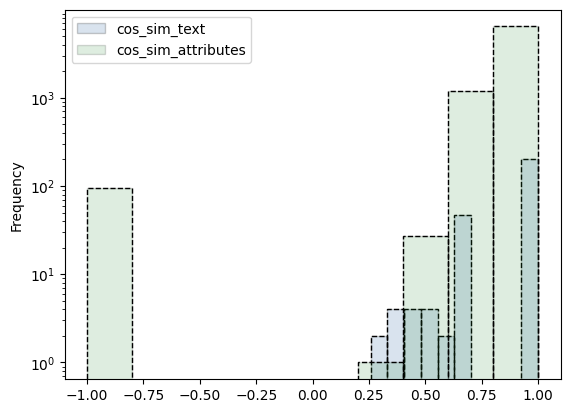

In [65]:
cons_gt_dwc_t_data_nodes_cos_sim_text["cos_sim_text"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=True)
cons_gt_dwc_t_data_nodes_cos_sim_text["cos_sim_text"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")
cons_gt_dwc_t_data_nodes_cos_sim_attributes["cos_sim_attributes"].plot.hist(alpha=0.15, ls="-", lw=1, edgecolor="k", legend=True, log=True)
cons_gt_dwc_t_data_nodes_cos_sim_attributes["cos_sim_attributes"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")

In [66]:
%%time
cons_gt_dwc_t_author_nodes_cos_sim_text = conn.query("""
SELECT
    case_id, path, tag,
    cons_text, gt_text,
    cos_sim(cons_text, gt_text) AS cos_sim_text,
FROM shared_cons_gt_dwc_t_author_nodes
WHERE cons_has_text AND gt_has_text
""").to_df()

cons_gt_dwc_t_author_nodes_cos_sim_attributes = conn.query("""
SELECT
    case_id, path, tag,
    cons_attributes, gt_attributes,
    cos_sim(cons_attributes, gt_attributes) AS cos_sim_attributes,
FROM shared_cons_gt_dwc_t_author_nodes
WHERE cons_has_attributes AND gt_has_attributes
""").to_df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 1min 1s, sys: 14.1 s, total: 1min 16s
Wall time: 56.1 s


In [67]:
%%time
cons_gt_eml_data_nodes_cos_sim_text = conn.query("""
SELECT
    case_id, path, tag,
    cons_text, gt_text,
    cos_sim(cons_text, gt_text) AS cos_sim_text,
FROM shared_cons_gt_eml_data_nodes
WHERE cons_has_text AND gt_has_text
""").to_df()

cons_gt_eml_data_nodes_cos_sim_attributes = conn.query("""
SELECT
    case_id, path, tag,
    cons_attributes, gt_attributes,
    cos_sim(cons_attributes, gt_attributes) AS cos_sim_attributes,
FROM shared_cons_gt_eml_data_nodes
WHERE cons_has_attributes AND gt_has_attributes
""").to_df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 5.81 s, sys: 1.11 s, total: 6.92 s
Wall time: 7.93 s


In [68]:
%%time
cons_gt_eml_author_nodes_cos_sim_text = conn.query("""
SELECT
    case_id, path, tag,
    cons_text, gt_text,
    cos_sim(cons_text, gt_text) AS cos_sim_text,
FROM shared_cons_gt_eml_author_nodes
WHERE cons_has_text AND gt_has_text
""").to_df()

cons_gt_eml_author_nodes_cos_sim_attributes = conn.query("""
SELECT
    case_id, path, tag,
    cons_attributes, gt_attributes,
    cos_sim(cons_attributes, gt_attributes) AS cos_sim_attributes,
FROM shared_cons_gt_eml_author_nodes
WHERE cons_has_attributes AND gt_has_attributes
""").to_df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 12 s, sys: 2.42 s, total: 14.4 s
Wall time: 10.9 s


#### Report Similarities

In [69]:
display(cons_gt_dwc_t_data_nodes_cos_sim_text.describe(include="all"))
display(cons_gt_dwc_t_data_nodes_cos_sim_text[
    cons_gt_dwc_t_data_nodes_cos_sim_text["cos_sim_text"] < 0.9
].describe(include="all"))

print("----")

display(cons_gt_dwc_t_data_nodes_cos_sim_attributes.describe(include="all"))
display(cons_gt_dwc_t_data_nodes_cos_sim_attributes[
    cons_gt_dwc_t_data_nodes_cos_sim_attributes["cos_sim_attributes"] < 0.9
].describe(include="all"))

,case_id,path,tag,cons_text,gt_text,cos_sim_text
count,267.000000,267,267,267,267,267.000000
unique,NaN,5,1,21,21,NaN
top,NaN,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,occurrence.txt,NaN
freq,NaN,174,267,165,165,NaN
mean,87.707865,NaN,NaN,NaN,NaN,0.903594
std,52.224617,NaN,NaN,NaN,NaN,0.181778
min,0.000000,NaN,NaN,NaN,NaN,0.257896
25%,41.500000,NaN,NaN,NaN,NaN,1.000000
50%,86.000000,NaN,NaN,NaN,NaN,1.000000
75%,132.000000,NaN,NaN,NaN,NaN,1.000000


,case_id,path,tag,cons_text,gt_text,cos_sim_text
count,63.000000,63,63,63,63,63.000000
unique,NaN,5,1,11,11,NaN
top,NaN,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,occurrence.txt,NaN
freq,NaN,25,63,28,28,NaN
mean,83.174603,NaN,NaN,NaN,NaN,0.591422
std,53.444436,NaN,NaN,NaN,NaN,0.110282
min,0.000000,NaN,NaN,NaN,NaN,0.257896
25%,42.000000,NaN,NaN,NaN,NaN,0.616079
50%,79.000000,NaN,NaN,NaN,NaN,0.648550
75%,127.000000,NaN,NaN,NaN,NaN,0.648550


----


,case_id,path,tag,cons_attributes,gt_attributes,cos_sim_attributes
count,7746.000000,7746,7746,7746,7746,7746.000000
unique,NaN,322,6,2867,2807,NaN
top,NaN,{http://rs.tdwg.org/dwc/text/}core,{http://rs.tdwg.org/dwc/text/}field,"{""index"": ""0""}","{""index"": ""0""}",NaN
freq,NaN,174,7042,207,266,NaN
mean,88.934418,NaN,NaN,NaN,NaN,0.914263
std,51.635214,NaN,NaN,NaN,NaN,0.237642
min,0.000000,NaN,NaN,NaN,NaN,-1.000000
25%,43.000000,NaN,NaN,NaN,NaN,0.867690
50%,91.000000,NaN,NaN,NaN,NaN,1.000000
75%,134.000000,NaN,NaN,NaN,NaN,1.000000


,case_id,path,tag,cons_attributes,gt_attributes,cos_sim_attributes
count,2188.000000,2188,2188,2188,2188,2188.000000
unique,NaN,281,6,1066,1003,NaN
top,NaN,.,{http://rs.tdwg.org/dwc/text/}field,"{""metadata"": ""meta.xml""}","{""metadata"": ""eml.xml""}",NaN
freq,NaN,171,1816,109,171,NaN
mean,82.588665,NaN,NaN,NaN,NaN,0.704284
std,52.300475,NaN,NaN,NaN,NaN,0.371527
min,0.000000,NaN,NaN,NaN,NaN,-1.000000
25%,41.000000,NaN,NaN,NaN,NaN,0.734008
50%,79.000000,NaN,NaN,NaN,NaN,0.780575
75%,134.000000,NaN,NaN,NaN,NaN,0.831356


<Axes: title={'center': 'cons_gt_dwc_t_data_nodes_cos_sim_text'}, ylabel='Frequency'>

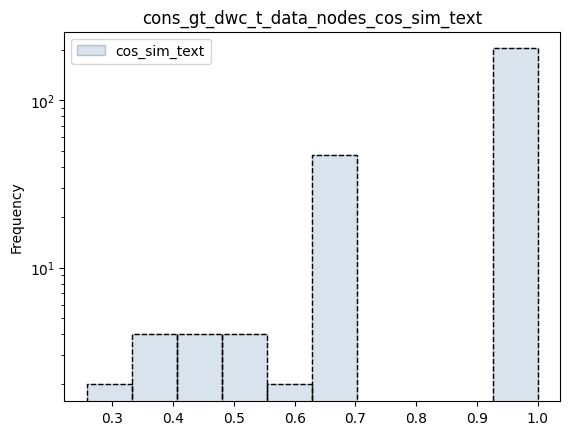

In [70]:
plt.title("cons_gt_dwc_t_data_nodes_cos_sim_text")
cons_gt_dwc_t_data_nodes_cos_sim_text["cos_sim_text"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=True)
cons_gt_dwc_t_data_nodes_cos_sim_text["cos_sim_text"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")

<Axes: title={'center': 'cons_gt_dwc_t_data_nodes_cos_sim_attributes'}, ylabel='Frequency'>

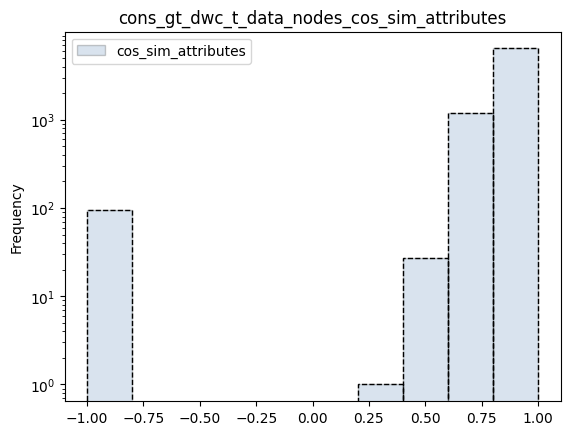

In [71]:
plt.title("cons_gt_dwc_t_data_nodes_cos_sim_attributes")
cons_gt_dwc_t_data_nodes_cos_sim_attributes["cos_sim_attributes"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=True)
cons_gt_dwc_t_data_nodes_cos_sim_attributes["cos_sim_attributes"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")

In [72]:
display(cons_gt_dwc_t_author_nodes_cos_sim_text.describe(include="all"))
display(cons_gt_dwc_t_author_nodes_cos_sim_text[
    cons_gt_dwc_t_author_nodes_cos_sim_text["cos_sim_text"] < 0.9
].describe(include="all"))

print("---")

display(cons_gt_dwc_t_author_nodes_cos_sim_attributes.describe(include="all"))
display(cons_gt_dwc_t_author_nodes_cos_sim_attributes[
    cons_gt_dwc_t_author_nodes_cos_sim_attributes["cos_sim_attributes"] < 0.9
].describe(include="all"))

,case_id,path,tag,cons_text,gt_text,cos_sim_text
count,270.000000,270,270,270,270,270.000000
unique,NaN,5,1,20,20,NaN
top,NaN,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,occurrence.txt,NaN
freq,NaN,174,270,164,164,NaN
mean,88.029630,NaN,NaN,NaN,NaN,0.879655
std,51.026408,NaN,NaN,NaN,NaN,0.190179
min,0.000000,NaN,NaN,NaN,NaN,0.354693
25%,43.000000,NaN,NaN,NaN,NaN,0.648550
50%,86.500000,NaN,NaN,NaN,NaN,1.000000
75%,130.000000,NaN,NaN,NaN,NaN,1.000000


,case_id,path,tag,cons_text,gt_text,cos_sim_text
count,81.000000,81,81,81,81,81.000000
unique,NaN,5,1,10,10,NaN
top,NaN,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,occurrence.txt,NaN
freq,NaN,32,81,33,33,NaN
mean,86.703704,NaN,NaN,NaN,NaN,0.598848
std,52.212413,NaN,NaN,NaN,NaN,0.086957
min,0.000000,NaN,NaN,NaN,NaN,0.354693
25%,42.000000,NaN,NaN,NaN,NaN,0.520925
50%,89.000000,NaN,NaN,NaN,NaN,0.648550
75%,124.000000,NaN,NaN,NaN,NaN,0.648550


---


,case_id,path,tag,cons_attributes,gt_attributes,cos_sim_attributes
count,7711.000000,7711,7711,7711,7711,7711.000000
unique,NaN,320,6,2828,2761,NaN
top,NaN,{http://rs.tdwg.org/dwc/text/}core,{http://rs.tdwg.org/dwc/text/}field,"{""index"": ""0""}","{""index"": ""0""}",NaN
freq,NaN,174,7001,205,269,NaN
mean,89.425107,NaN,NaN,NaN,NaN,0.893094
std,50.600470,NaN,NaN,NaN,NaN,0.291561
min,0.000000,NaN,NaN,NaN,NaN,-1.000000
25%,46.000000,NaN,NaN,NaN,NaN,0.838413
50%,91.000000,NaN,NaN,NaN,NaN,1.000000
75%,133.000000,NaN,NaN,NaN,NaN,1.000000


,case_id,path,tag,cons_attributes,gt_attributes,cos_sim_attributes
count,2429.000000,2429,2429,2429,2429,2429.000000
unique,NaN,309,6,1157,1082,NaN
top,NaN,.,{http://rs.tdwg.org/dwc/text/}field,"{""metadata"": ""not-derived-001""}","{""metadata"": ""eml.xml""}",NaN
freq,NaN,171,2035,134,171,NaN
mean,85.369699,NaN,NaN,NaN,NaN,0.668064
std,51.882614,NaN,NaN,NaN,NaN,0.442184
min,0.000000,NaN,NaN,NaN,NaN,-1.000000
25%,42.000000,NaN,NaN,NaN,NaN,0.725589
50%,86.000000,NaN,NaN,NaN,NaN,0.781835
75%,134.000000,NaN,NaN,NaN,NaN,0.830097


<Axes: title={'center': 'cons_gt_dwc_t_author_nodes_cos_sim_text'}, ylabel='Frequency'>

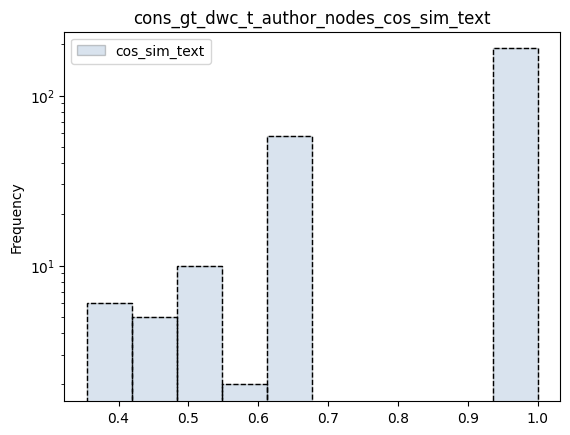

In [73]:
plt.title("cons_gt_dwc_t_author_nodes_cos_sim_text")
cons_gt_dwc_t_author_nodes_cos_sim_text["cos_sim_text"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=True)
cons_gt_dwc_t_author_nodes_cos_sim_text["cos_sim_text"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")

<Axes: title={'center': 'cons_gt_dwc_t_author_nodes_cos_sim_attributes'}, ylabel='Frequency'>

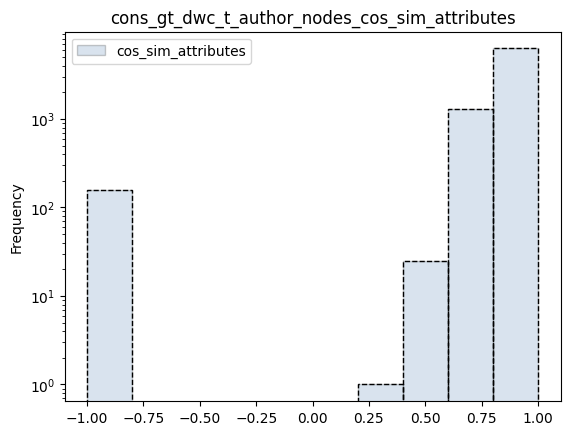

In [74]:
plt.title("cons_gt_dwc_t_author_nodes_cos_sim_attributes")
cons_gt_dwc_t_author_nodes_cos_sim_attributes["cos_sim_attributes"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=True)
cons_gt_dwc_t_author_nodes_cos_sim_attributes["cos_sim_attributes"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")

In [75]:
display(cons_gt_eml_data_nodes_cos_sim_text.describe(include="all"))
display(cons_gt_eml_data_nodes_cos_sim_attributes.describe(include="all"))

,case_id,path,tag,cons_text,gt_text,cos_sim_text
count,864.000000,864,864,864,864,864.000000
unique,NaN,46,12,332,619,NaN
top,NaN,dataset/title,para,not-derived-011,unkown,NaN
freq,NaN,150,257,90,53,NaN
mean,83.092593,NaN,NaN,NaN,NaN,-0.310847
std,52.995360,NaN,NaN,NaN,NaN,0.741166
min,0.000000,NaN,NaN,NaN,NaN,-1.000000
25%,39.000000,NaN,NaN,NaN,NaN,-1.000000
50%,79.000000,NaN,NaN,NaN,NaN,-1.000000
75%,130.000000,NaN,NaN,NaN,NaN,0.333287


,case_id,path,tag,cons_attributes,gt_attributes,cos_sim_attributes
count,180.000000,180,180,180,180,180.000000
unique,NaN,5,3,73,154,NaN
top,NaN,.,{https://eml.ecoinformatics.org/eml-2.2.0}eml,"{""packageId"": ""not-derived-000"", ""system"": ""kn...","{""directory"": ""https://orcid.org/""}",NaN
freq,NaN,150,150,48,14,NaN
mean,87.516667,NaN,NaN,NaN,NaN,-0.122967
std,52.733702,NaN,NaN,NaN,NaN,0.827257
min,0.000000,NaN,NaN,NaN,NaN,-1.000000
25%,42.750000,NaN,NaN,NaN,NaN,-1.000000
50%,86.500000,NaN,NaN,NaN,NaN,0.424539
75%,133.250000,NaN,NaN,NaN,NaN,0.571994


<Axes: title={'center': 'cons_gt_eml_data_nodes_cos_sim_text'}, ylabel='Frequency'>

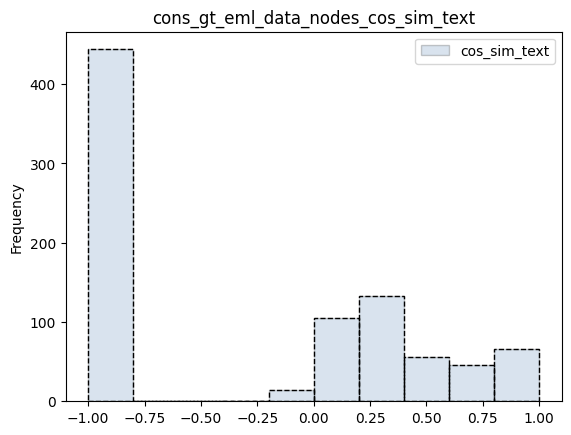

In [76]:
plt.title("cons_gt_eml_data_nodes_cos_sim_text")
cons_gt_eml_data_nodes_cos_sim_text["cos_sim_text"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=False)
cons_gt_eml_data_nodes_cos_sim_text["cos_sim_text"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")

<Axes: title={'center': 'cons_gt_eml_data_nodes_cos_sim_attributes'}, ylabel='Frequency'>

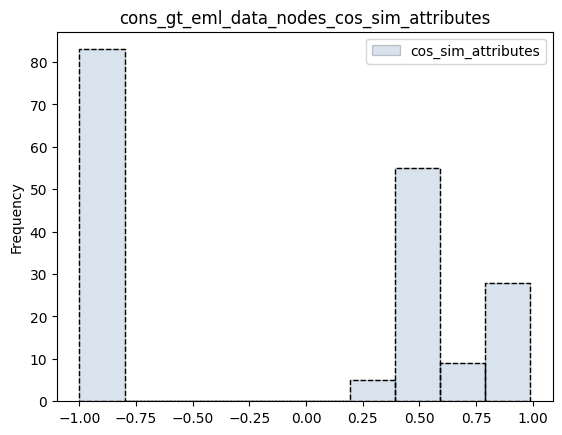

In [77]:
plt.title("cons_gt_eml_data_nodes_cos_sim_attributes")
cons_gt_eml_data_nodes_cos_sim_attributes["cos_sim_attributes"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=False)
cons_gt_eml_data_nodes_cos_sim_attributes["cos_sim_attributes"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")

In [78]:
display(cons_gt_eml_author_nodes_cos_sim_text.describe(include="all"))
display(cons_gt_eml_author_nodes_cos_sim_attributes.describe(include="all"))

,case_id,path,tag,cons_text,gt_text,cos_sim_text
count,834.000000,834,834,834,834,834.000000
unique,NaN,29,10,443,605,NaN
top,NaN,dataset/title,para,not-derived-011,unkown,NaN
freq,NaN,148,253,59,53,NaN
mean,88.726619,NaN,NaN,NaN,NaN,-0.051712
std,51.816437,NaN,NaN,NaN,NaN,0.784029
min,0.000000,NaN,NaN,NaN,NaN,-1.000000
25%,46.250000,NaN,NaN,NaN,NaN,-1.000000
50%,87.000000,NaN,NaN,NaN,NaN,0.223745
75%,137.750000,NaN,NaN,NaN,NaN,0.589701


,case_id,path,tag,cons_attributes,gt_attributes,cos_sim_attributes
count,176.000000,176,176,176,176,176.000000
unique,NaN,3,3,76,152,NaN
top,NaN,.,{https://eml.ecoinformatics.org/eml-2.2.0}eml,"{""packageId"": ""not-derived-000"", ""system"": ""kn...","{""directory"": ""https://orcid.org/""}",NaN
freq,NaN,148,148,48,12,NaN
mean,91.784091,NaN,NaN,NaN,NaN,-0.029703
std,50.980769,NaN,NaN,NaN,NaN,0.812901
min,0.000000,NaN,NaN,NaN,NaN,-1.000000
25%,47.750000,NaN,NaN,NaN,NaN,-1.000000
50%,91.500000,NaN,NaN,NaN,NaN,0.477857
75%,137.250000,NaN,NaN,NaN,NaN,0.604676


<Axes: title={'center': 'cons_gt_eml_author_nodes_cos_sim_text'}, ylabel='Frequency'>

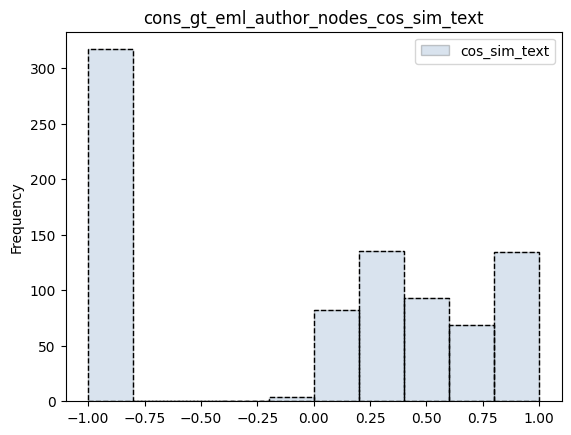

In [79]:
plt.title("cons_gt_eml_author_nodes_cos_sim_text")
cons_gt_eml_author_nodes_cos_sim_text["cos_sim_text"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=False)
cons_gt_eml_author_nodes_cos_sim_text["cos_sim_text"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")

<Axes: title={'center': 'cons_gt_eml_author_nodes_cos_sim_attributes'}, ylabel='Frequency'>

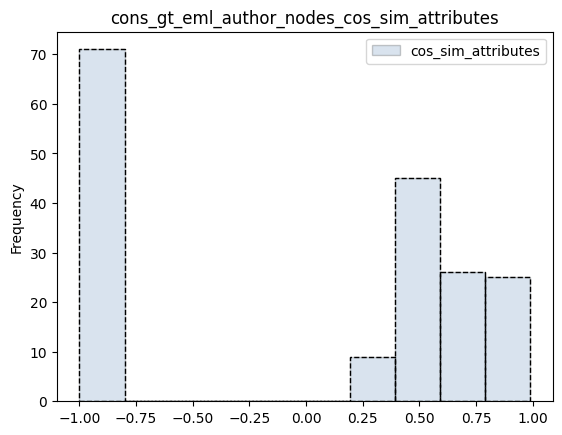

In [80]:
plt.title("cons_gt_eml_author_nodes_cos_sim_attributes")
cons_gt_eml_author_nodes_cos_sim_attributes["cos_sim_attributes"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=False)
cons_gt_eml_author_nodes_cos_sim_attributes["cos_sim_attributes"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")

In [81]:
!mkdir -p output_data

In [82]:
cons_gt_dwc_t_data_nodes_cos_sim_text.to_csv("output_data/cons_gt_dwc_t_data_nodes_cos_sim_text.csv")
cons_gt_dwc_t_data_nodes_cos_sim_attributes.to_csv("output_data/cons_gt_dwc_t_data_nodes_cos_sim_attributes.csv")
cons_gt_dwc_t_author_nodes_cos_sim_text.to_csv("output_data/cons_gt_dwc_t_author_nodes_cos_sim_text.csv")
cons_gt_dwc_t_author_nodes_cos_sim_attributes.to_csv("output_data/cons_gt_dwc_t_author_nodes_cos_sim_attributes.csv")
cons_gt_eml_data_nodes_cos_sim_text.to_csv("output_data/cons_gt_eml_data_nodes_cos_sim_text.csv")
cons_gt_eml_data_nodes_cos_sim_attributes.to_csv("output_data/cons_gt_eml_data_nodes_cos_sim_attributes.csv")
cons_gt_eml_author_nodes_cos_sim_text.to_csv("output_data/cons_gt_eml_author_nodes_cos_sim_text.csv")
cons_gt_eml_author_nodes_cos_sim_attributes.to_csv("output_data/cons_gt_eml_author_nodes_cos_sim_attributes.csv")

In [83]:
!zip output_data.zip output_data/*

updating: output_data/cons_gt_dwc_t_author_nodes_cos_sim_attributes.csv (deflated 93%)
updating: output_data/cons_gt_dwc_t_author_nodes_cos_sim_text.csv (deflated 95%)
updating: output_data/cons_gt_dwc_t_data_nodes_cos_sim_attributes.csv (deflated 93%)
updating: output_data/cons_gt_dwc_t_data_nodes_cos_sim_text.csv (deflated 95%)
updating: output_data/cons_gt_eml_author_nodes_cos_sim_attributes.csv (deflated 90%)
updating: output_data/cons_gt_eml_author_nodes_cos_sim_text.csv (deflated 66%)
updating: output_data/cons_gt_eml_data_nodes_cos_sim_attributes.csv (deflated 90%)
updating: output_data/cons_gt_eml_data_nodes_cos_sim_text.csv (deflated 66%)


## Inspect results

In [84]:
conn.query("""
CREATE TABLE IF NOT EXISTS cons_gt_dwc_t_data_nodes_cos_sim_text AS
  SELECT * FROM cons_gt_dwc_t_data_nodes_cos_sim_text;

CREATE TABLE IF NOT EXISTS cons_gt_dwc_t_data_nodes_cos_sim_attributes AS
  SELECT * FROM cons_gt_dwc_t_data_nodes_cos_sim_attributes;

--

CREATE TABLE IF NOT EXISTS cons_gt_dwc_t_author_nodes_cos_sim_text AS
  SELECT * FROM cons_gt_dwc_t_author_nodes_cos_sim_text;

CREATE TABLE IF NOT EXISTS cons_gt_dwc_t_author_nodes_cos_sim_attributes AS
  SELECT * FROM cons_gt_dwc_t_author_nodes_cos_sim_attributes;

--

CREATE TABLE IF NOT EXISTS cons_gt_eml_data_nodes_cos_sim_text AS
  SELECT * FROM cons_gt_eml_data_nodes_cos_sim_text;

CREATE TABLE IF NOT EXISTS cons_gt_eml_data_nodes_cos_sim_attributes AS
  SELECT * FROM cons_gt_eml_data_nodes_cos_sim_attributes;

--

CREATE TABLE IF NOT EXISTS cons_gt_eml_author_nodes_cos_sim_text AS
  SELECT * FROM cons_gt_eml_author_nodes_cos_sim_text;

CREATE TABLE IF NOT EXISTS cons_gt_eml_author_nodes_cos_sim_attributes AS
  SELECT * FROM cons_gt_eml_author_nodes_cos_sim_attributes;
""")

### DwC-T

,case_id,cos_sim_text
count,267.000000,267.000000
mean,87.707865,0.903594
std,52.224617,0.181778
min,0.000000,0.257896
25%,41.500000,1.000000
50%,86.000000,1.000000
75%,132.000000,1.000000
max,178.000000,1.000000


<Axes: ylabel='Frequency'>

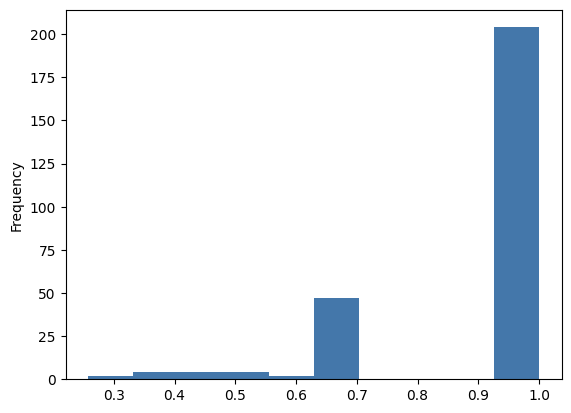

In [407]:
display(cons_gt_dwc_t_data_nodes_cos_sim_text.describe())
cons_gt_dwc_t_data_nodes_cos_sim_text["cos_sim_text"].plot.hist()

,case_id,cos_sim_text
count,270.000000,270.000000
mean,88.029630,0.879655
std,51.026408,0.190179
min,0.000000,0.354693
25%,43.000000,0.648550
50%,86.500000,1.000000
75%,130.000000,1.000000
max,178.000000,1.000000


<Axes: ylabel='Frequency'>

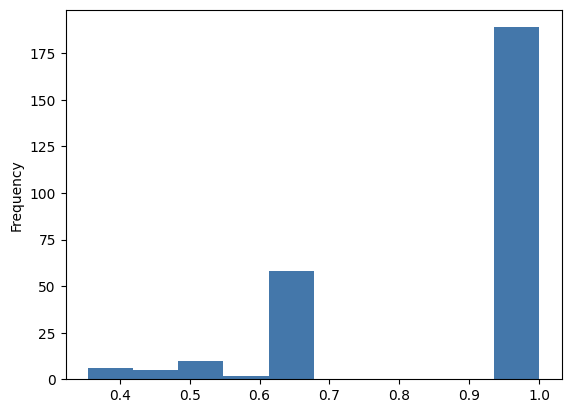

In [408]:
display(cons_gt_dwc_t_author_nodes_cos_sim_text.describe())
cons_gt_dwc_t_author_nodes_cos_sim_text["cos_sim_text"].plot.hist()

In [85]:
%%sql cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect <<
CREATE TABLE IF NOT EXISTS cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect AS (
  SELECT
    c.path,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_text) as ds_count,
    stddev_pop(cos_sim_text) as ds_std_pop,
    AVG(cos_sim_text) as ds_mean,
    MAX(cos_sim_text) as ds_max,
    MIN(cos_sim_text) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p75_cont,
  FROM cons_gt_dwc_t_data_nodes_cos_sim_text as c
  GROUP BY c.path, hash_path
);
SELECT * FROM cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect;

Running query in 'duckdb'

In [86]:
%%sql cons_gt_dwc_t_data_nodes_cos_sim_attributes__path_inspect <<
CREATE TABLE IF NOT EXISTS cons_gt_dwc_t_data_nodes_cos_sim_attributes__path_inspect AS (
  SELECT
    c.path,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_attributes) as ds_count,
    AVG(cos_sim_attributes) as ds_mean,
    stddev_pop(cos_sim_attributes) as ds_std_pop,
    MAX(cos_sim_attributes) as ds_max,
    MIN(cos_sim_attributes) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p75_cont,
  FROM cons_gt_dwc_t_data_nodes_cos_sim_attributes as c
  GROUP BY c.path, hash_path
);
SELECT * FROM cons_gt_dwc_t_data_nodes_cos_sim_attributes__path_inspect;

Running query in 'duckdb'

In [87]:
%%sql cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect <<
CREATE TABLE IF NOT EXISTS cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect AS (
  SELECT
    c.path,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_text) as ds_count,
    stddev_pop(cos_sim_text) as ds_std_pop,
    AVG(cos_sim_text) as ds_mean,
    MAX(cos_sim_text) as ds_max,
    MIN(cos_sim_text) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p75_cont,
  FROM cons_gt_dwc_t_author_nodes_cos_sim_text as c
  GROUP BY c.path, hash_path
);
SELECT * FROM cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect;

Running query in 'duckdb'

In [88]:
%%sql cons_gt_dwc_t_author_nodes_cos_sim_attributes__path_inspect <<
CREATE TABLE IF NOT EXISTS cons_gt_dwc_t_author_nodes_cos_sim_attributes__path_inspect AS (
  SELECT
    c.path,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_attributes) as ds_count,
    AVG(cos_sim_attributes) as ds_mean,
    stddev_pop(cos_sim_attributes) as ds_std_pop,
    MAX(cos_sim_attributes) as ds_max,
    MIN(cos_sim_attributes) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p75_cont,
  FROM cons_gt_dwc_t_author_nodes_cos_sim_attributes as c
  GROUP BY c.path, hash_path
);
SELECT * FROM cons_gt_dwc_t_author_nodes_cos_sim_attributes__path_inspect;

Running query in 'duckdb'

In [89]:
cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect = (
    cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)
cons_gt_dwc_t_data_nodes_cos_sim_attributes__path_inspect = (
    cons_gt_dwc_t_data_nodes_cos_sim_attributes__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)
cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect = (
    cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)
cons_gt_dwc_t_author_nodes_cos_sim_attributes__path_inspect = (
    cons_gt_dwc_t_author_nodes_cos_sim_attributes__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)

In [90]:
cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
2972828624038042123,{http://rs.tdwg.org/dwc/text/}extension[2]/{ht...,15,15,0.295611,0.735620,1.0,0.257896,1.000000,0.417432,1.000000
4300982297047325395,{http://rs.tdwg.org/dwc/text/}extension/{http:...,61,61,0.169136,0.882493,1.0,0.509599,1.000000,0.648550,1.000000
8026162855970452193,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,174,174,0.125650,0.948706,1.0,0.509599,1.000000,1.000000,1.000000
11761823836042817577,{http://rs.tdwg.org/dwc/text/}extension[3]/{ht...,2,2,0.248102,0.751898,1.0,0.503796,0.751898,0.627847,0.875949
16898280223678874349,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,15,15,0.268428,0.654307,1.0,0.257896,0.648550,0.417432,1.000000


In [91]:
cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
2972828624038042123,{http://rs.tdwg.org/dwc/text/}extension[2]/{ht...,16,16,0.252536,0.638249,1.00000,0.354693,0.512361,0.471848,1.000000
4300982297047325395,{http://rs.tdwg.org/dwc/text/}extension/{http:...,62,62,0.175980,0.856045,1.00000,0.509599,1.000000,0.648550,1.000000
8026162855970452193,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,174,174,0.138226,0.934567,1.00000,0.509599,1.000000,1.000000,1.000000
11761823836042817577,{http://rs.tdwg.org/dwc/text/}extension[3]/{ht...,2,2,0.040979,0.607572,0.64855,0.566593,0.607572,0.587082,0.628061
16898280223678874349,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,16,16,0.246570,0.649384,1.00000,0.354693,0.520925,0.497911,1.000000


In [92]:
set(cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect["path"].unique()) == set(cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect["path"].unique())

True

In [93]:
set(cons_gt_dwc_t_data_nodes_cos_sim_attributes__path_inspect["path"].unique()) == set(cons_gt_dwc_t_author_nodes_cos_sim_attributes__path_inspect["path"].unique())

False

In [94]:
print(f"{cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect.shape=}")
print(f"{cons_gt_dwc_t_data_nodes_cos_sim_attributes__path_inspect.shape=}")

print(f"{cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect.shape=}")
print(f"{cons_gt_dwc_t_author_nodes_cos_sim_attributes__path_inspect.shape=}")


cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect.shape=(5, 10)
cons_gt_dwc_t_data_nodes_cos_sim_attributes__path_inspect.shape=(322, 10)
cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect.shape=(5, 10)
cons_gt_dwc_t_author_nodes_cos_sim_attributes__path_inspect.shape=(320, 10)


#### Inspections DwC-T

In [95]:
from scipy.stats import pearsonr

In [410]:
df1 = cons_gt_dwc_t_data_nodes_cos_sim_text
df2 = cons_gt_dwc_t_author_nodes_cos_sim_text

shared_tags = list(set.intersection(
    set(df1["tag"].tolist()),
    set(df2["tag"].tolist())
))

for t in shared_tags:
    print("---")
    print(f"Tag: {t}")
    subdf1 = df1[df1["tag"] == t]
    subdf2 = df2[df2["tag"] == t]

    display(subdf1.describe())
    display(subdf2.describe())
    
    display(subdf1.describe().to_latex())
    display(subdf2.describe().to_latex())
    
    display(ttest_ind(
        subdf1["cos_sim_text"], 
        subdf2["cos_sim_text"],
        equal_var=False
    ))
    display(mannwhitneyu(
        subdf1["cos_sim_text"], 
        subdf2["cos_sim_text"],
        alternative="greater"
    ))
    display(cohen_d(
            subdf1["cos_sim_text"], 
            subdf2["cos_sim_text"],
    ))
    print("---")

---
Tag: {http://rs.tdwg.org/dwc/text/}location


,case_id,cos_sim_text
count,267.000000,267.000000
mean,87.707865,0.903594
std,52.224617,0.181778
min,0.000000,0.257896
25%,41.500000,1.000000
50%,86.000000,1.000000
75%,132.000000,1.000000
max,178.000000,1.000000


,case_id,cos_sim_text
count,270.000000,270.000000
mean,88.029630,0.879655
std,51.026408,0.190179
min,0.000000,0.354693
25%,43.000000,0.648550
50%,86.500000,1.000000
75%,130.000000,1.000000
max,178.000000,1.000000


'\\begin{tabular}{lrr}\n\\toprule\n & case_id & cos_sim_text \\\\\n\\midrule\ncount & 267.000000 & 267.000000 \\\\\nmean & 87.707865 & 0.903594 \\\\\nstd & 52.224617 & 0.181778 \\\\\nmin & 0.000000 & 0.257896 \\\\\n25% & 41.500000 & 1.000000 \\\\\n50% & 86.000000 & 1.000000 \\\\\n75% & 132.000000 & 1.000000 \\\\\nmax & 178.000000 & 1.000000 \\\\\n\\bottomrule\n\\end{tabular}\n'

'\\begin{tabular}{lrr}\n\\toprule\n & case_id & cos_sim_text \\\\\n\\midrule\ncount & 270.000000 & 270.000000 \\\\\nmean & 88.029630 & 0.879655 \\\\\nstd & 51.026408 & 0.190179 \\\\\nmin & 0.000000 & 0.354693 \\\\\n25% & 43.000000 & 0.648550 \\\\\n50% & 86.500000 & 1.000000 \\\\\n75% & 130.000000 & 1.000000 \\\\\nmax & 178.000000 & 1.000000 \\\\\n\\bottomrule\n\\end{tabular}\n'

TtestResult(statistic=np.float64(1.4912259770708958), pvalue=np.float64(0.13649222001852707), df=np.float64(534.383448835798))

MannwhitneyuResult(statistic=np.float64(38376.0), pvalue=np.float64(0.04718603487017262))

np.float64(0.12867178928710327)

---


In [96]:
%%sql cons_gt_dwc_t_data_cos_sim_text_to_nr_data_files <<
SELECT cos_sim_text, nr_data_files 
FROM cons_gt_dwc_t_data_nodes_cos_sim_text AS cst
    JOIN experiment_case_to_nr_files AS ec
        ON cst.case_id = ec.case_id
;

Running query in 'duckdb'

In [97]:
r, p_val = pearsonr(
    cons_gt_dwc_t_data_cos_sim_text_to_nr_data_files["cos_sim_text"],
    cons_gt_dwc_t_data_cos_sim_text_to_nr_data_files["nr_data_files"]
)
print(f"{r=}", f"{p_val=}")

r=np.float64(-0.4598130521233156) p_val=np.float64(2.253888732134869e-15)


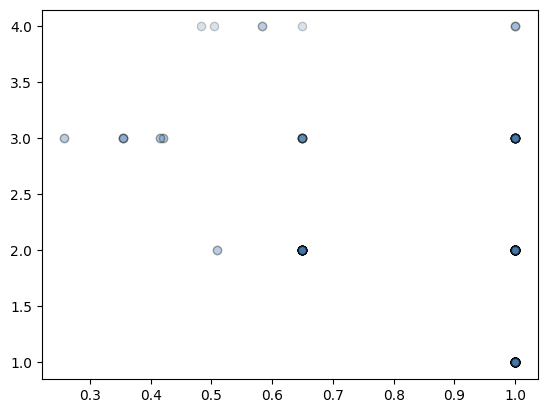

In [98]:
plt.scatter(
    cons_gt_dwc_t_data_cos_sim_text_to_nr_data_files["cos_sim_text"],
    cons_gt_dwc_t_data_cos_sim_text_to_nr_data_files["nr_data_files"],
    alpha=0.2,
    edgecolor="k"
)
plt.show()

In [99]:
%%sql cons_gt_dwc_t_author_cos_sim_text_to_nr_data_files <<
SELECT cos_sim_text, nr_data_files 
FROM cons_gt_dwc_t_author_nodes_cos_sim_text AS cst
    JOIN experiment_case_to_nr_files AS ec
        ON cst.case_id = ec.case_id
;

Running query in 'duckdb'

In [100]:
r, p_val = pearsonr(
    cons_gt_dwc_t_author_cos_sim_text_to_nr_data_files["cos_sim_text"],
    cons_gt_dwc_t_author_cos_sim_text_to_nr_data_files["nr_data_files"]
)
print(f"{r=}", f"{p_val=}")

r=np.float64(-0.5479629525673995) p_val=np.float64(1.4664937671886987e-22)


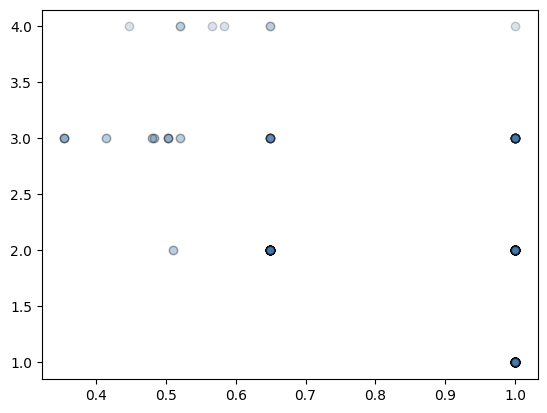

In [101]:
plt.scatter(
    cons_gt_dwc_t_author_cos_sim_text_to_nr_data_files["cos_sim_text"],
    cons_gt_dwc_t_author_cos_sim_text_to_nr_data_files["nr_data_files"],
    alpha=0.2,
    edgecolor="k"
)
plt.show()

In [102]:
# dwc-t + data

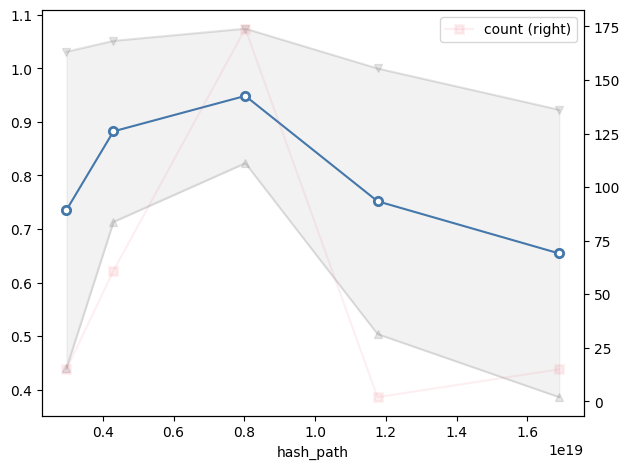

In [103]:
df = cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect
mean_plus_std = (df['ds_mean'] + df['ds_std_pop'])
mean_min_std = (df['ds_mean'] - df['ds_std_pop'])

plt.fill_between(df.index, mean_min_std, mean_plus_std, color="gray", alpha=0.1)
mean_plus_std.plot(alpha=0.2, marker="v", color="gray")
mean_min_std.plot(alpha=0.2, marker="^", color="gray")
df['ds_mean'].plot(marker="o", markerfacecolor="w", mew=2)
df['ds_count'].plot(alpha=0.1, marker="s", mew=2, secondary_y=True, label="count", legend=True)


plt.tight_layout()

<Axes: xlabel='hash_path'>

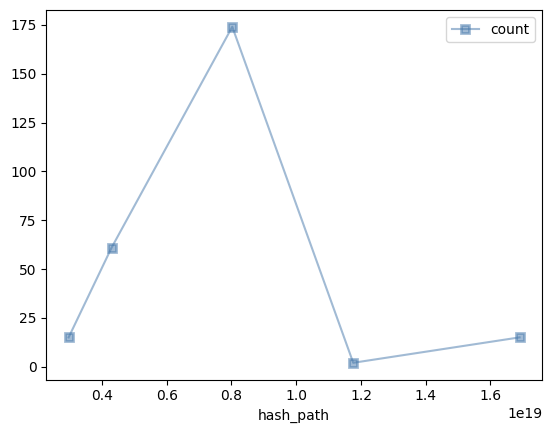

In [104]:
df = cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect
df['ds_count'].plot(alpha=0.5, marker="s", mew=2, label="count", legend=True)

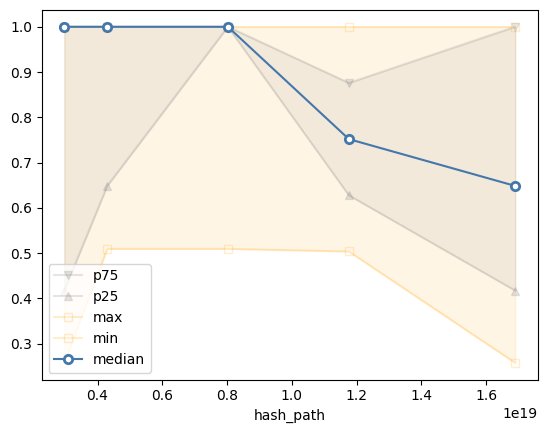

In [105]:
df = cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)
plt.legend(loc="lower left")
plt.show()

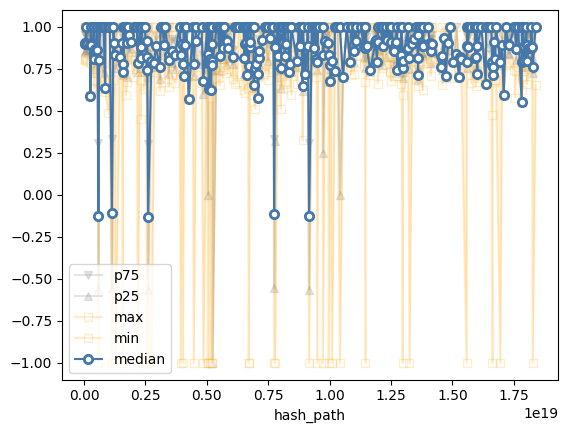

In [106]:
df = cons_gt_dwc_t_data_nodes_cos_sim_attributes__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)
plt.legend(loc="lower left")
plt.show()

In [107]:
# dwc-t + author

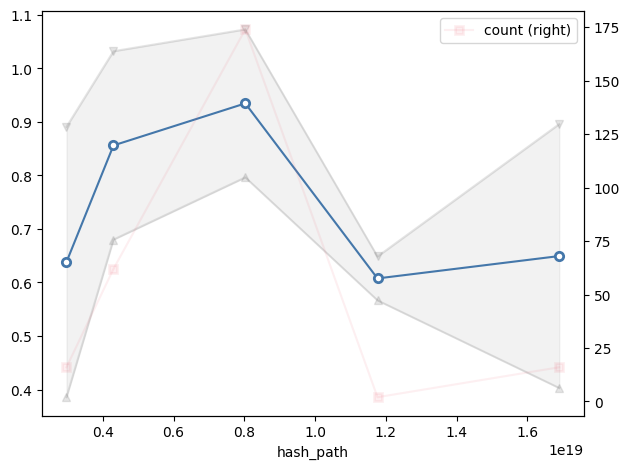

In [108]:
df = cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect
mean_plus_std = (df['ds_mean'] + df['ds_std_pop'])
mean_min_std = (df['ds_mean'] - df['ds_std_pop'])

plt.fill_between(df.index, mean_min_std, mean_plus_std, color="gray", alpha=0.1)
mean_plus_std.plot(alpha=0.2, marker="v", color="gray")
mean_min_std.plot(alpha=0.2, marker="^", color="gray")
df['ds_mean'].plot(marker="o", markerfacecolor="w", mew=2)
df['ds_count'].plot(alpha=0.1, marker="s", mew=2, secondary_y=True, label="count", legend=True)


plt.tight_layout()

<Axes: xlabel='hash_path'>

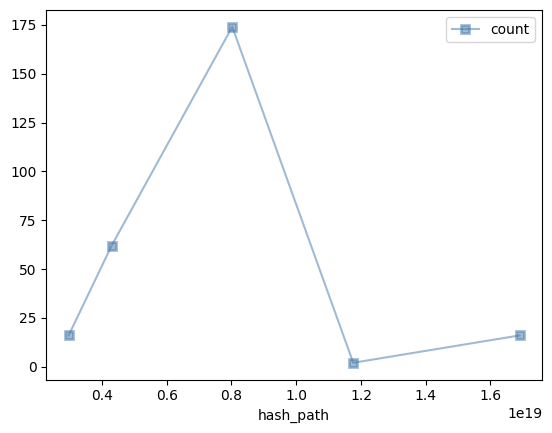

In [109]:
df = cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect
df['ds_count'].plot(alpha=0.5, marker="s", mew=2, label="count", legend=True)

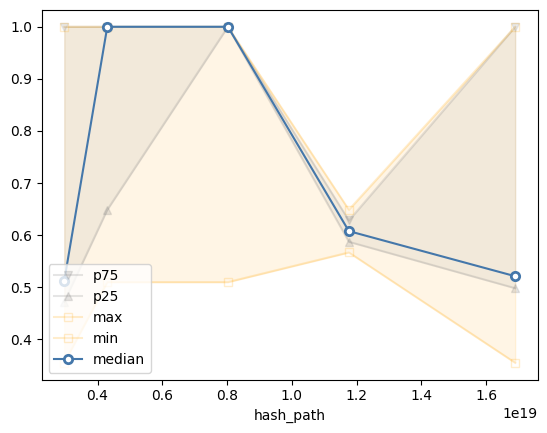

In [110]:
df = cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)
plt.legend(loc="lower left")
plt.show()

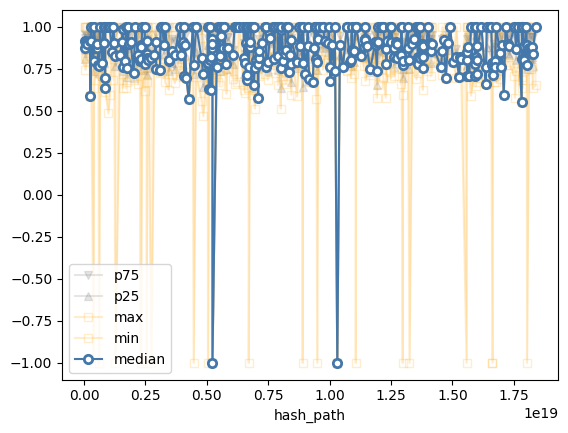

In [111]:
df = cons_gt_dwc_t_author_nodes_cos_sim_attributes__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)
plt.legend(loc="lower left")
plt.show()

In [318]:
display(cons_gt_dwc_t_data_nodes_cos_sim_attributes.describe(include="all"))
display(cons_gt_dwc_t_author_nodes_cos_sim_attributes.describe(include="all"))

,case_id,path,tag,cons_attributes,gt_attributes,cos_sim_attributes
count,7746.000000,7746,7746,7746,7746,7746.000000
unique,NaN,322,6,2867,2807,NaN
top,NaN,{http://rs.tdwg.org/dwc/text/}core,{http://rs.tdwg.org/dwc/text/}field,"{""index"": ""0""}","{""index"": ""0""}",NaN
freq,NaN,174,7042,207,266,NaN
mean,88.934418,NaN,NaN,NaN,NaN,0.914263
std,51.635214,NaN,NaN,NaN,NaN,0.237642
min,0.000000,NaN,NaN,NaN,NaN,-1.000000
25%,43.000000,NaN,NaN,NaN,NaN,0.867690
50%,91.000000,NaN,NaN,NaN,NaN,1.000000
75%,134.000000,NaN,NaN,NaN,NaN,1.000000


,case_id,path,tag,cons_attributes,gt_attributes,cos_sim_attributes
count,7711.000000,7711,7711,7711,7711,7711.000000
unique,NaN,320,6,2828,2761,NaN
top,NaN,{http://rs.tdwg.org/dwc/text/}core,{http://rs.tdwg.org/dwc/text/}field,"{""index"": ""0""}","{""index"": ""0""}",NaN
freq,NaN,174,7001,205,269,NaN
mean,89.425107,NaN,NaN,NaN,NaN,0.893094
std,50.600470,NaN,NaN,NaN,NaN,0.291561
min,0.000000,NaN,NaN,NaN,NaN,-1.000000
25%,46.000000,NaN,NaN,NaN,NaN,0.838413
50%,91.000000,NaN,NaN,NaN,NaN,1.000000
75%,133.000000,NaN,NaN,NaN,NaN,1.000000


In [368]:
display(cons_gt_dwc_t_data_nodes_cos_sim_attributes.describe().to_latex())
display(cons_gt_dwc_t_author_nodes_cos_sim_attributes.describe().to_latex())

display(
    ttest_ind(
        cons_gt_dwc_t_data_nodes_cos_sim_attributes["cos_sim_attributes"],
        cons_gt_dwc_t_author_nodes_cos_sim_attributes["cos_sim_attributes"],
    )
)
display(
    cohen_d(
        cons_gt_dwc_t_data_nodes_cos_sim_attributes["cos_sim_attributes"],
        cons_gt_dwc_t_author_nodes_cos_sim_attributes["cos_sim_attributes"],
    )
)

'\\begin{tabular}{lrr}\n\\toprule\n & case_id & cos_sim_attributes \\\\\n\\midrule\ncount & 7746.000000 & 7746.000000 \\\\\nmean & 88.934418 & 0.914263 \\\\\nstd & 51.635214 & 0.237642 \\\\\nmin & 0.000000 & -1.000000 \\\\\n25% & 43.000000 & 0.867690 \\\\\n50% & 91.000000 & 1.000000 \\\\\n75% & 134.000000 & 1.000000 \\\\\nmax & 178.000000 & 1.000000 \\\\\n\\bottomrule\n\\end{tabular}\n'

'\\begin{tabular}{lrr}\n\\toprule\n & case_id & cos_sim_attributes \\\\\n\\midrule\ncount & 7711.000000 & 7711.000000 \\\\\nmean & 89.425107 & 0.893094 \\\\\nstd & 50.600470 & 0.291561 \\\\\nmin & 0.000000 & -1.000000 \\\\\n25% & 46.000000 & 0.838413 \\\\\n50% & 91.000000 & 1.000000 \\\\\n75% & 133.000000 & 1.000000 \\\\\nmax & 178.000000 & 1.000000 \\\\\n\\bottomrule\n\\end{tabular}\n'

TtestResult(statistic=np.float64(4.948925466726285), pvalue=np.float64(7.540992740728388e-07), df=np.float64(15455.0))

np.float64(0.07961216212477601)

In [319]:
display(cons_gt_dwc_t_data_nodes_cos_sim_attributes["tag"].value_counts())
display(cons_gt_dwc_t_author_nodes_cos_sim_attributes["tag"].value_counts())

tag
{http://rs.tdwg.org/dwc/text/}field        7042
{http://rs.tdwg.org/dwc/text/}core          174
{http://rs.tdwg.org/dwc/text/}id            174
{http://rs.tdwg.org/dwc/text/}archive       171
{http://rs.tdwg.org/dwc/text/}extension      93
{http://rs.tdwg.org/dwc/text/}coreid         92
Name: count, dtype: int64

tag
{http://rs.tdwg.org/dwc/text/}field        7001
{http://rs.tdwg.org/dwc/text/}core          174
{http://rs.tdwg.org/dwc/text/}id            174
{http://rs.tdwg.org/dwc/text/}archive       171
{http://rs.tdwg.org/dwc/text/}extension      96
{http://rs.tdwg.org/dwc/text/}coreid         95
Name: count, dtype: int64

In [370]:
shared_tags = list(set.intersection(
    set(cons_gt_dwc_t_data_nodes_cos_sim_attributes["tag"].tolist()),
    set(cons_gt_dwc_t_author_nodes_cos_sim_attributes["tag"].tolist())
))

for t in shared_tags:
    print("---")
    print(f"Tag: {t}")
    subdf1 = cons_gt_dwc_t_data_nodes_cos_sim_attributes[cons_gt_dwc_t_data_nodes_cos_sim_attributes["tag"] == t]
    subdf2 = cons_gt_dwc_t_author_nodes_cos_sim_attributes[cons_gt_dwc_t_author_nodes_cos_sim_attributes["tag"] == t]

    # display(subdf1.describe())
    # display(subdf2.describe())
    
    display(subdf1.describe().to_latex())
    display(subdf2.describe().to_latex())
    
    display(ttest_ind(
        subdf1["cos_sim_attributes"], 
        subdf2["cos_sim_attributes"],
        equal_var=False
    ))
    display(mannwhitneyu(
        subdf1["cos_sim_attributes"], 
        subdf2["cos_sim_attributes"],
        alternative="greater"
    ))
    display(cohen_d(
            subdf1["cos_sim_attributes"], 
            subdf2["cos_sim_attributes"],
    ))
    print("---")

---
Tag: {http://rs.tdwg.org/dwc/text/}archive


'\\begin{tabular}{lrr}\n\\toprule\n & case_id & cos_sim_attributes \\\\\n\\midrule\ncount & 171.000000 & 171.000000 \\\\\nmean & 89.245614 & 0.156192 \\\\\nstd & 52.606625 & 0.842249 \\\\\nmin & 0.000000 & -1.000000 \\\\\n25% & 42.500000 & -1.000000 \\\\\n50% & 90.000000 & 0.771236 \\\\\n75% & 135.500000 & 0.771236 \\\\\nmax & 178.000000 & 0.771236 \\\\\n\\bottomrule\n\\end{tabular}\n'

'\\begin{tabular}{lrr}\n\\toprule\n & case_id & cos_sim_attributes \\\\\n\\midrule\ncount & 171.000000 & 171.000000 \\\\\nmean & 89.239766 & -0.633526 \\\\\nstd & 51.794116 & 0.712507 \\\\\nmin & 0.000000 & -1.000000 \\\\\n25% & 44.500000 & -1.000000 \\\\\n50% & 89.000000 & -1.000000 \\\\\n75% & 134.500000 & -1.000000 \\\\\nmax & 178.000000 & 0.771236 \\\\\n\\bottomrule\n\\end{tabular}\n'

TtestResult(statistic=np.float64(9.360858355592157), pvalue=np.float64(1.2484414223954618e-18), df=np.float64(330.9096166115932))

MannwhitneyuResult(statistic=np.float64(21399.5), pvalue=np.float64(5.664830029390776e-18))

...

'\\begin{tabular}{lrr}\n\\toprule\n & case_id & cos_sim_attributes \\\\\n\\midrule\ncount & 174.000000 & 174.000000 \\\\\nmean & 89.350575 & 0.991814 \\\\\nstd & 51.515395 & 0.037469 \\\\\nmin & 0.000000 & 0.795139 \\\\\n25% & 45.250000 & 1.000000 \\\\\n50% & 89.500000 & 1.000000 \\\\\n75% & 133.750000 & 1.000000 \\\\\nmax & 178.000000 & 1.000000 \\\\\n\\bottomrule\n\\end{tabular}\n'

TtestResult(statistic=np.float64(0.056148224507637214), pvalue=np.float64(0.9552561632808066), df=np.float64(345.70703590879157))

MannwhitneyuResult(statistic=np.float64(15144.5), pvalue=np.float64(0.49297090593927245))

np.float64(0.006019721530352453)

---


In [358]:
%%sql
WITH attr_spread AS (
SELECT *, 
    json_extract(dwc_t_data_attrs.gt_attributes::JSON, cons_a.key) AS gt_value,
    cos_sim(cons_a.value, gt_value) AS cons_sim_attr_value
FROM 
    cons_gt_dwc_t_data_nodes_cos_sim_attributes as dwc_t_data_attrs, 
    json_each(dwc_t_data_attrs.cons_attributes::JSON) as cons_a,
) 
SELECT DISTINCT key FROM attr_spread
ORDER BY key

Running query in 'duckdb'

,key
0,dateFormat
1,default
2,delimitedBy
3,encoding
4,fieldsEnclosedBy
5,fieldsTerminatedBy
6,ignoreHeaderLines
7,index
8,linesTerminatedBy
9,metadata


In [357]:
%%sql
WITH attr_spread AS (
SELECT *, 
    json_extract(dwc_t_author_attrs.gt_attributes::JSON, cons_a.key) AS gt_value,
    cos_sim(cons_a.value, gt_value) AS cons_sim_attr_value
FROM 
    cons_gt_dwc_t_author_nodes_cos_sim_attributes as dwc_t_author_attrs, 
    json_each(dwc_t_author_attrs.cons_attributes::JSON) as cons_a,
) 
SELECT DISTINCT key FROM attr_spread
ORDER BY key

Running query in 'duckdb'

,key
0,delimitedBy
1,encoding
2,fieldsEnclosedBy
3,fieldsTerminatedBy
4,ignoreHeaderLines
5,index
6,linesTerminatedBy
7,metadata
8,rowType
9,term


In [332]:
%%sql cons_gt_dwc_t_data_nodes_cos_sim_attributes___spread <<
CREATE OR REPLACE TABLE cons_gt_dwc_t_data_nodes_cos_sim_attributes___spread AS 
    SELECT *, 
        json_extract(dwc_t_data_attrs.gt_attributes::JSON, cons_a.key) AS gt_value,
        cos_sim(cons_a.value, gt_value) AS cons_sim_attr_value
    FROM 
        cons_gt_dwc_t_data_nodes_cos_sim_attributes as dwc_t_data_attrs, 
        json_each(dwc_t_data_attrs.cons_attributes::JSON) as cons_a;
SELECT * FROM cons_gt_dwc_t_data_nodes_cos_sim_attributes___spread

Running query in 'duckdb'

In [334]:
cons_gt_dwc_t_data_nodes_cos_sim_attributes___spread.describe(include="all")

,case_id,path,tag,cons_attributes,gt_attributes,cos_sim_attributes,key,value,type,atom,id,parent,fullkey,path_1,gt_value,cons_sim_attr_value
count,15747.000000,15747,15747,15747,15747,15747.000000,15747,15747,15747,15747,15747.000000,0.0,15747,15747,15735,15735.000000
unique,NaN,322,6,2867,2807,NaN,12,503,1,503,NaN,<NA>,12,1,490,NaN
top,NaN,{http://rs.tdwg.org/dwc/text/}core,{http://rs.tdwg.org/dwc/text/}field,"{""rowType"": ""http://rs.tdwg.org/dwc/terms/Occu...","{""encoding"": ""UTF-8"", ""fieldsTerminatedBy"": ""\...",NaN,index,"""1""",VARCHAR,"""1""",NaN,<NA>,$.index,$,"""1""",NaN
freq,NaN,820,14095,485,759,NaN,7308,524,15747,524,NaN,<NA>,7308,15747,521,NaN
mean,88.974090,NaN,NaN,NaN,NaN,0.920122,NaN,NaN,NaN,NaN,3.183845,<NA>,NaN,NaN,NaN,0.908314
std,51.633337,NaN,NaN,NaN,NaN,0.207117,NaN,NaN,NaN,NaN,1.431060,<NA>,NaN,NaN,NaN,0.227269
min,0.000000,NaN,NaN,NaN,NaN,-1.000000,NaN,NaN,NaN,NaN,2.000000,<NA>,NaN,NaN,NaN,-1.000000
25%,43.000000,NaN,NaN,NaN,NaN,0.877820,NaN,NaN,NaN,NaN,2.000000,<NA>,NaN,NaN,NaN,1.000000
50%,91.000000,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,4.000000,<NA>,NaN,NaN,NaN,1.000000
75%,134.000000,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,4.000000,<NA>,NaN,NaN,NaN,1.000000


In [333]:
%%sql cons_gt_dwc_t_author_nodes_cos_sim_attributes___spread <<
CREATE OR REPLACE TABLE cons_gt_dwc_t_author_nodes_cos_sim_attributes___spread AS 
    SELECT *, 
        json_extract(dwc_t_author_attrs.gt_attributes::JSON, cons_a.key) AS gt_value,
        cos_sim(cons_a.value, gt_value) AS cons_sim_attr_value
    FROM 
        cons_gt_dwc_t_author_nodes_cos_sim_attributes as dwc_t_author_attrs, 
        json_each(dwc_t_author_attrs.cons_attributes::JSON) as cons_a;
SELECT * FROM cons_gt_dwc_t_author_nodes_cos_sim_attributes___spread

Running query in 'duckdb'

In [339]:
cons_gt_dwc_t_author_nodes_cos_sim_attributes___spread.describe(include="all")

,case_id,path,tag,cons_attributes,gt_attributes,cos_sim_attributes,key,value,type,atom,id,parent,fullkey,path_1,gt_value,cons_sim_attr_value
count,15682.000000,15682,15682,15682,15682,15682.000000,15682,15682,15682,15682,15682.000000,0.0,15682,15682,15675,15675.000000
unique,NaN,320,6,2828,2761,NaN,10,491,1,491,NaN,<NA>,10,1,473,NaN
top,NaN,{http://rs.tdwg.org/dwc/text/}core,{http://rs.tdwg.org/dwc/text/}field,"{""rowType"": ""http://rs.tdwg.org/dwc/terms/Occu...","{""encoding"": ""UTF-8"", ""fieldsTerminatedBy"": ""\...",NaN,index,"""1""",VARCHAR,"""1""",NaN,<NA>,$.index,$,"""1""",NaN
freq,NaN,808,14009,490,750,NaN,7270,533,15682,533,NaN,<NA>,7270,15682,534,NaN
mean,89.377885,NaN,NaN,NaN,NaN,0.907687,NaN,NaN,NaN,NaN,3.183395,<NA>,NaN,NaN,NaN,0.890837
std,50.597816,NaN,NaN,NaN,NaN,0.231719,NaN,NaN,NaN,NaN,1.424470,<NA>,NaN,NaN,NaN,0.263283
min,0.000000,NaN,NaN,NaN,NaN,-1.000000,NaN,NaN,NaN,NaN,2.000000,<NA>,NaN,NaN,NaN,-1.000000
25%,46.000000,NaN,NaN,NaN,NaN,0.848933,NaN,NaN,NaN,NaN,2.000000,<NA>,NaN,NaN,NaN,1.000000
50%,91.000000,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,4.000000,<NA>,NaN,NaN,NaN,1.000000
75%,133.000000,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,4.000000,<NA>,NaN,NaN,NaN,1.000000


In [340]:
display(cons_gt_dwc_t_data_nodes_cos_sim_attributes___spread.describe(include="all").to_latex())
display(cons_gt_dwc_t_author_nodes_cos_sim_attributes___spread.describe(include="all").to_latex())

'\\begin{tabular}{lrllllrllllrrlllr}\n\\toprule\n & case_id & path & tag & cons_attributes & gt_attributes & cos_sim_attributes & key & value & type & atom & id & parent & fullkey & path_1 & gt_value & cons_sim_attr_value \\\\\n\\midrule\ncount & 15747.000000 & 15747 & 15747 & 15747 & 15747 & 15747.000000 & 15747 & 15747 & 15747 & 15747 & 15747.000000 & 0.000000 & 15747 & 15747 & 15735 & 15735.000000 \\\\\nunique & NaN & 322 & 6 & 2867 & 2807 & NaN & 12 & 503 & 1 & 503 & NaN & NaN & 12 & 1 & 490 & NaN \\\\\ntop & NaN & {http://rs.tdwg.org/dwc/text/}core & {http://rs.tdwg.org/dwc/text/}field & {"rowType": "http://rs.tdwg.org/dwc/terms/Occurrence", "fieldsTerminatedBy": "\\\\t", "fieldsEnclosedBy": "&quot;", "ignoreHeaderLines": "1", "encoding": "UTF-8"} & {"encoding": "UTF-8", "fieldsTerminatedBy": "\\\\t", "linesTerminatedBy": "\\\\n", "fieldsEnclosedBy": "", "ignoreHeaderLines": "1", "rowType": "http://rs.tdwg.org/dwc/terms/Occurrence"} & NaN & index & "1" & VARCHAR & "1" & NaN & NaN 

'\\begin{tabular}{lrllllrllllrrlllr}\n\\toprule\n & case_id & path & tag & cons_attributes & gt_attributes & cos_sim_attributes & key & value & type & atom & id & parent & fullkey & path_1 & gt_value & cons_sim_attr_value \\\\\n\\midrule\ncount & 15682.000000 & 15682 & 15682 & 15682 & 15682 & 15682.000000 & 15682 & 15682 & 15682 & 15682 & 15682.000000 & 0.000000 & 15682 & 15682 & 15675 & 15675.000000 \\\\\nunique & NaN & 320 & 6 & 2828 & 2761 & NaN & 10 & 491 & 1 & 491 & NaN & NaN & 10 & 1 & 473 & NaN \\\\\ntop & NaN & {http://rs.tdwg.org/dwc/text/}core & {http://rs.tdwg.org/dwc/text/}field & {"rowType": "http://rs.tdwg.org/dwc/terms/Occurrence", "fieldsTerminatedBy": "\\\\t", "fieldsEnclosedBy": "&quot;", "ignoreHeaderLines": "1", "encoding": "UTF-8"} & {"encoding": "UTF-8", "fieldsTerminatedBy": "\\\\t", "linesTerminatedBy": "\\\\n", "fieldsEnclosedBy": "", "ignoreHeaderLines": "1", "rowType": "http://rs.tdwg.org/dwc/terms/Occurrence"} & NaN & index & "1" & VARCHAR & "1" & NaN & NaN 

In [372]:
shared_keys = list(set.intersection(
    set(cons_gt_dwc_t_data_nodes_cos_sim_attributes___spread["key"].tolist()),
    set(cons_gt_dwc_t_author_nodes_cos_sim_attributes___spread["key"].tolist())
))

for k in sorted(shared_keys):
    print("---")
    print(f"Tag: {k}")
    subdf1 = cons_gt_dwc_t_data_nodes_cos_sim_attributes___spread[
        cons_gt_dwc_t_data_nodes_cos_sim_attributes___spread["key"] == k
    ]
    subdf2 = cons_gt_dwc_t_author_nodes_cos_sim_attributes___spread[
        cons_gt_dwc_t_author_nodes_cos_sim_attributes___spread["key"] == k
    ]
    display(subdf1.describe().to_latex())
    display(subdf2.describe().to_latex())
    display(ttest_ind(
        subdf1["cons_sim_attr_value"], 
        subdf2["cons_sim_attr_value"],
        equal_var=False
    ))
    display(mannwhitneyu(
        subdf1["cons_sim_attr_value"], 
        subdf2["cons_sim_attr_value"],
        alternative="greater"
    ))
    display(cohen_d(
            subdf1["cos_sim_attributes"], 
            subdf2["cos_sim_attributes"],
    ))
    print("---")

---
Tag: delimitedBy


'\\begin{tabular}{lrrrrr}\n\\toprule\n & case_id & cos_sim_attributes & id & parent & cons_sim_attr_value \\\\\n\\midrule\ncount & 4.000000 & 4.000000 & 4.000000 & 0.000000 & 0.000000 \\\\\nmean & 86.000000 & 0.933011 & 6.000000 & NaN & NaN \\\\\nstd & 31.176915 & 0.001295 & 0.000000 & NaN & NaN \\\\\nmin & 59.000000 & 0.932210 & 6.000000 & NaN & NaN \\\\\n25% & 59.000000 & 0.932383 & 6.000000 & NaN & NaN \\\\\n50% & 86.000000 & 0.932444 & 6.000000 & NaN & NaN \\\\\n75% & 113.000000 & 0.933072 & 6.000000 & NaN & NaN \\\\\nmax & 113.000000 & 0.934947 & 6.000000 & NaN & NaN \\\\\n\\bottomrule\n\\end{tabular}\n'

'\\begin{tabular}{lrrrrr}\n\\toprule\n & case_id & cos_sim_attributes & id & parent & cons_sim_attr_value \\\\\n\\midrule\ncount & 7.000000 & 7.000000 & 7.000000 & 0.000000 & 0.000000 \\\\\nmean & 96.428571 & 0.932109 & 6.000000 & NaN & NaN \\\\\nstd & 25.631082 & 0.003628 & 0.000000 & NaN & NaN \\\\\nmin & 59.000000 & 0.924257 & 6.000000 & NaN & NaN \\\\\n25% & 84.000000 & 0.932325 & 6.000000 & NaN & NaN \\\\\n50% & 109.000000 & 0.932447 & 6.000000 & NaN & NaN \\\\\n75% & 113.000000 & 0.934232 & 6.000000 & NaN & NaN \\\\\nmax & 113.000000 & 0.934947 & 6.000000 & NaN & NaN \\\\\n\\bottomrule\n\\end{tabular}\n'

TtestResult(statistic=np.float64(nan), pvalue=np.float64(nan), df=np.float64(nan))

MannwhitneyuResult(statistic=np.float64(nan), pvalue=np.float64(nan))

...

'\\begin{tabular}{lrrrrr}\n\\toprule\n & case_id & cos_sim_attributes & id & parent & cons_sim_attr_value \\\\\n\\midrule\ncount & 7001.000000 & 7001.000000 & 7001.000000 & 0.000000 & 7001.000000 \\\\\nmean & 89.541637 & 0.929095 & 4.000000 & NaN & 0.849270 \\\\\nstd & 50.545157 & 0.146048 & 0.000000 & NaN & 0.252644 \\\\\nmin & 0.000000 & -1.000000 & 4.000000 & NaN & -1.000000 \\\\\n25% & 46.000000 & 0.846414 & 4.000000 & NaN & 0.625801 \\\\\n50% & 91.000000 & 1.000000 & 4.000000 & NaN & 1.000000 \\\\\n75% & 134.000000 & 1.000000 & 4.000000 & NaN & 1.000000 \\\\\nmax & 178.000000 & 1.000000 & 4.000000 & NaN & 1.000000 \\\\\n\\bottomrule\n\\end{tabular}\n'

TtestResult(statistic=np.float64(3.6563755892656773), pvalue=np.float64(0.00025674065415744066), df=np.float64(14040.870404618641))

MannwhitneyuResult(statistic=np.float64(25546268.0), pvalue=np.float64(1.5853953993803034e-06))

np.float64(0.024257602712157697)

---


In [352]:
%%sql cons_gt_dwc_t_data_nodes_cos_sim_attributes___spread_valid_hierarchy << 
(
    SELECT *
    FROM cons_gt_dwc_t_data_nodes_cos_sim_attributes___spread
)
EXCEPT
(
    SELECT cats.* 
    FROM cons_gt_dwc_t_data_nodes_cos_sim_attributes___spread as cats
    JOIN (
            SELECT *, split(c.path, '/{')[1] AS failed_path
            FROM cons_gt_dwc_t_data_nodes_cos_sim_text AS c
            WHERE cons_text <> gt_text
        ) as fps
        ON fps.case_id = cats.case_id AND starts_with(cats.path,fps.failed_path)
)

Running query in 'duckdb'

In [353]:
%%sql cons_gt_dwc_t_author_nodes_cos_sim_attributes___spread_valid_hierarchy << 
(
    SELECT *
    FROM cons_gt_dwc_t_author_nodes_cos_sim_attributes___spread
)
EXCEPT
(
    SELECT cats.* 
    FROM cons_gt_dwc_t_author_nodes_cos_sim_attributes___spread as cats
    JOIN (
            SELECT *, split(c.path, '/{')[1] AS failed_path
            FROM cons_gt_dwc_t_data_nodes_cos_sim_text AS c
            WHERE cons_text <> gt_text
        ) as fps
        ON fps.case_id = cats.case_id AND starts_with(cats.path,fps.failed_path)
)

Running query in 'duckdb'

In [375]:
df1 = cons_gt_dwc_t_data_nodes_cos_sim_attributes___spread_valid_hierarchy
df2 = cons_gt_dwc_t_author_nodes_cos_sim_attributes___spread_valid_hierarchy

# display(df1.describe(include="all"))
# display(df2.describe(include="all"))
# display(df1.describe(include="all").to_latex())
# display(df2.describe(include="all").to_latex())

shared_keys = list(set.intersection(
    set(df1["key"].tolist()),
    set(df2["key"].tolist())
))

for k in sorted(shared_keys):
    print("---")
    print(f"Tag: {k}")
    subdf1 = df1[df1["key"] == k]
    subdf2 = df2[df2["key"] == k]
    
    display(subdf1.describe().to_latex())
    display(subdf2.describe().to_latex())
    
    display(ttest_ind(
        subdf1["cons_sim_attr_value"], 
        subdf2["cons_sim_attr_value"],
        equal_var=False
    ))
    display(mannwhitneyu(
        subdf1["cons_sim_attr_value"], 
        subdf2["cons_sim_attr_value"],
        alternative="greater"
    ))
    display(cohen_d(
            subdf1["cos_sim_attributes"], 
            subdf2["cos_sim_attributes"],
    ))
    print("---")

---
Tag: delimitedBy


'\\begin{tabular}{lrrrrr}\n\\toprule\n & case_id & cos_sim_attributes & id & parent & cons_sim_attr_value \\\\\n\\midrule\ncount & 4.000000 & 4.000000 & 4.000000 & 0.000000 & 0.000000 \\\\\nmean & 86.000000 & 0.933011 & 6.000000 & NaN & NaN \\\\\nstd & 31.176915 & 0.001295 & 0.000000 & NaN & NaN \\\\\nmin & 59.000000 & 0.932210 & 6.000000 & NaN & NaN \\\\\n25% & 59.000000 & 0.932383 & 6.000000 & NaN & NaN \\\\\n50% & 86.000000 & 0.932444 & 6.000000 & NaN & NaN \\\\\n75% & 113.000000 & 0.933072 & 6.000000 & NaN & NaN \\\\\nmax & 113.000000 & 0.934947 & 6.000000 & NaN & NaN \\\\\n\\bottomrule\n\\end{tabular}\n'

'\\begin{tabular}{lrrrrr}\n\\toprule\n & case_id & cos_sim_attributes & id & parent & cons_sim_attr_value \\\\\n\\midrule\ncount & 7.000000 & 7.000000 & 7.000000 & 0.000000 & 0.000000 \\\\\nmean & 96.428571 & 0.932109 & 6.000000 & NaN & NaN \\\\\nstd & 25.631082 & 0.003628 & 0.000000 & NaN & NaN \\\\\nmin & 59.000000 & 0.924257 & 6.000000 & NaN & NaN \\\\\n25% & 84.000000 & 0.932325 & 6.000000 & NaN & NaN \\\\\n50% & 109.000000 & 0.932447 & 6.000000 & NaN & NaN \\\\\n75% & 113.000000 & 0.934232 & 6.000000 & NaN & NaN \\\\\nmax & 113.000000 & 0.934947 & 6.000000 & NaN & NaN \\\\\n\\bottomrule\n\\end{tabular}\n'

TtestResult(statistic=np.float64(nan), pvalue=np.float64(nan), df=np.float64(nan))

MannwhitneyuResult(statistic=np.float64(nan), pvalue=np.float64(nan))

...

'\\begin{tabular}{lrrrrr}\n\\toprule\n & case_id & cos_sim_attributes & id & parent & cons_sim_attr_value \\\\\n\\midrule\ncount & 5616.000000 & 5616.000000 & 5616.000000 & 0.000000 & 5616.000000 \\\\\nmean & 92.589031 & 0.953717 & 4.000000 & NaN & 0.903488 \\\\\nstd & 49.884096 & 0.128741 & 0.000000 & NaN & 0.215248 \\\\\nmin & 1.000000 & -1.000000 & 4.000000 & NaN & -1.000000 \\\\\n25% & 50.000000 & 1.000000 & 4.000000 & NaN & 1.000000 \\\\\n50% & 98.000000 & 1.000000 & 4.000000 & NaN & 1.000000 \\\\\n75% & 134.000000 & 1.000000 & 4.000000 & NaN & 1.000000 \\\\\nmax & 178.000000 & 1.000000 & 4.000000 & NaN & 1.000000 \\\\\n\\bottomrule\n\\end{tabular}\n'

TtestResult(statistic=np.float64(9.708566991405137), pvalue=np.float64(3.421063629865129e-22), df=np.float64(10718.969460784943))

MannwhitneyuResult(statistic=np.float64(16873051.0), pvalue=np.float64(3.645219758551795e-22))

np.float64(0.11575047911548385)

---


#### Compare DwC-T Data vs Author


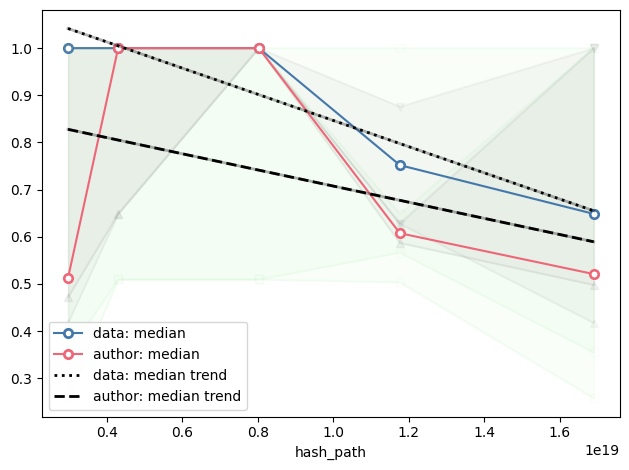

In [112]:
df1 = cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect
df2 = cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect

# data
plt.fill_between(df1.index, df1["ds_max"], df1["ds_min"], color="lightgreen", alpha=0.05)
plt.fill_between(df1.index, df1["ds_p75_cont"], df1["ds_p25_cont"], color="gray", alpha=0.05)
df1["ds_p75_cont"].plot(alpha=0.05, marker="v", color="gray", label="", legend=True)
df1["ds_p25_cont"].plot(alpha=0.05, marker="^", color="gray", label="", legend=True)
df1['ds_min'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df1['ds_max'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df1['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="data: median", legend=True)

# author
plt.fill_between(df2.index, df2["ds_max"], df2["ds_min"], color="lightgreen", alpha=0.05)
plt.fill_between(df2.index, df2["ds_p75_cont"], df2["ds_p25_cont"], color="gray", alpha=0.05)
df2["ds_p75_cont"].plot(alpha=0.1, marker="v", color="gray", label="", legend=True)
df2["ds_p25_cont"].plot(alpha=0.1, marker="^", color="gray", label="", legend=True)
df2['ds_min'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df2['ds_max'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df2['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="author: median", legend=True)

# trends
m, b = np.polyfit(df1.index, df1['ds_med_cont'], 1)
plt.plot(df1.index, df1['ds_med_cont'], 'w.')
plt.plot(df1.index, m*df1.index+b, '-k', alpha=0.3, markersize=0, lw=2, zorder=100, label="")
plt.plot(df1.index, m*df1.index+b, ':k', markersize=0, lw=2, zorder=100, label="data: median trend")

m, b = np.polyfit(df2.index, df2['ds_med_cont'], 1)
plt.plot(df2.index, df2['ds_med_cont'], 'w.')
plt.plot(df2.index, m*df2.index+b, '-k', alpha=0.3, markersize=0, lw=2, zorder=100, label="")
plt.plot(df2.index, m*df2.index+b, '--k', markersize=0, lw=2, zorder=100, label="author: median trend")

leg = plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

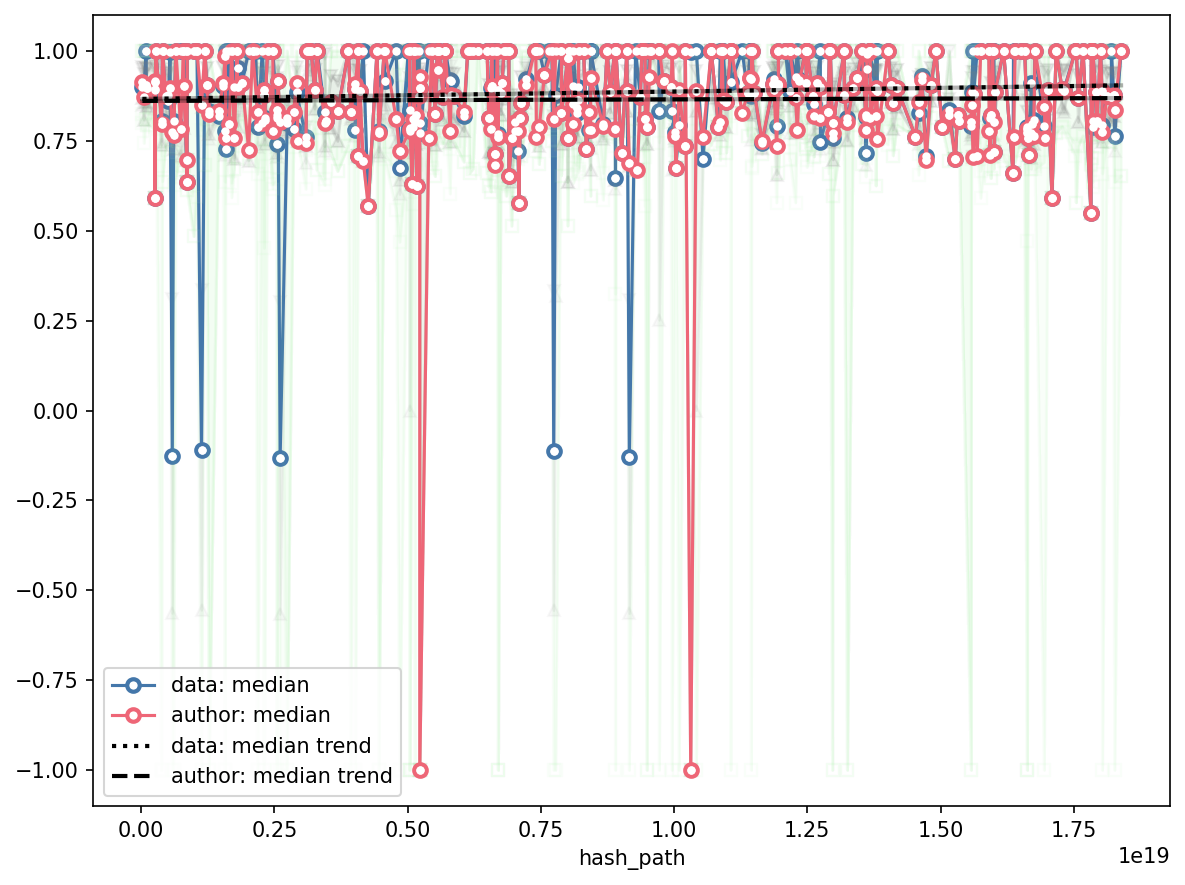

In [113]:
df1 = cons_gt_dwc_t_data_nodes_cos_sim_attributes__path_inspect
df2 = cons_gt_dwc_t_author_nodes_cos_sim_attributes__path_inspect

plt.subplots(figsize=(8,6), dpi=150)

# data
plt.fill_between(df1.index, df1["ds_max"], df1["ds_min"], color="lightgreen", alpha=0.05)
plt.fill_between(df1.index, df1["ds_p75_cont"], df1["ds_p25_cont"], color="gray", alpha=0.05)
df1["ds_p75_cont"].plot(alpha=0.05, marker="v", color="gray", label="", legend=True)
df1["ds_p25_cont"].plot(alpha=0.05, marker="^", color="gray", label="", legend=True)
df1['ds_min'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df1['ds_max'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df1['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="data: median", legend=True)

# author
plt.fill_between(df2.index, df2["ds_max"], df2["ds_min"], color="lightgreen", alpha=0.05)
plt.fill_between(df2.index, df2["ds_p75_cont"], df2["ds_p25_cont"], color="gray", alpha=0.05)
df2["ds_p75_cont"].plot(alpha=0.1, marker="v", color="gray", label="", legend=True)
df2["ds_p25_cont"].plot(alpha=0.1, marker="^", color="gray", label="", legend=True)
df2['ds_min'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df2['ds_max'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df2['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="author: median", legend=True)

# trends
m, b = np.polyfit(df1.index, df1['ds_med_cont'], 1)
plt.plot(df1.index, df1['ds_med_cont'], 'w.')
plt.plot(df1.index, m*df1.index+b, '-k', alpha=0.3, markersize=0, lw=2, zorder=100, label="")
plt.plot(df1.index, m*df1.index+b, ':k', markersize=0, lw=2, zorder=100, label="data: median trend")

m, b = np.polyfit(df2.index, df2['ds_med_cont'], 1)
plt.plot(df2.index, df2['ds_med_cont'], 'w.')
plt.plot(df2.index, m*df2.index+b, '-k', alpha=0.3, markersize=0, lw=2, zorder=100, label="")
plt.plot(df2.index, m*df2.index+b, '--k', markersize=0, lw=2, zorder=100, label="author: median trend")

leg = plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

delta_med.shape=(5,)
delta_med.count()=np.int64(5)
5


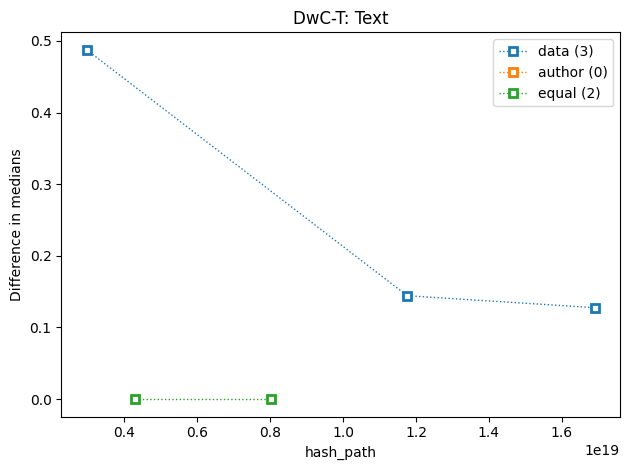


--> top10: data is better:


count    3.000000
mean     0.253197
std      0.203205
min      0.127625
25%      0.135976
50%      0.144327
75%      0.315983
max      0.487639
Name: ds_med_cont, dtype: float64

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
2972828624038042123,{http://rs.tdwg.org/dwc/text/}extension[2]/{ht...,15,15,0.295611,0.735620,1.0,0.257896,1.000000,0.417432,1.000000,0.487639
11761823836042817577,{http://rs.tdwg.org/dwc/text/}extension[3]/{ht...,2,2,0.248102,0.751898,1.0,0.503796,0.751898,0.627847,0.875949,0.144327
16898280223678874349,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,15,15,0.268428,0.654307,1.0,0.257896,0.648550,0.417432,1.000000,0.127625


,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
11761823836042817577,{http://rs.tdwg.org/dwc/text/}extension[3]/{ht...,2,2,0.040979,0.607572,0.64855,0.566593,0.607572,0.587082,0.628061,0.144327
16898280223678874349,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,16,16,0.246570,0.649384,1.00000,0.354693,0.520925,0.497911,1.000000,0.127625
2972828624038042123,{http://rs.tdwg.org/dwc/text/}extension[2]/{ht...,16,16,0.252536,0.638249,1.00000,0.354693,0.512361,0.471848,1.000000,0.487639



--> top10: author is better:


...

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,



--> top10: equal:


count    2.0
mean     0.0
std      0.0
min      0.0
25%      0.0
50%      0.0
75%      0.0
max      0.0
Name: ds_med_cont, dtype: float64

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
4300982297047325395,{http://rs.tdwg.org/dwc/text/}extension/{http:...,61,61,0.169136,0.882493,1.0,0.509599,1.0,0.64855,1.0,0.0
8026162855970452193,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,174,174,0.125650,0.948706,1.0,0.509599,1.0,1.00000,1.0,0.0


,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
4300982297047325395,{http://rs.tdwg.org/dwc/text/}extension/{http:...,62,62,0.175980,0.856045,1.0,0.509599,1.0,0.64855,1.0,0.0
8026162855970452193,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,174,174,0.138226,0.934567,1.0,0.509599,1.0,1.00000,1.0,0.0


In [114]:
df1 = cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect
df2 = cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect

# plt.subplots(figsize=(4.2, 2.8), dpi=300)
plt.title("DwC-T: Text")
plt.ylabel("Difference in medians")

delta_med = (df1["ds_med_cont"] - df2["ds_med_cont"])
print(f"{delta_med.shape=}")
print(f"{delta_med.count()=}")
print(f"{len(set.intersection(set(df1.index), set(df2.index)))}")

df1["ds_delta_med"] = delta_med.dropna()
df2["ds_delta_med"] = delta_med.dropna()

dw = (delta_med[delta_med > 0])
aw = (delta_med[delta_med < 0])
eq = (delta_med[delta_med == 0])
dw.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(0), label=f"data ({dw.count()})", legend=True)
aw.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(1), label=f"author ({aw.count()})", legend=True)
eq.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(2), label=f"equal ({eq.count()})", legend=True)

plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

print("\n--> top10: data is better:")
display(delta_med[delta_med > 0].describe())
data_bs1 = df1.loc[delta_med[delta_med > 0].index]
data_bs2 = df2.loc[delta_med[delta_med > 0].index]
display(data_bs1[data_bs1["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))
display(data_bs2[data_bs2["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))

print("\n--> top10: author is better:")
display(delta_med[delta_med < 0].describe())
author_bs1 = df1.loc[delta_med[delta_med < 0].index]
author_bs2 = df2.loc[delta_med[delta_med < 0].index]
display(author_bs1[author_bs1["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))
display(author_bs2[author_bs2["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))

print("\n--> top10: equal:")
display(delta_med[delta_med == 0].describe())
equal_bs1 = df1.loc[delta_med[delta_med == 0].index]
equal_bs2 = df2.loc[delta_med[delta_med == 0].index]
display(equal_bs1[equal_bs1["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))
display(equal_bs2[equal_bs2["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))

In [115]:
data_bs1[data_bs1["case_count"] > 1]

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
2972828624038042123,{http://rs.tdwg.org/dwc/text/}extension[2]/{ht...,15,15,0.295611,0.735620,1.0,0.257896,1.000000,0.417432,1.000000,0.487639
11761823836042817577,{http://rs.tdwg.org/dwc/text/}extension[3]/{ht...,2,2,0.248102,0.751898,1.0,0.503796,0.751898,0.627847,0.875949,0.144327
16898280223678874349,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,15,15,0.268428,0.654307,1.0,0.257896,0.648550,0.417432,1.000000,0.127625


In [116]:
equal_bs2[equal_bs2["case_count"] > 1]

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
4300982297047325395,{http://rs.tdwg.org/dwc/text/}extension/{http:...,62,62,0.175980,0.856045,1.0,0.509599,1.0,0.64855,1.0,0.0
8026162855970452193,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,174,174,0.138226,0.934567,1.0,0.509599,1.0,1.00000,1.0,0.0


delta_med.shape=(329,)
delta_med.count()=np.int64(313)
313


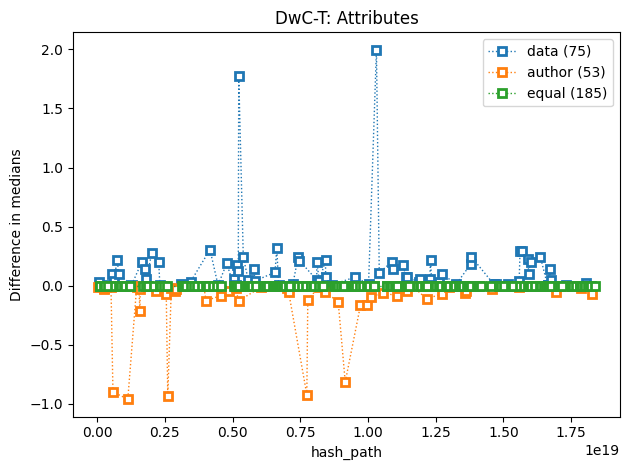


--> top10: data is better:


count    75.000000
mean      0.153019
std       0.303687
min       0.002479
25%       0.019296
50%       0.075533
75%       0.199771
max       1.996424
Name: ds_med_cont, dtype: float64

,path,case_count,ds_count,ds_mean,ds_std_pop,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
2016192542045894237,{http://rs.tdwg.org/dwc/text/}extension/{http:...,6,6,0.949862,0.112111,1.0,0.699175,1.0,1.000000,1.0,0.274405
8433860910468061834,{http://rs.tdwg.org/dwc/text/}extension/{http:...,11,11,0.883576,0.159098,1.0,0.596415,1.0,0.730395,1.0,0.218992
742685101722019265,{http://rs.tdwg.org/dwc/text/}extension/{http:...,9,9,0.918858,0.116429,1.0,0.708375,1.0,0.782153,1.0,0.217847
7470361097938328380,{http://rs.tdwg.org/dwc/text/}extension/{http:...,19,19,0.892813,0.119535,1.0,0.684725,1.0,0.794702,1.0,0.211890
8110182385437510763,{http://rs.tdwg.org/dwc/text/}extension[2]/{ht...,12,12,0.893328,0.133240,1.0,0.631970,1.0,0.779340,1.0,0.203675
10869558986124723211,{http://rs.tdwg.org/dwc/text/}extension/{http:...,28,28,0.905141,0.107082,1.0,0.715097,1.0,0.796010,1.0,0.198396
16002164154506567750,{http://rs.tdwg.org/dwc/text/}extension/{http:...,11,11,0.901988,0.132001,1.0,0.671569,1.0,0.767245,1.0,0.197154
4783625316611376579,{http://rs.tdwg.org/dwc/text/}extension/{http:...,33,33,0.888208,0.119788,1.0,0.665698,1.0,0.779493,1.0,0.188339
13789952408526950589,{http://rs.tdwg.org/dwc/text/}extension/{http:...,13,13,0.899079,0.119440,1.0,0.625128,1.0,0.815345,1.0,0.181332


,path,case_count,ds_count,ds_mean,ds_std_pop,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
5574633861900702745,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,16,16,0.913234,0.089337,1.000000,0.784835,0.947988,0.827837,1.000000,0.052012
9535927439817200247,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,2,2,0.926492,0.073508,1.000000,0.852985,0.926492,0.889739,0.963246,0.073508
11421789015792244818,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,2,2,0.924623,0.075377,1.000000,0.849247,0.924623,0.886935,0.962312,0.075377
11428988430704094261,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,2,2,0.924467,0.075533,1.000000,0.848933,0.924467,0.886700,0.962233,0.075533
8435489327735267015,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,2,2,0.924009,0.075991,1.000000,0.848018,0.924009,0.886014,0.962005,0.075991
14647331967012681332,{http://rs.tdwg.org/dwc/text/}core,174,174,0.909788,0.026783,0.934443,0.837939,0.918513,0.889205,0.934443,0.012229
12353694983162201200,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,2,2,0.916631,0.083369,1.000000,0.833261,0.916631,0.874946,0.958315,0.003364
7229886292365021451,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,2,2,0.904031,0.095969,1.000000,0.808062,0.904031,0.856047,0.952016,0.017108
796597095757983138,{http://rs.tdwg.org/dwc/text/}extension[2]/{ht...,10,10,0.877997,0.121558,1.000000,0.679776,0.903108,0.785853,1.000000,0.096892



--> top10: author is better:


...

,path,case_count,ds_count,ds_mean,ds_std_pop,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
4571708384884154271,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,3,3,0.900009,0.141409,1.0,0.700026,1.000000,0.850013,1.000000,-0.084264
11074962152550503257,{http://rs.tdwg.org/dwc/text/}extension[3]/{ht...,2,2,1.000000,0.000000,1.0,1.000000,1.000000,1.000000,1.000000,-0.085661
12166680672522929366,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,3,3,0.898469,0.143586,1.0,0.695408,1.000000,0.847704,1.000000,-0.112042
7778114079761626509,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,3,3,0.907339,0.131043,1.0,0.722016,1.000000,0.861008,1.000000,-0.121491
9723819997962796166,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,3,3,0.915010,0.120194,1.0,0.745030,1.000000,0.872515,1.000000,-0.165637
9963246539417705938,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,3,3,0.945796,0.076656,1.0,0.837388,1.000000,0.918694,1.000000,-0.166887
13620597439594040475,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,2,2,0.991570,0.008430,1.0,0.983139,0.991570,0.987354,0.995785,-0.043085
1577284285756599315,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,6,6,0.907248,0.134904,1.0,0.635242,0.986882,0.871718,0.997585,-0.210579
5225386531271955165,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,5,5,0.926020,0.069412,1.0,0.819723,0.927292,0.883084,1.000000,-0.128025



--> top10: equal:


count    185.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: ds_med_cont, dtype: float64

,path,case_count,ds_count,ds_mean,ds_std_pop,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
12089992130041892149,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,2,2,1.000000,0.000000,1.0,1.000000,1.0,1.000000,1.0,0.0
12174920399920402605,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,6,6,0.969118,0.069055,1.0,0.814706,1.0,1.000000,1.0,0.0
12468489015907556986,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,70,70,0.985673,0.049501,1.0,0.738835,1.0,1.000000,1.0,0.0
12474991930651873160,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,89,89,0.983035,0.058831,1.0,0.727875,1.0,1.000000,1.0,0.0
12495403856581225033,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,144,144,0.977413,0.065218,1.0,0.676333,1.0,1.000000,1.0,0.0
12914711030843703932,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,33,33,0.985521,0.060548,1.0,0.658040,1.0,1.000000,1.0,0.0
12932270312845408710,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,41,41,0.986373,0.049511,1.0,0.783563,1.0,1.000000,1.0,0.0
13193908991315726381,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,4,4,0.957697,0.073271,1.0,0.830788,1.0,0.957697,1.0,0.0
11958825907414261065,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,123,123,0.973531,0.081720,1.0,0.660102,1.0,1.000000,1.0,0.0


,path,case_count,ds_count,ds_mean,ds_std_pop,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
12174920399920402605,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,6,6,0.949882,0.112067,1.0,0.699293,1.0,1.000000,1.0,0.0
12468489015907556986,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,70,70,0.985906,0.048796,1.0,0.738835,1.0,1.000000,1.0,0.0
12474991930651873160,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,86,86,0.982443,0.059761,1.0,0.727875,1.0,1.000000,1.0,0.0
12495403856581225033,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,143,143,0.968711,0.073369,1.0,0.695484,1.0,1.000000,1.0,0.0
12914711030843703932,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,32,32,0.982913,0.065372,1.0,0.658040,1.0,1.000000,1.0,0.0
12932270312845408710,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,40,40,0.985818,0.050610,1.0,0.783563,1.0,1.000000,1.0,0.0
13193908991315726381,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,4,4,0.950025,0.086559,1.0,0.800100,1.0,0.950025,1.0,0.0
13527601378810507750,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,14,14,0.953459,0.096842,1.0,0.686952,1.0,1.000000,1.0,0.0
11958825907414261065,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,120,120,0.968569,0.085726,1.0,0.660102,1.0,1.000000,1.0,0.0


In [117]:
df1 = cons_gt_dwc_t_data_nodes_cos_sim_attributes__path_inspect
df2 = cons_gt_dwc_t_author_nodes_cos_sim_attributes__path_inspect

# plt.subplots(figsize=(4.2, 3.2), dpi=120)
plt.title("DwC-T: Attributes")
plt.ylabel("Difference in medians")

delta_med = (df1["ds_med_cont"] - df2["ds_med_cont"])
print(f"{delta_med.shape=}")
print(f"{delta_med.count()=}")
print(f"{len(set.intersection(set(df1.index), set(df2.index)))}")

df1["ds_delta_med"] = delta_med.dropna()
df2["ds_delta_med"] = delta_med.dropna()

dw = (delta_med[delta_med > 0])
aw = (delta_med[delta_med < 0])
eq = (delta_med[delta_med == 0])
dw.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(0), label=f"data ({dw.count()})", legend=True)
aw.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(1), label=f"author ({aw.count()})", legend=True)
eq.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(2), label=f"equal ({eq.count()})", legend=True)

plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

print("\n--> top10: data is better:")
display(delta_med[delta_med > 0].describe())
data_bs1 = df1.loc[delta_med[delta_med > 0].index]
data_bs2 = df2.loc[delta_med[delta_med > 0].index]
display(data_bs1[data_bs1["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))
display(data_bs2[data_bs2["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))

print("\n--> top10: author is better:")
display(delta_med[delta_med < 0].describe())
author_bs1 = df1.loc[delta_med[delta_med < 0].index]
author_bs2 = df2.loc[delta_med[delta_med < 0].index]
display(author_bs1[author_bs1["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))
display(author_bs2[author_bs2["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))

print("\n--> top10: equal:")
display(delta_med[delta_med == 0].describe())
equal_bs1 = df1.loc[delta_med[delta_med == 0].index]
equal_bs2 = df2.loc[delta_med[delta_med == 0].index]
display(equal_bs1[equal_bs1["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))
display(equal_bs2[equal_bs2["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))

In [118]:
data_bs1[(data_bs1['ds_delta_med'] >= 0.75 * data_bs1['ds_delta_med'].max())]

,path,case_count,ds_count,ds_mean,ds_std_pop,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
5227831486160219788,.,171,171,0.156192,0.839783,0.771236,-1.000000,0.771236,-1.000000,0.771236,1.771236
10312634465911785389,{http://rs.tdwg.org/dwc/text/}extension/{http:...,1,1,0.996424,0.000000,0.996424,0.996424,0.996424,0.996424,0.996424,1.996424


In [119]:
author_bs2[(author_bs2['ds_delta_med'] <= 0.7 * author_bs2['ds_delta_med'].min())]

,path,case_count,ds_count,ds_mean,ds_std_pop,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
583175147555563270,{http://rs.tdwg.org/dwc/text/}extension[3]/{ht...,2,2,0.773274,0.039224,0.812498,0.734050,0.773274,0.753662,0.792886,-0.900026
1131754085949918688,{http://rs.tdwg.org/dwc/text/}extension[3]/{ht...,2,2,0.849948,0.009528,0.859475,0.840420,0.849948,0.845184,0.854712,-0.960280
2606986402503102736,{http://rs.tdwg.org/dwc/text/}extension[3]/{ht...,2,2,0.802846,0.043296,0.846141,0.759550,0.802846,0.781198,0.824494,-0.935084
7741584035691069954,{http://rs.tdwg.org/dwc/text/}extension[3]/{ht...,2,2,0.810121,0.018845,0.828966,0.791276,0.810121,0.800698,0.819543,-0.922038
9160188200530993964,{http://rs.tdwg.org/dwc/text/}extension[3]/{ht...,2,2,0.687612,0.015409,0.703021,0.672203,0.687612,0.679907,0.695316,-0.815881


In [120]:
data_bs1[data_bs1["path"] == "{http://rs.tdwg.org/dwc/text/}core"]

,path,case_count,ds_count,ds_mean,ds_std_pop,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
14647331967012681332,{http://rs.tdwg.org/dwc/text/}core,174,174,0.912495,0.02748,0.960939,0.83471,0.930741,0.893119,0.934443,0.012229


In [121]:
data_bs2[data_bs2["path"] == "{http://rs.tdwg.org/dwc/text/}core"]

,path,case_count,ds_count,ds_mean,ds_std_pop,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
14647331967012681332,{http://rs.tdwg.org/dwc/text/}core,174,174,0.909788,0.026783,0.934443,0.837939,0.918513,0.889205,0.934443,0.012229


In [122]:
%%sql
SELECT
  c.path,
  (c.cons_attributes :: JSON)->'rowType',
  (c.gt_attributes :: JSON)->'rowType',
  AVG(c.cos_sim_attributes),
  COUNT(1)
FROM cons_gt_dwc_t_data_nodes_cos_sim_attributes AS c
WHERE c.path = '{http://rs.tdwg.org/dwc/text/}core'
GROUP BY 1,2,3
ORDER BY 4 DESC, 5

Running query in 'duckdb'

,path,"(CAST(c.cons_attributes AS ""JSON"") -> 'rowType')","(CAST(c.gt_attributes AS ""JSON"") -> 'rowType')",avg(c.cos_sim_attributes),count(1)
0,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Occurrence""",0.923731,111
1,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Taxon""","""http://rs.tdwg.org/dwc/terms/Taxon""",0.922013,5
2,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Event""","""http://rs.tdwg.org/dwc/terms/Event""",0.912074,28
3,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Event""","""http://rs.tdwg.org/dwc/terms/Occurrence""",0.890881,5
4,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Taxon""",0.872423,1
5,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Event""",0.865213,24


In [123]:
%%sql
SELECT
  c.path,
  (c.cons_attributes :: JSON)->'rowType',
  (c.gt_attributes :: JSON)->'rowType',
  AVG(c.cos_sim_attributes),
  COUNT(1)
FROM cons_gt_dwc_t_author_nodes_cos_sim_attributes AS c
WHERE c.path = '{http://rs.tdwg.org/dwc/text/}core'
GROUP BY 1,2,3
ORDER BY 4 DESC, 5

Running query in 'duckdb'

,path,"(CAST(c.cons_attributes AS ""JSON"") -> 'rowType')","(CAST(c.gt_attributes AS ""JSON"") -> 'rowType')",avg(c.cos_sim_attributes),count(1)
0,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Occurrence""",0.920054,113
1,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Taxon""","""http://rs.tdwg.org/dwc/terms/Taxon""",0.912334,6
2,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Event""","""http://rs.tdwg.org/dwc/terms/Event""",0.909286,23
3,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Event""",0.873453,31
4,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Taxon""",0.872423,1


### EML

In [198]:
%%sql cons_gt_eml_data_nodes_cos_sim_text__path_inspect <<
CREATE OR REPLACE TABLE cons_gt_eml_data_nodes_cos_sim_text__path_inspect AS (
  SELECT
    c.path,
    c.tag,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_text) as ds_count,
    stddev_pop(cos_sim_text) as ds_std_pop,
    AVG(cos_sim_text) as ds_mean,
    MAX(cos_sim_text) as ds_max,
    MIN(cos_sim_text) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p75_cont,
  FROM cons_gt_eml_data_nodes_cos_sim_text as c
  GROUP BY c.path, hash_path, c.tag
);
SELECT * FROM cons_gt_eml_data_nodes_cos_sim_text__path_inspect;

Running query in 'duckdb'

In [212]:
%%sql cons_gt_eml_data_nodes_cos_sim_text__tag_inspect <<
CREATE OR REPLACE TABLE cons_gt_eml_data_nodes_cos_sim_text__tag_inspect AS (
  SELECT
    c.tag,
    COUNT(c.path) as path_count,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_text) as ds_count,
    stddev_pop(cos_sim_text) as ds_std_pop,
    AVG(cos_sim_text) as ds_mean,
    MAX(cos_sim_text) as ds_max,
    MIN(cos_sim_text) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p75_cont,
  FROM cons_gt_eml_data_nodes_cos_sim_text as c
  GROUP BY c.tag
);
SELECT * FROM cons_gt_eml_data_nodes_cos_sim_text__tag_inspect;

Running query in 'duckdb'

In [224]:
%%sql
SELECT * 
FROM cons_gt_eml_data_nodes_cos_sim_text__tag_inspect
ORDER BY ds_med_cont;

Running query in 'duckdb'

,tag,path_count,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
0,url,1,1,1,0.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
1,surName,107,107,107,0.788032,-0.252683,1.000000,-1.000000,-1.000000,-1.000000,0.349297
2,userId,19,19,19,0.577237,-0.561676,0.412435,-1.000000,-1.000000,-1.000000,0.112197
3,electronicMailAddress,1,1,1,0.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
4,maintenanceUpdateFrequency,145,145,145,0.571771,-0.697019,1.000000,-1.000000,-1.000000,-1.000000,-1.000000
5,para,257,257,257,0.620319,-0.527712,0.753914,-1.000000,-1.000000,-1.000000,0.112207
6,givenName,2,2,2,1.000000,0.000000,1.000000,-1.000000,0.000000,-0.500000,0.500000
7,descriptorValue,11,11,11,0.603237,-0.065364,0.686205,-1.000000,0.180205,-0.527652,0.363356
8,title,251,251,251,0.799967,-0.034547,1.000000,-1.000000,0.201651,-1.000000,0.698800
9,role,67,67,67,0.367721,0.217190,0.510540,-1.000000,0.336352,0.161149,0.344871


In [197]:
%%sql cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect <<
CREATE OR REPLACE TABLE cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect AS (
  SELECT
    c.path,
    c.tag,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_attributes) as ds_count,
    stddev_pop(cos_sim_attributes) as ds_std_pop,
    AVG(cos_sim_attributes) as ds_mean,
    MAX(cos_sim_attributes) as ds_max,
    MIN(cos_sim_attributes) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p75_cont,
  FROM cons_gt_eml_data_nodes_cos_sim_attributes as c
  GROUP BY c.path, hash_path, c.tag
);
SELECT * FROM cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect;

Running query in 'duckdb'

In [214]:
%%sql cons_gt_eml_data_nodes_cos_sim_attributes__tag_inspect <<
CREATE OR REPLACE TABLE cons_gt_eml_data_nodes_cos_sim_attributes__tag_inspect AS (
  SELECT
    c.tag,
    COUNT(c.path) as path_count,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_attributes) as ds_count,
    stddev_pop(cos_sim_attributes) as ds_std_pop,
    AVG(cos_sim_attributes) as ds_mean,
    MAX(cos_sim_attributes) as ds_max,
    MIN(cos_sim_attributes) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p75_cont,
  FROM cons_gt_eml_data_nodes_cos_sim_attributes as c
  GROUP BY c.tag
);
SELECT * FROM cons_gt_eml_data_nodes_cos_sim_attributes__tag_inspect;

Running query in 'duckdb'

In [223]:
%%sql
SELECT *
FROM cons_gt_eml_data_nodes_cos_sim_attributes__tag_inspect
ORDER BY ds_med_cont;

Running query in 'duckdb'

,tag,path_count,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
0,{https://eml.ecoinformatics.org/eml-2.2.0}eml,150,150,150,0.750955,-0.326917,0.641369,-1.000000,-1.000000,-1.000000,0.483100
1,descriptor,11,11,11,0.020384,0.794280,0.800726,0.729819,0.800726,0.800726,0.800726
2,userId,19,19,19,0.122763,0.956124,0.990047,0.436759,0.990047,0.978640,0.990047


In [200]:
%%sql cons_gt_eml_author_nodes_cos_sim_text__path_inspect <<
CREATE OR REPLACE TABLE cons_gt_eml_author_nodes_cos_sim_text__path_inspect AS (
  SELECT
    c.path,
    c.tag,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_text) as ds_count,
    stddev_pop(cos_sim_text) as ds_std_pop,
    AVG(cos_sim_text) as ds_mean,
    MAX(cos_sim_text) as ds_max,
    MIN(cos_sim_text) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p75_cont,
  FROM cons_gt_eml_author_nodes_cos_sim_text as c
  GROUP BY c.path, c.tag, hash_path
);
SELECT * FROM cons_gt_eml_author_nodes_cos_sim_text__path_inspect;

Running query in 'duckdb'

In [215]:
%%sql cons_gt_eml_author_nodes_cos_sim_text__tag_inspect <<
CREATE OR REPLACE TABLE cons_gt_eml_author_nodes_cos_sim_text__tag_inspect AS (
  SELECT
    c.tag,
    COUNT(c.path) as path_count,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_text) as ds_count,
    stddev_pop(cos_sim_text) as ds_std_pop,
    AVG(cos_sim_text) as ds_mean,
    MAX(cos_sim_text) as ds_max,
    MIN(cos_sim_text) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p75_cont,
  FROM cons_gt_eml_author_nodes_cos_sim_text as c
  GROUP BY c.tag
);
SELECT * FROM cons_gt_eml_author_nodes_cos_sim_text__tag_inspect;

Running query in 'duckdb'

In [222]:
%%sql
SELECT * 
FROM cons_gt_eml_author_nodes_cos_sim_text__tag_inspect
ORDER BY ds_med_cont;

Running query in 'duckdb'

,tag,path_count,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
0,maintenanceUpdateFrequency,142,142,142,0.667261,-0.394899,1.000000,-1.000000,-1.000000,-1.000000,0.226280
1,userId,17,17,17,0.283711,-0.929072,0.205773,-1.000000,-1.000000,-1.000000,-1.000000
2,electronicMailAddress,1,1,1,0.000000,0.152196,0.152196,0.152196,0.152196,0.152196,0.152196
3,surName,96,96,96,0.826356,-0.131647,1.000000,-1.000000,0.170275,-1.000000,0.483922
4,descriptorValue,11,11,11,0.716490,-0.081720,0.685300,-1.000000,0.176647,-1.000000,0.575361
5,para,253,253,253,0.738539,-0.171575,0.973497,-1.000000,0.189941,-1.000000,0.480115
6,role,63,63,63,0.127275,0.304167,0.510540,0.083198,0.336352,0.218390,0.344871
7,geographicDescription,2,2,2,0.051234,0.569407,0.620641,0.518173,0.569407,0.543790,0.595024
8,title,247,247,247,0.827198,0.256764,1.000000,-1.000000,0.657472,-1.000000,0.999810
9,givenName,2,2,2,0.093185,0.906815,1.000000,0.813631,0.906815,0.860223,0.953408


In [201]:
%%sql cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect <<
CREATE OR REPLACE TABLE cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect AS (
  SELECT
    c.path,
    c.tag,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_attributes) as ds_count,
    stddev_pop(cos_sim_attributes) as ds_std_pop,
    AVG(cos_sim_attributes) as ds_mean,
    MAX(cos_sim_attributes) as ds_max,
    MIN(cos_sim_attributes) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p75_cont,
  FROM cons_gt_eml_author_nodes_cos_sim_attributes as c
  GROUP BY c.path, c.tag, hash_path
);
SELECT * FROM cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect;

Running query in 'duckdb'

In [217]:
%%sql cons_gt_eml_author_nodes_cos_sim_attributes__tag_inspect <<
CREATE OR REPLACE TABLE cons_gt_eml_author_nodes_cos_sim_attributes__tag_inspect AS (
  SELECT
    c.tag,
    COUNT(c.path) AS path_count,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_attributes) as ds_count,
    stddev_pop(cos_sim_attributes) as ds_std_pop,
    AVG(cos_sim_attributes) as ds_mean,
    MAX(cos_sim_attributes) as ds_max,
    MIN(cos_sim_attributes) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p75_cont,
  FROM cons_gt_eml_author_nodes_cos_sim_attributes as c
  GROUP BY c.tag
);
SELECT * FROM cons_gt_eml_author_nodes_cos_sim_attributes__tag_inspect;

Running query in 'duckdb'

In [218]:
%%sql
SELECT * 
FROM cons_gt_eml_author_nodes_cos_sim_attributes__tag_inspect;

Running query in 'duckdb'

,tag,path_count,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
0,{https://eml.ecoinformatics.org/eml-2.2.0}eml,148,148,148,0.767376,-0.203244,0.669076,-1.000000,0.369986,-1.000000,0.546553
1,userId,17,17,17,0.129199,0.952133,0.990047,0.436759,0.990047,0.967233,0.990047
2,descriptor,11,11,11,0.027349,0.787834,0.800726,0.729819,0.800726,0.800726,0.800726


Running query in 'duckdb'

Running query in 'duckdb'

,hash_tag,treatment,path_count,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
count,1.200000e+01,12.0,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000
mean,9.270988e+18,0.0,72.000000,72.000000,72.000000,0.444024,-0.188034,0.502375,-0.694550,-0.301366,-0.516758,0.095511
std,3.827714e+18,0.0,97.373694,97.373694,97.373694,0.361699,0.618999,0.731388,0.716936,0.771019,0.725677,0.705160
min,3.283000e+18,0.0,1.000000,1.000000,1.000000,0.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
25%,7.017264e+18,0.0,1.750000,1.750000,1.750000,0.000000,-0.595512,0.486014,-1.000000,-1.000000,-1.000000,-0.165852
50%,9.337914e+18,0.0,15.000000,15.000000,15.000000,0.574504,-0.159024,0.720059,-1.000000,-0.500000,-1.000000,0.347084
75%,1.263344e+19,0.0,116.500000,116.500000,116.500000,0.662247,0.054297,1.000000,-1.000000,0.235326,-0.334713,0.541350
max,1.536263e+19,0.0,257.000000,257.000000,257.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


,hash_tag,treatment,path_count,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
count,1.000000e+01,10.0,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000
mean,8.538755e+18,1.0,83.400000,83.400000,83.400000,0.433125,0.048044,0.714795,-0.443280,0.115911,-0.422540,0.381099
std,3.608340e+18,0.0,99.571526,99.571526,99.571526,0.350108,0.513986,0.336546,0.745029,0.639186,0.768921,0.557707
min,3.283000e+18,1.0,1.000000,1.000000,1.000000,0.000000,-0.929072,0.152196,-1.000000,-1.000000,-1.000000,-1.000000
25%,6.574447e+18,1.0,4.250000,4.250000,4.250000,0.101707,-0.161593,0.538066,-1.000000,0.156716,-1.000000,0.255927
50%,7.849297e+18,1.0,40.000000,40.000000,40.000000,0.475486,0.035238,0.829399,-1.000000,0.183294,-1.000000,0.482019
75%,1.214587e+19,1.0,130.500000,130.500000,130.500000,0.733027,0.292316,1.000000,0.134947,0.511143,0.201842,0.590109
max,1.294487e+19,1.0,253.000000,253.000000,253.000000,0.827198,0.906815,1.000000,0.813631,0.906815,0.860223,0.999810


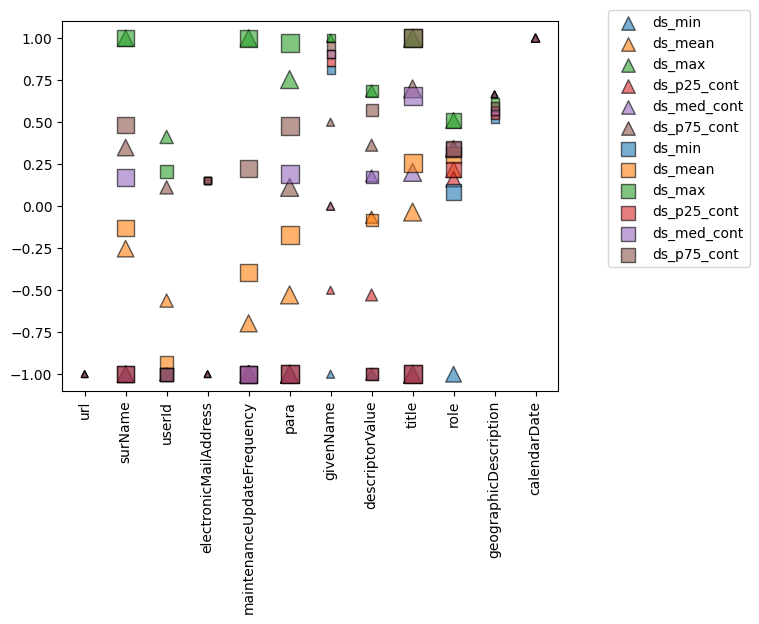

In [283]:
%sql eml_data_text__tag << SELECT hash(tag) AS hash_tag, 0 as treatment, *  FROM cons_gt_eml_data_nodes_cos_sim_text__tag_inspect ORDER BY ds_med_cont;
%sql eml_author_text__tag << SELECT hash(tag) AS hash_tag, 1 as treatment, *  FROM cons_gt_eml_author_nodes_cos_sim_text__tag_inspect ORDER BY ds_med_cont;

display(eml_data_text__tag.describe())
display(eml_author_text__tag.describe())

for (df, m) in zip([eml_data_text__tag, eml_author_text__tag], ["^","s"]):
    for i, c in enumerate(["ds_min", "ds_mean", "ds_max", "ds_p25_cont", "ds_med_cont", "ds_p75_cont"]):
        plt.scatter(
            df["tag"], 
            df[c],
            s=np.log1p(df["path_count"]) * 30,
            label=c,
            alpha=0.6,
            edgecolor="k",
            marker=m,
            facecolor=mpl.cm.tab10(i),
            # offsets=(0,1)
        )
plt.xticks(rotation=90)
plt.legend(loc="upper right", bbox_to_anchor=(1.4, 1.05))
plt.show()

In [291]:
from scipy.stats import mannwhitneyu, ttest_ind

( 
    mannwhitneyu(eml_data_text__tag["ds_med_cont"], eml_author_text__tag["ds_med_cont"], alternative="greater"),
    ttest_ind(eml_data_text__tag["ds_med_cont"], eml_author_text__tag["ds_med_cont"], equal_var=False, alternative="greater")
)

(MannwhitneyuResult(statistic=np.float64(44.5), pvalue=np.float64(0.8602128181459963)),
 TtestResult(statistic=np.float64(-1.3878794115846558), pvalue=np.float64(0.9097784895793499), df=np.float64(19.99968632528288)))

In [202]:
cons_gt_eml_data_nodes_cos_sim_text__path_inspect = (
    cons_gt_eml_data_nodes_cos_sim_text__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)
cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect = (
    cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)
cons_gt_eml_author_nodes_cos_sim_text__path_inspect = (
    cons_gt_eml_author_nodes_cos_sim_text__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)
cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect = (
    cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)

In [203]:
set(cons_gt_eml_data_nodes_cos_sim_text__path_inspect["path"].unique()) == set(cons_gt_eml_author_nodes_cos_sim_text__path_inspect["path"].unique())

False

In [204]:
set(cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect["path"].unique()) == set(cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect["path"].unique())

False

In [205]:
print(f"{cons_gt_eml_data_nodes_cos_sim_text__path_inspect.shape=}")
print(f"{cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect.shape=}")

print(f"{cons_gt_eml_author_nodes_cos_sim_text__path_inspect.shape=}")
print(f"{cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect.shape=}")


cons_gt_eml_data_nodes_cos_sim_text__path_inspect.shape=(46, 11)
cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect.shape=(5, 11)
cons_gt_eml_author_nodes_cos_sim_text__path_inspect.shape=(29, 11)
cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect.shape=(3, 11)


In [210]:
%%sql
SELECT c.path, c.tag, ds_mean, ds_count
FROM cons_gt_eml_data_nodes_cos_sim_text__path_inspect AS c
ORDER BY c.path, c.tag;

Running query in 'duckdb'

,path,tag,ds_mean,ds_count
0,dataset/abstract/para,para,0.326020,11
1,dataset/contact/electronicMailAddress,electronicMailAddress,-1.000000,1
2,dataset/contact/individualName/givenName,givenName,1.000000,1
3,dataset/contact/individualName/surName,surName,1.000000,1
4,dataset/coverage/geographicCoverage/geographic...,geographicDescription,0.665401,1
5,dataset/coverage/temporalCoverage/rangeOfDates...,calendarDate,1.000000,1
6,dataset/coverage/temporalCoverage/rangeOfDates...,calendarDate,1.000000,1
7,dataset/creator/individualName/givenName,givenName,-1.000000,1
8,dataset/creator/individualName/surName,surName,-0.370711,30
9,dataset/creator/userId,userId,-0.644776,17


In [211]:
%%sql
SELECT c.path, c.tag, ds_mean, ds_count
FROM cons_gt_eml_author_nodes_cos_sim_text__path_inspect AS c
ORDER BY c.path;

Running query in 'duckdb'

,path,tag,ds_mean,ds_count
0,dataset/abstract/para,para,0.135898,7
1,dataset/contact/electronicMailAddress,electronicMailAddress,0.152196,1
2,dataset/contact/individualName/surName,surName,-1.000000,1
3,dataset/coverage/geographicCoverage/geographic...,geographicDescription,0.569407,2
4,dataset/creator/individualName/surName,surName,-0.256875,28
5,dataset/creator/userId,userId,-0.929072,17
6,dataset/intellectualRights/para,para,0.412951,1
7,dataset/maintenance/description/para,para,-0.113371,8
8,dataset/maintenance/maintenanceUpdateFrequency,maintenanceUpdateFrequency,-0.394899,142
9,dataset/methods/methodStep/description/para,para,-0.099486,72


In [134]:
%%sql
SELECT c.path, ds_mean, ds_count
FROM cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect AS c
ORDER BY c.path;

Running query in 'duckdb'

,path,ds_mean,ds_count
0,.,-0.326917,150
1,dataset/creator/userId,0.952133,17
2,dataset/creator[1]/userId,0.990047,1
3,dataset/creator[2]/userId,0.990047,1
4,dataset/project/studyAreaDescription/descriptor,0.794280,11


In [135]:
%%sql
SELECT c.path, ds_mean, ds_count
FROM cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect AS c
ORDER BY c.path;

Running query in 'duckdb'

,path,ds_mean,ds_count
0,.,-0.203244,148
1,dataset/creator/userId,0.952133,17
2,dataset/project/studyAreaDescription/descriptor,0.787834,11


#### Inspections EML

In [302]:
display(cons_gt_eml_data_nodes_cos_sim_text.describe(include="all"))
display(cons_gt_eml_author_nodes_cos_sim_text.describe(include="all"))

,case_id,path,tag,cons_text,gt_text,cos_sim_text
count,864.000000,864,864,864,864,864.000000
unique,NaN,46,12,332,619,NaN
top,NaN,dataset/title,para,not-derived-011,unkown,NaN
freq,NaN,150,257,90,53,NaN
mean,83.092593,NaN,NaN,NaN,NaN,-0.310847
std,52.995360,NaN,NaN,NaN,NaN,0.741166
min,0.000000,NaN,NaN,NaN,NaN,-1.000000
25%,39.000000,NaN,NaN,NaN,NaN,-1.000000
50%,79.000000,NaN,NaN,NaN,NaN,-1.000000
75%,130.000000,NaN,NaN,NaN,NaN,0.333287


,case_id,path,tag,cons_text,gt_text,cos_sim_text
count,834.000000,834,834,834,834,834.000000
unique,NaN,29,10,443,605,NaN
top,NaN,dataset/title,para,not-derived-011,unkown,NaN
freq,NaN,148,253,59,53,NaN
mean,88.726619,NaN,NaN,NaN,NaN,-0.051712
std,51.816437,NaN,NaN,NaN,NaN,0.784029
min,0.000000,NaN,NaN,NaN,NaN,-1.000000
25%,46.250000,NaN,NaN,NaN,NaN,-1.000000
50%,87.000000,NaN,NaN,NaN,NaN,0.223745
75%,137.750000,NaN,NaN,NaN,NaN,0.589701


In [297]:
mannwhitneyu(
    cons_gt_eml_data_nodes_cos_sim_text["cos_sim_text"], 
    cons_gt_eml_author_nodes_cos_sim_text["cos_sim_text"],
)

MannwhitneyuResult(statistic=np.float64(290159.0), pvalue=np.float64(3.3356968870618537e-13))

In [301]:
ttest_ind(
    cons_gt_eml_data_nodes_cos_sim_text["cos_sim_text"], 
    cons_gt_eml_author_nodes_cos_sim_text["cos_sim_text"],
    equal_var=False
)

TtestResult(statistic=np.float64(-6.99383152684838), pvalue=np.float64(3.845690325341759e-12), df=np.float64(1681.930531187666))

In [377]:
cohen_d(
    cons_gt_eml_data_nodes_cos_sim_text["cos_sim_text"], 
    cons_gt_eml_author_nodes_cos_sim_text["cos_sim_text"],
)

np.float64(-0.33984063739159875)

In [398]:
display(cons_gt_eml_data_nodes_cos_sim_text.groupby(["tag", "path"])["cos_sim_text"].describe())
display(cons_gt_eml_author_nodes_cos_sim_text.groupby(["tag", "path"])["cos_sim_text"].describe())

count  \
tag                        path                                                        
calendarDate               dataset/coverage/temporalCoverage/rangeOfDates/...    1.0   
                           dataset/coverage/temporalCoverage/rangeOfDates/...    1.0   
descriptorValue            dataset/project/studyAreaDescription/descriptor...   11.0   
electronicMailAddress      dataset/contact/electronicMailAddress                 1.0   
geographicDescription      dataset/coverage/geographicCoverage/geographicD...    1.0   
givenName                  dataset/contact/individualName/givenName              1.0   
                           dataset/creator/individualName/givenName              1.0   
maintenanceUpdateFrequency dataset/maintenance/maintenanceUpdateFrequency      145.0   
para                       dataset/abstract/para                                11.0   
                           dataset/intellectualRights/para                       1.0   
                           dataset/maintenance/description/para                  9.0   
                           dataset/methods/methodStep/description/para          67.0   
                           dataset/methods/methodStep[1]/description/para        4.0   
                           dataset/methods/methodStep[2]/description/para        4.0   
                           dataset/methods/qualityControl/description/para      75.0   
                           dataset/methods/sampling/samplingDescription/para     3.0   
                           dataset/methods/sampling/studyExtent/descriptio...    3.0   
                           dataset/project/abstract/para                         2.0   
                           dataset/project/designDescription/description/para    3.0   
                           dataset/project/funding/para                         75.0   
role                       dataset/project/personnel/role                       21.0   
                           dataset/project/personnel[1]/role                    18.0   
                           dataset/project/personnel[2]/role                    18.0   
                           dataset/project/personnel[3]/role                     4.0   
                           dataset/project/personnel[4]/role                     2.0   
                           dataset/project/personnel[5]/role                     2.0   
                           dataset/project/personnel[6]/role                     1.0   
                           dataset/project/personnel[7]/role                     1.0   
surName                    dataset/contact/individualName/surName                1.0   
                           dataset/creator/individualName/surName               30.0   
                           dataset/creator[1]/individualName/surName             1.0   
                           dataset/creator[2]/individualName/surName             1.0   
                           dataset/project/personnel/individualName/surName     26.0   
                           dataset/project/personnel[1]/individualName/sur...   19.0   
                           dataset/project/personnel[2]/individualName/sur...   19.0   
                           dataset/project/personnel[3]/individualName/sur...    4.0   
                           dataset/project/personnel[4]/individualName/sur...    2.0   
                           dataset/project/personnel[5]/individualName/sur...    2.0   
                           dataset/project/personnel[6]/individualName/sur...    1.0   
                           dataset/project/personnel[7]/individualName/sur...    1.0   
title                      dataset/project/title                               101.0   
                           dataset/title                                       150.0   
url                        dataset/distribution/online/url                       1.0   
userId                     dataset/creator/userId                               17.0   
                           data

count  \
tag                        path                                                        
descriptorValue            dataset/project/studyAreaDescription/descriptor...   11.0   
electronicMailAddress      dataset/contact/electronicMailAddress                 1.0   
geographicDescription      dataset/coverage/geographicCoverage/geographicD...    2.0   
givenName                  dataset/project/personnel[1]/individualName/giv...    1.0   
                           dataset/project/personnel[2]/individualName/giv...    1.0   
maintenanceUpdateFrequency dataset/maintenance/maintenanceUpdateFrequency      142.0   
para                       dataset/abstract/para                                 7.0   
                           dataset/intellectualRights/para                       1.0   
                           dataset/maintenance/description/para                  8.0   
                           dataset/methods/methodStep/description/para          72.0   
                           dataset/methods/methodStep[1]/description/para        7.0   
                           dataset/methods/methodStep[2]/description/para        8.0   
                           dataset/methods/methodStep[3]/description/para        3.0   
                           dataset/methods/qualityControl/description/para      68.0   
                           dataset/project/abstract/para                         2.0   
                           dataset/project/funding/para                         77.0   
role                       dataset/project/personnel/role                       22.0   
                           dataset/project/personnel[1]/role                    19.0   
                           dataset/project/personnel[2]/role                    19.0   
                           dataset/project/personnel[3]/role                     3.0   
surName                    dataset/contact/individualName/surName                1.0   
                           dataset/creator/individualName/surName               28.0   
                           dataset/project/personnel/individualName/surName     26.0   
                           dataset/project/personnel[1]/individualName/sur...   19.0   
                           dataset/project/personnel[2]/individualName/sur...   19.0   
                           dataset/project/personnel[3]/individualName/sur...    3.0   
title                      dataset/project/title                                99.0   
                           dataset/title                                       148.0   
userId                     dataset/creator/userId                               17.0   

                                                                                   mean  \
tag                        path                                                           
descriptorValue            dataset/project/studyAreaDescription/descriptor... -0.081720   
electronicMailAddress      dataset/contact/electronicMailAddress               0.152196   
geographicDescription      dataset/coverage/geographicCoverage/geographicD...  0.569407   
givenName                  dataset/project/personnel[1]/individualName/giv...  1.000000   
                           dataset/project/personnel[2]/individualName/giv...  0.813631   
maintenanceUpdateFrequency dataset/maintenance/maintenanceUpdateFrequency     -0.394899   
para                       dataset/abstract/para                               0.135898   
                           dataset/intellectualRights/para                     0.412951   
                           dataset/maintenance/description/para               -0.113371   
                           dataset/methods/methodStep/description/para        -0.099486   
                           dataset/methods/methodStep[1]/description/para     -0.096990   
                           dataset/methods/methodStep[2]/description/para      0.181310   
                           dataset/methods/methodStep[3]/description/para   

In [376]:
shared_tags = list(set.intersection(
    set(cons_gt_eml_data_nodes_cos_sim_text["tag"].tolist()),
    set(cons_gt_eml_author_nodes_cos_sim_text["tag"].tolist())
))

for t in shared_tags:
    print("---")
    print(f"Tag: {t}")
    subdf1 = cons_gt_eml_data_nodes_cos_sim_text[cons_gt_eml_data_nodes_cos_sim_text["tag"] == t]
    subdf2 = cons_gt_eml_author_nodes_cos_sim_text[cons_gt_eml_author_nodes_cos_sim_text["tag"] == t]
    display(subdf1.describe().to_latex())
    display(subdf2.describe().to_latex())
    display(ttest_ind(
        subdf1["cos_sim_text"], 
        subdf2["cos_sim_text"],
        equal_var=False
    ))
    display(mannwhitneyu(
        subdf1["cos_sim_text"], 
        subdf2["cos_sim_text"],
        alternative="greater"
    ))
    display(cohen_d(
        subdf1["cos_sim_text"], 
        subdf2["cos_sim_text"],
    ))
    print("---")

---
Tag: role


'\\begin{tabular}{lrr}\n\\toprule\n & case_id & cos_sim_text \\\\\n\\midrule\ncount & 67.000000 & 67.000000 \\\\\nmean & 60.656716 & 0.217190 \\\\\nstd & 43.794476 & 0.370496 \\\\\nmin & 0.000000 & -1.000000 \\\\\n25% & 20.500000 & 0.161149 \\\\\n50% & 62.000000 & 0.336352 \\\\\n75% & 89.000000 & 0.344871 \\\\\nmax & 169.000000 & 0.510540 \\\\\n\\bottomrule\n\\end{tabular}\n'

'\\begin{tabular}{lrr}\n\\toprule\n & case_id & cos_sim_text \\\\\n\\midrule\ncount & 63.000000 & 63.000000 \\\\\nmean & 73.253968 & 0.304167 \\\\\nstd & 53.372087 & 0.128298 \\\\\nmin & 0.000000 & 0.083198 \\\\\n25% & 32.500000 & 0.218390 \\\\\n50% & 65.000000 & 0.336352 \\\\\n75% & 109.000000 & 0.344871 \\\\\nmax & 170.000000 & 0.510540 \\\\\n\\bottomrule\n\\end{tabular}\n'

TtestResult(statistic=np.float64(-1.809655394008131), pvalue=np.float64(0.07399202859629328), df=np.float64(82.47912924701635))

MannwhitneyuResult(statistic=np.float64(2053.5), pvalue=np.float64(0.6067692954917744))

...

'\\begin{tabular}{lrr}\n\\toprule\n & case_id & cos_sim_text \\\\\n\\midrule\ncount & 2.000000 & 2.000000 \\\\\nmean & 145.500000 & 0.569407 \\\\\nstd & 2.121320 & 0.072456 \\\\\nmin & 144.000000 & 0.518173 \\\\\n25% & 144.750000 & 0.543790 \\\\\n50% & 145.500000 & 0.569407 \\\\\n75% & 146.250000 & 0.595024 \\\\\nmax & 147.000000 & 0.620641 \\\\\n\\bottomrule\n\\end{tabular}\n'

TtestResult(statistic=np.float64(nan), pvalue=np.float64(nan), df=np.float64(1.0))

MannwhitneyuResult(statistic=np.float64(2.0), pvalue=np.float64(0.3333333333333333))

np.float64(nan)

---


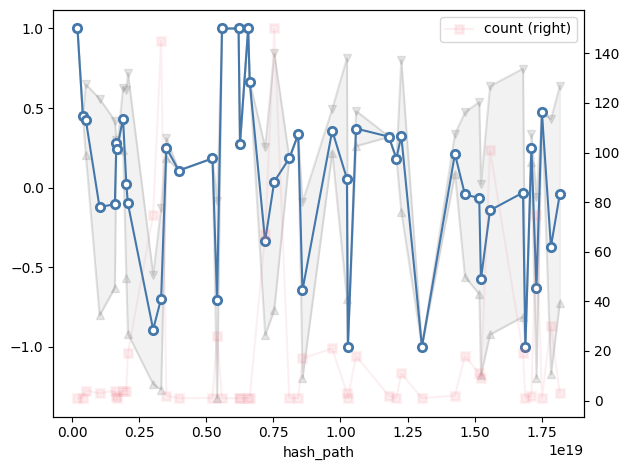

In [136]:
df = cons_gt_eml_data_nodes_cos_sim_text__path_inspect
mean_plus_std = (df['ds_mean'] + df['ds_std_pop'])
mean_min_std = (df['ds_mean'] - df['ds_std_pop'])

plt.fill_between(df.index, mean_min_std, mean_plus_std, color="gray", alpha=0.1)
mean_plus_std.plot(alpha=0.2, marker="v", color="gray")
mean_min_std.plot(alpha=0.2, marker="^", color="gray")
df['ds_mean'].plot(marker="o", markerfacecolor="w", mew=2)
df['ds_count'].plot(alpha=0.1, marker="s", mew=2, secondary_y=True, label="count", legend=True)


plt.tight_layout()

<Axes: xlabel='hash_path'>

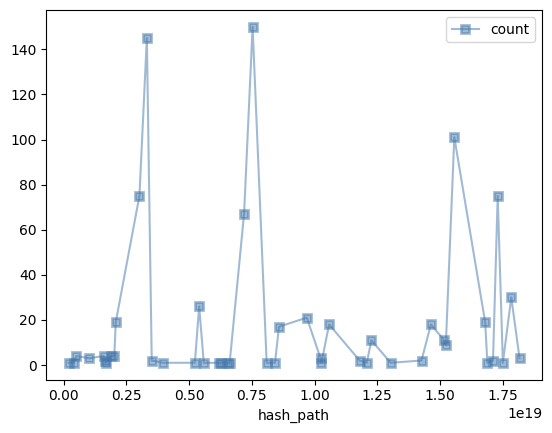

In [137]:
df = cons_gt_eml_data_nodes_cos_sim_text__path_inspect
df['ds_count'].plot(alpha=0.5, marker="s", mew=2, label="count", legend=True)

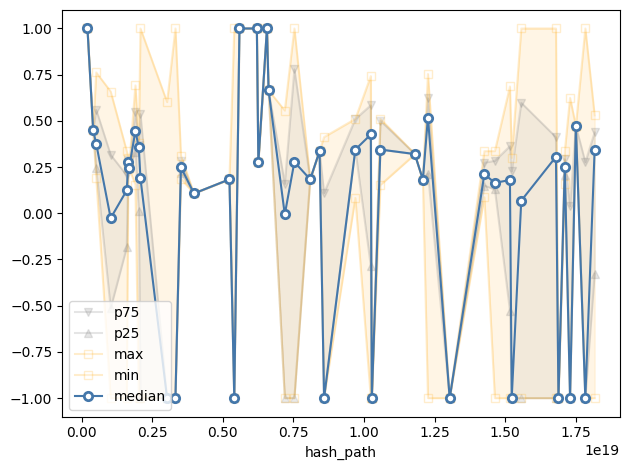

In [138]:
df = cons_gt_eml_data_nodes_cos_sim_text__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)

plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

##### Attributes

In [378]:
cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect.describe(include="all")

,path,tag,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
count,5,5,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
unique,5,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,dataset/project/studyAreaDescription/descriptor,userId,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,36.000000,36.000000,0.180108,0.679918,0.882447,0.429334,0.554173,0.549611,0.850793
std,NaN,NaN,64.093681,64.093681,0.323592,0.568607,0.157742,0.830984,0.872668,0.869875,0.221292
min,NaN,NaN,1.000000,1.000000,0.000000,-0.326917,0.641369,-1.000000,-1.000000,-1.000000,0.483100
25%,NaN,NaN,1.000000,1.000000,0.000000,0.794280,0.800726,0.436759,0.800726,0.800726,0.800726
50%,NaN,NaN,11.000000,11.000000,0.020384,0.952133,0.990047,0.729819,0.990047,0.967233,0.990047
75%,NaN,NaN,17.000000,17.000000,0.129199,0.990047,0.990047,0.990047,0.990047,0.990047,0.990047


In [379]:
cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect.describe(include="all")

,path,tag,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
count,3,3,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
unique,3,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,dataset/project/studyAreaDescription/descriptor,descriptor,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,58.666667,58.666667,0.307975,0.512241,0.819950,0.055526,0.720253,0.255986,0.779109
std,NaN,NaN,77.423080,77.423080,0.401099,0.625050,0.161347,0.925782,0.317767,1.090898,0.222536
min,NaN,NaN,11.000000,11.000000,0.027349,-0.203244,0.669076,-1.000000,0.369986,-1.000000,0.546553
25%,NaN,NaN,14.000000,14.000000,0.078274,0.292295,0.734901,-0.281621,0.585356,-0.099637,0.673640
50%,NaN,NaN,17.000000,17.000000,0.129199,0.787834,0.800726,0.436759,0.800726,0.800726,0.800726
75%,NaN,NaN,82.500000,82.500000,0.448288,0.869983,0.895386,0.583289,0.895386,0.883980,0.895386


In [388]:
display(ttest_ind(
        cons_gt_eml_data_nodes_cos_sim_attributes["cos_sim_attributes"],
        cons_gt_eml_author_nodes_cos_sim_attributes["cos_sim_attributes"],
        equal_var=False
))
display(cohen_d(
        cons_gt_eml_data_nodes_cos_sim_attributes["cos_sim_attributes"],
        cons_gt_eml_author_nodes_cos_sim_attributes["cos_sim_attributes"],
))

TtestResult(statistic=np.float64(-1.0728845334705401), pvalue=np.float64(0.2840537683440412), df=np.float64(353.9910404054173))

np.float64(-0.11371028383934859)

In [383]:
%%sql cons_gt_eml_data_nodes_cos_sim_attributes___spread <<
CREATE OR REPLACE TABLE cons_gt_eml_data_nodes_cos_sim_attributes___spread AS 
    SELECT *, 
        json_extract(eml_data_attrs.gt_attributes::JSON, cons_a.key) AS gt_value,
        cos_sim(cons_a.value, gt_value) AS cons_sim_attr_value
    FROM 
        cons_gt_eml_data_nodes_cos_sim_attributes as eml_data_attrs, 
        json_each(eml_data_attrs.cons_attributes::JSON) as cons_a;
SELECT * FROM cons_gt_eml_data_nodes_cos_sim_attributes___spread

Running query in 'duckdb'

In [380]:
%%sql cons_gt_eml_author_nodes_cos_sim_attributes___spread <<
CREATE OR REPLACE TABLE cons_gt_eml_author_nodes_cos_sim_attributes___spread AS 
    SELECT *, 
        json_extract(eml_author_attrs.gt_attributes::JSON, cons_a.key) AS gt_value,
        cos_sim(cons_a.value, gt_value) AS cons_sim_attr_value
    FROM 
        cons_gt_eml_author_nodes_cos_sim_attributes as eml_author_attrs, 
        json_each(eml_author_attrs.cons_attributes::JSON) as cons_a;
SELECT * FROM cons_gt_eml_author_nodes_cos_sim_attributes___spread

Running query in 'duckdb'

In [384]:
cons_gt_eml_data_nodes_cos_sim_attributes___spread.describe(include="all")

,case_id,path,tag,cons_attributes,gt_attributes,cos_sim_attributes,key,value,type,atom,id,parent,fullkey,path_1,gt_value,cons_sim_attr_value
count,427.000000,427,427,427,427,427.000000,427,427,427,427,427.000000,0.0,427,427,426,426.000000
unique,NaN,5,3,73,154,NaN,6,74,1,74,NaN,<NA>,6,1,162,NaN
top,NaN,.,{https://eml.ecoinformatics.org/eml-2.2.0}eml,"{""packageId"": ""not-derived-000"", ""system"": ""kn...","{""name"": ""generic"", ""citableClassificationSyst...",NaN,system,"""knb""",VARCHAR,"""knb""",NaN,<NA>,$.system,$,"""http://gbif.org""",NaN
freq,NaN,386,386,144,22,NaN,150,149,427,149,NaN,<NA>,150,427,147,NaN
mean,88.721311,NaN,NaN,NaN,NaN,-0.226178,NaN,NaN,NaN,NaN,3.559719,<NA>,NaN,NaN,NaN,0.098361
std,52.520057,NaN,NaN,NaN,NaN,0.803125,NaN,NaN,NaN,NaN,1.517679,<NA>,NaN,NaN,NaN,0.576389
min,0.000000,NaN,NaN,NaN,NaN,-1.000000,NaN,NaN,NaN,NaN,2.000000,<NA>,NaN,NaN,NaN,-1.000000
25%,45.000000,NaN,NaN,NaN,NaN,-1.000000,NaN,NaN,NaN,NaN,2.000000,<NA>,NaN,NaN,NaN,0.188101
50%,88.000000,NaN,NaN,NaN,NaN,-1.000000,NaN,NaN,NaN,NaN,4.000000,<NA>,NaN,NaN,NaN,0.188101
75%,134.000000,NaN,NaN,NaN,NaN,0.563658,NaN,NaN,NaN,NaN,4.000000,<NA>,NaN,NaN,NaN,0.454492


In [382]:
cons_gt_eml_author_nodes_cos_sim_attributes___spread.describe(include="all")

,case_id,path,tag,cons_attributes,gt_attributes,cos_sim_attributes,key,value,type,atom,id,parent,fullkey,path_1,gt_value,cons_sim_attr_value
count,430.00000,430,430,430,430,430.000000,430,430,430,430,430.000000,0.0,430,430,426,426.000000
unique,NaN,3,3,76,152,NaN,6,78,1,78,NaN,<NA>,6,1,161,NaN
top,NaN,.,{https://eml.ecoinformatics.org/eml-2.2.0}eml,"{""packageId"": ""not-derived-000"", ""system"": ""kn...","{""name"": ""generic"", ""citableClassificationSyst...",NaN,system,"""knb""",VARCHAR,"""knb""",NaN,<NA>,$.system,$,"""http://gbif.org""",NaN
freq,NaN,391,391,144,22,NaN,148,147,430,147,NaN,<NA>,148,430,144,NaN
mean,94.10000,NaN,NaN,NaN,NaN,-0.120475,NaN,NaN,NaN,NaN,3.623256,<NA>,NaN,NaN,NaN,0.124689
std,51.06175,NaN,NaN,NaN,NaN,0.801954,NaN,NaN,NaN,NaN,1.544195,<NA>,NaN,NaN,NaN,0.542185
min,0.00000,NaN,NaN,NaN,NaN,-1.000000,NaN,NaN,NaN,NaN,2.000000,<NA>,NaN,NaN,NaN,-1.000000
25%,50.00000,NaN,NaN,NaN,NaN,-1.000000,NaN,NaN,NaN,NaN,2.000000,<NA>,NaN,NaN,NaN,0.188101
50%,98.00000,NaN,NaN,NaN,NaN,0.437834,NaN,NaN,NaN,NaN,4.000000,<NA>,NaN,NaN,NaN,0.188101
75%,139.75000,NaN,NaN,NaN,NaN,0.594829,NaN,NaN,NaN,NaN,4.000000,<NA>,NaN,NaN,NaN,0.454492


In [386]:
display(
    cons_gt_eml_data_nodes_cos_sim_attributes___spread["key"].unique(),
    cons_gt_eml_author_nodes_cos_sim_attributes___spread["key"].unique(),
)

<StringArray>
['{http://www.w3.org/XML/1998/namespace}lang',
                                     'system',
                                  'directory',
                'citableClassificationSystem',
                                  'packageId',
                                       'name']
Length: 6, dtype: str

<StringArray>
['{http://www.w3.org/XML/1998/namespace}lang',
                                     'system',
                                  'directory',
                'citableClassificationSystem',
                                  'packageId',
                                       'name']
Length: 6, dtype: str

In [390]:
shared_tags = list(set.intersection(
    set(cons_gt_eml_data_nodes_cos_sim_attributes["tag"].unique()),
    set(cons_gt_eml_author_nodes_cos_sim_attributes["tag"].unique()),
))

for t in shared_tags:
    print("---")
    print(f"Tag: {t}")
    subdf1 = cons_gt_eml_data_nodes_cos_sim_attributes[cons_gt_eml_data_nodes_cos_sim_attributes["tag"] == t]
    subdf2 = cons_gt_eml_author_nodes_cos_sim_attributes[cons_gt_eml_author_nodes_cos_sim_attributes["tag"] == t]
    display(subdf1.describe().to_latex())
    display(subdf2.describe().to_latex())
    display(ttest_ind(
        subdf1["cos_sim_attributes"], 
        subdf2["cos_sim_attributes"],
        equal_var=False
    ))
    display(mannwhitneyu(
        subdf1["cos_sim_attributes"], 
        subdf2["cos_sim_attributes"],
        alternative="greater"
    ))
    display(cohen_d(
        subdf1["cos_sim_attributes"], 
        subdf2["cos_sim_attributes"],
    ))
    print("---")


---
Tag: descriptor


'\\begin{tabular}{lrr}\n\\toprule\n & case_id & cos_sim_attributes \\\\\n\\midrule\ncount & 11.000000 & 11.000000 \\\\\nmean & 102.272727 & 0.794280 \\\\\nstd & 46.574866 & 0.021379 \\\\\nmin & 34.000000 & 0.729819 \\\\\n25% & 67.000000 & 0.800726 \\\\\n50% & 106.000000 & 0.800726 \\\\\n75% & 133.000000 & 0.800726 \\\\\nmax & 171.000000 & 0.800726 \\\\\n\\bottomrule\n\\end{tabular}\n'

'\\begin{tabular}{lrr}\n\\toprule\n & case_id & cos_sim_attributes \\\\\n\\midrule\ncount & 11.000000 & 11.000000 \\\\\nmean & 89.727273 & 0.787834 \\\\\nstd & 52.579637 & 0.028683 \\\\\nmin & 12.000000 & 0.729819 \\\\\n25% & 54.500000 & 0.800726 \\\\\n50% & 81.000000 & 0.800726 \\\\\n75% & 128.000000 & 0.800726 \\\\\nmax & 168.000000 & 0.800726 \\\\\n\\bottomrule\n\\end{tabular}\n'

TtestResult(statistic=np.float64(0.5976143046672033), pvalue=np.float64(0.5573461181444149), df=np.float64(18.490566037735853))

MannwhitneyuResult(statistic=np.float64(66.0), pvalue=np.float64(0.29054363466407396))

...

'\\begin{tabular}{lrr}\n\\toprule\n & case_id & cos_sim_attributes \\\\\n\\midrule\ncount & 148.000000 & 148.000000 \\\\\nmean & 92.864865 & -0.203244 \\\\\nstd & 50.983477 & 0.769982 \\\\\nmin & 0.000000 & -1.000000 \\\\\n25% & 49.750000 & -1.000000 \\\\\n50% & 96.000000 & 0.369986 \\\\\n75% & 137.250000 & 0.546553 \\\\\nmax & 178.000000 & 0.669076 \\\\\n\\bottomrule\n\\end{tabular}\n'

TtestResult(statistic=np.float64(-1.4011534392822464), pvalue=np.float64(0.16221703973158588), df=np.float64(295.63498083070937))

MannwhitneyuResult(statistic=np.float64(9726.5), pvalue=np.float64(0.9766944950168672))

np.float64(-0.16236062986960104)

---


In [394]:
df1 = cons_gt_eml_data_nodes_cos_sim_attributes___spread
df2 = cons_gt_eml_author_nodes_cos_sim_attributes___spread

shared_keys = list(set.intersection(
    set(df1["key"].unique()),
    set(df2["key"].unique()),
))

for k in sorted(shared_keys):
    print("---")
    print(f"Key: {k}")
    subdf1 = df1[df1["key"] == k]
    subdf2 = df2[df2["key"] == k]
    display(subdf1.describe().to_latex())
    display(subdf2.describe().to_latex())
    display(ttest_ind(
        subdf1["cons_sim_attr_value"], 
        subdf2["cons_sim_attr_value"],
        equal_var=False
    ))
    display(mannwhitneyu(
        subdf1["cons_sim_attr_value"], 
        subdf2["cons_sim_attr_value"],
        alternative="greater"
    ))
    display(cohen_d(
        subdf1["cons_sim_attr_value"], 
        subdf2["cons_sim_attr_value"],
    ))
    print("---")


---
Key: citableClassificationSystem


'\\begin{tabular}{lrrrrr}\n\\toprule\n & case_id & cos_sim_attributes & id & parent & cons_sim_attr_value \\\\\n\\midrule\ncount & 11.000000 & 11.000000 & 11.000000 & 0.000000 & 11.000000 \\\\\nmean & 102.272727 & 0.794280 & 4.000000 & NaN & 1.000000 \\\\\nstd & 46.574866 & 0.021379 & 0.000000 & NaN & 0.000000 \\\\\nmin & 34.000000 & 0.729819 & 4.000000 & NaN & 1.000000 \\\\\n25% & 67.000000 & 0.800726 & 4.000000 & NaN & 1.000000 \\\\\n50% & 106.000000 & 0.800726 & 4.000000 & NaN & 1.000000 \\\\\n75% & 133.000000 & 0.800726 & 4.000000 & NaN & 1.000000 \\\\\nmax & 171.000000 & 0.800726 & 4.000000 & NaN & 1.000000 \\\\\n\\bottomrule\n\\end{tabular}\n'

'\\begin{tabular}{lrrrrr}\n\\toprule\n & case_id & cos_sim_attributes & id & parent & cons_sim_attr_value \\\\\n\\midrule\ncount & 11.000000 & 11.000000 & 11.000000 & 0.000000 & 11.000000 \\\\\nmean & 89.727273 & 0.787834 & 4.000000 & NaN & 1.000000 \\\\\nstd & 52.579637 & 0.028683 & 0.000000 & NaN & 0.000000 \\\\\nmin & 12.000000 & 0.729819 & 4.000000 & NaN & 1.000000 \\\\\n25% & 54.500000 & 0.800726 & 4.000000 & NaN & 1.000000 \\\\\n50% & 81.000000 & 0.800726 & 4.000000 & NaN & 1.000000 \\\\\n75% & 128.000000 & 0.800726 & 4.000000 & NaN & 1.000000 \\\\\nmax & 168.000000 & 0.800726 & 4.000000 & NaN & 1.000000 \\\\\n\\bottomrule\n\\end{tabular}\n'

/Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:592: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


TtestResult(statistic=np.float64(nan), pvalue=np.float64(nan), df=np.float64(1.0))

...

'\\begin{tabular}{lrrrrr}\n\\toprule\n & case_id & cos_sim_attributes & id & parent & cons_sim_attr_value \\\\\n\\midrule\ncount & 95.000000 & 95.000000 & 95.000000 & 0.000000 & 92.000000 \\\\\nmean & 100.821053 & -0.264867 & 6.000000 & NaN & 0.461477 \\\\\nstd & 51.393761 & 0.796143 & 0.000000 & NaN & 0.085176 \\\\\nmin & 0.000000 & -1.000000 & 6.000000 & NaN & 0.346782 \\\\\n25% & 64.000000 & -1.000000 & 6.000000 & NaN & 0.454492 \\\\\n50% & 110.000000 & -1.000000 & 6.000000 & NaN & 0.454492 \\\\\n75% & 143.500000 & 0.593046 & 6.000000 & NaN & 0.454492 \\\\\nmax & 176.000000 & 0.669076 & 6.000000 & NaN & 1.000000 \\\\\n\\bottomrule\n\\end{tabular}\n'

TtestResult(statistic=np.float64(nan), pvalue=np.float64(nan), df=np.float64(nan))

MannwhitneyuResult(statistic=np.float64(nan), pvalue=np.float64(nan))

np.float64(-0.03398719283886078)

---


<Axes: xlabel='hash_path'>

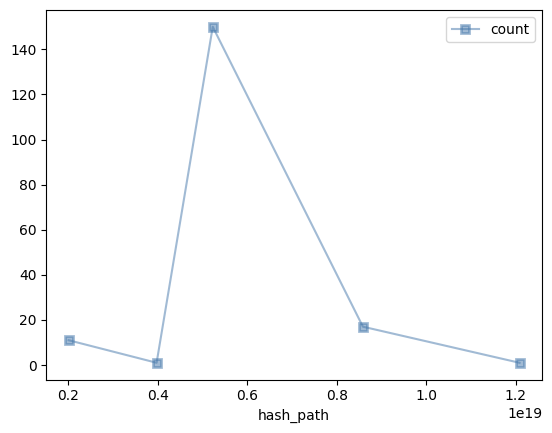

In [139]:
df = cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect
df['ds_count'].plot(alpha=0.5, marker="s", mew=2, label="count", legend=True)

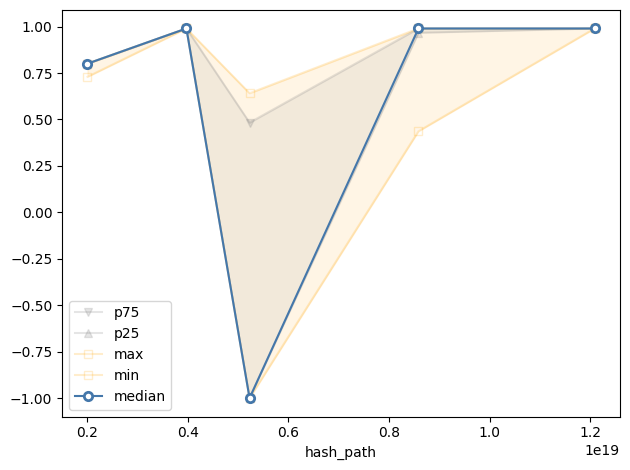

In [140]:
df = cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)

plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

<Axes: xlabel='hash_path'>

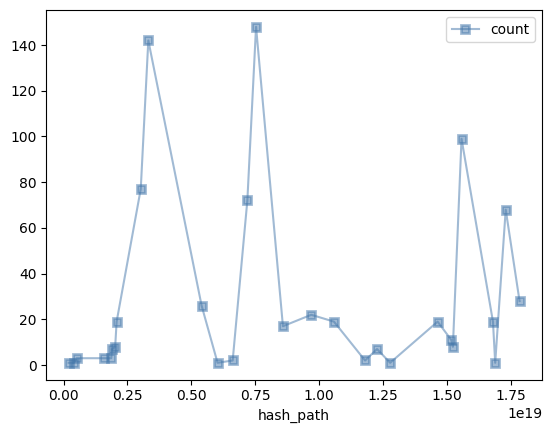

In [141]:
df = cons_gt_eml_author_nodes_cos_sim_text__path_inspect
df['ds_count'].plot(alpha=0.5, marker="s", mew=2, label="count", legend=True)

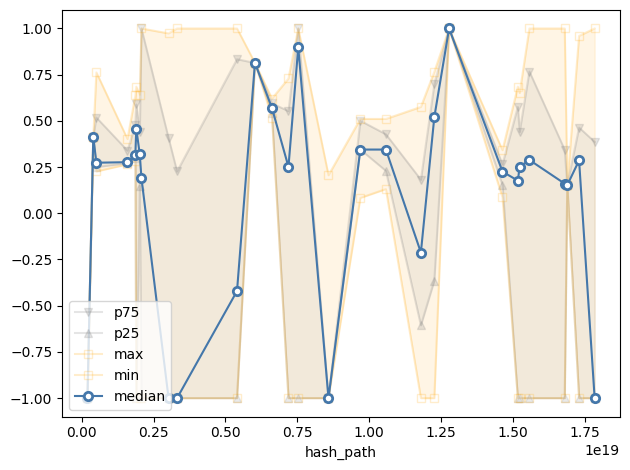

In [142]:
df = cons_gt_eml_author_nodes_cos_sim_text__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)

plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

<Axes: xlabel='hash_path'>

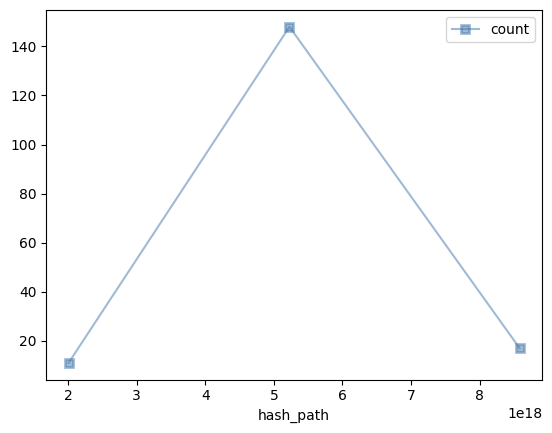

In [143]:
df = cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect
df['ds_count'].plot(alpha=0.5, marker="s", mew=2, label="count", legend=True)

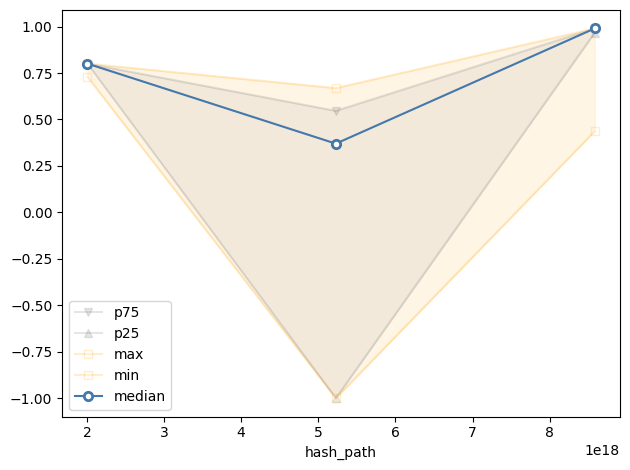

In [144]:
df = cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)

plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

#### Compare EML Data vs Author



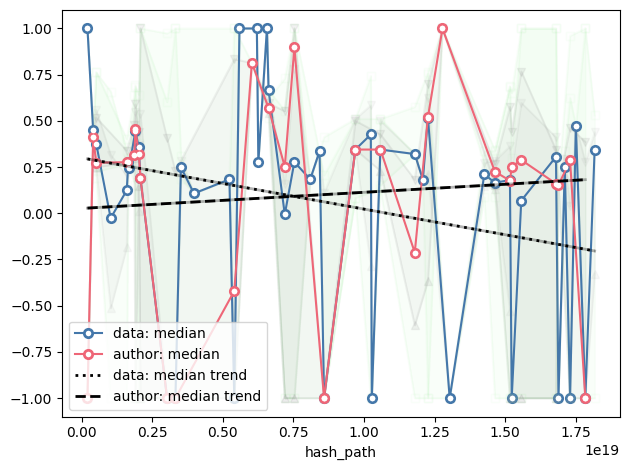

In [145]:
df1 = cons_gt_eml_data_nodes_cos_sim_text__path_inspect
df2 = cons_gt_eml_author_nodes_cos_sim_text__path_inspect

# data
plt.fill_between(df1.index, df1["ds_max"], df1["ds_min"], color="lightgreen", alpha=0.05)
plt.fill_between(df1.index, df1["ds_p75_cont"], df1["ds_p25_cont"], color="gray", alpha=0.05)
df1["ds_p75_cont"].plot(alpha=0.05, marker="v", color="gray", label="", legend=True)
df1["ds_p25_cont"].plot(alpha=0.05, marker="^", color="gray", label="", legend=True)
df1['ds_min'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df1['ds_max'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df1['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="data: median", legend=True)

# author
plt.fill_between(df2.index, df2["ds_max"], df2["ds_min"], color="lightgreen", alpha=0.05)
plt.fill_between(df2.index, df2["ds_p75_cont"], df2["ds_p25_cont"], color="gray", alpha=0.05)
df2["ds_p75_cont"].plot(alpha=0.1, marker="v", color="gray", label="", legend=True)
df2["ds_p25_cont"].plot(alpha=0.1, marker="^", color="gray", label="", legend=True)
df2['ds_min'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df2['ds_max'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df2['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="author: median", legend=True)

# trends
m, b = np.polyfit(df1.index, df1['ds_med_cont'], 1)
plt.plot(df1.index, df1['ds_med_cont'], 'w.')
plt.plot(df1.index, m*df1.index+b, '-k', alpha=0.3, markersize=0, lw=2, zorder=100, label="")
plt.plot(df1.index, m*df1.index+b, ':k', markersize=0, lw=2, zorder=100, label="data: median trend")

m, b = np.polyfit(df2.index, df2['ds_med_cont'], 1)
plt.plot(df2.index, df2['ds_med_cont'], 'w.')
plt.plot(df2.index, m*df2.index+b, '-k', alpha=0.3, markersize=0, lw=2, zorder=100, label="")
plt.plot(df2.index, m*df2.index+b, '--k', markersize=0, lw=2, zorder=100, label="author: median trend")

leg = plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

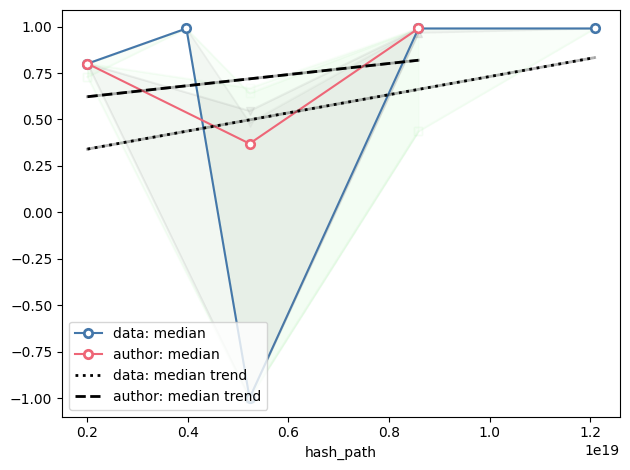

In [146]:
df1 = cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect
df2 = cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect

# data
plt.fill_between(df1.index, df1["ds_max"], df1["ds_min"], color="lightgreen", alpha=0.05)
plt.fill_between(df1.index, df1["ds_p75_cont"], df1["ds_p25_cont"], color="gray", alpha=0.05)
df1["ds_p75_cont"].plot(alpha=0.05, marker="v", color="gray", label="", legend=True)
df1["ds_p25_cont"].plot(alpha=0.05, marker="^", color="gray", label="", legend=True)
df1['ds_min'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df1['ds_max'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df1['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="data: median", legend=True)

# author
plt.fill_between(df2.index, df2["ds_max"], df2["ds_min"], color="lightgreen", alpha=0.05)
plt.fill_between(df2.index, df2["ds_p75_cont"], df2["ds_p25_cont"], color="gray", alpha=0.05)
df2["ds_p75_cont"].plot(alpha=0.1, marker="v", color="gray", label="", legend=True)
df2["ds_p25_cont"].plot(alpha=0.1, marker="^", color="gray", label="", legend=True)
df2['ds_min'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df2['ds_max'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df2['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="author: median", legend=True)

# trends
m, b = np.polyfit(df1.index, df1['ds_med_cont'], 1)
plt.plot(df1.index, df1['ds_med_cont'], 'w.')
plt.plot(df1.index, m*df1.index+b, '-k', alpha=0.3, markersize=0, lw=2, zorder=100, label="")
plt.plot(df1.index, m*df1.index+b, ':k', markersize=0, lw=2, zorder=100, label="data: median trend")

m, b = np.polyfit(df2.index, df2['ds_med_cont'], 1)
plt.plot(df2.index, df2['ds_med_cont'], 'w.')
plt.plot(df2.index, m*df2.index+b, '-k', alpha=0.3, markersize=0, lw=2, zorder=100, label="")
plt.plot(df2.index, m*df2.index+b, '--k', markersize=0, lw=2, zorder=100, label="author: median trend")

leg = plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

delta_med.shape=(49,)
delta_med.count()=np.int64(26)
26


,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
199826611885047600,dataset/contact/individualName/surName,1,1,0.0,1.0,1.0,1.0,1.0,1.0,1.0


,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
17299146993214317173,dataset/methods/qualityControl/description/para,75,75,0.567065,-0.629016,0.624716,-1.0,-1.0,-1.0,0.038558


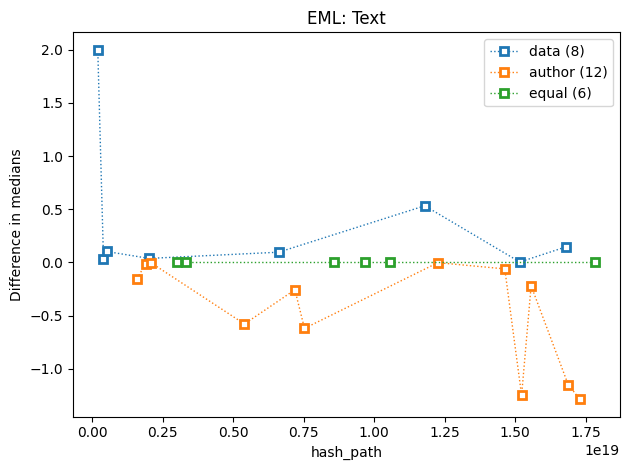


--> top10: data is better:


count    8.000000
mean     0.369207
std      0.680006
min      0.003557
25%      0.037055
50%      0.099369
75%      0.242399
max      2.000000
Name: ds_med_cont, dtype: float64

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
199826611885047600,dataset/contact/individualName/surName,1,1,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
6617235638686593906,dataset/coverage/geographicCoverage/geographic...,1,1,0.000000,0.665401,0.665401,0.665401,0.665401,0.665401,0.665401
402660203177841723,dataset/intellectualRights/para,1,1,0.000000,0.448450,0.448450,0.448450,0.448450,0.448450,0.448450
509835330926488103,dataset/project/personnel[3]/individualName/su...,4,4,0.223230,0.426960,0.762364,0.192765,0.376356,0.243538,0.559777
2019908457384792944,dataset/methods/methodStep[2]/description/para,4,4,0.590884,0.023251,0.380618,-1.000000,0.356193,0.011313,0.368132
11797055351399041090,dataset/project/abstract/para,2,2,0.001916,0.320465,0.322380,0.318549,0.320465,0.319507,0.321422
16800044395398089788,dataset/project/personnel[2]/individualName/su...,19,19,0.779483,-0.031273,1.000000,-1.000000,0.305944,-1.000000,0.411671
15168855418924349169,dataset/project/studyAreaDescription/descripto...,11,11,0.603237,-0.065364,0.686205,-1.000000,0.180205,-0.527652,0.363356


,path,tag,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,,
6617235638686593906,dataset/coverage/geographicCoverage/geographic...,geographicDescription,2,2,0.051234,0.569407,0.620641,0.518173,0.569407,0.543790,0.595024
402660203177841723,dataset/intellectualRights/para,para,1,1,0.000000,0.412951,0.412951,0.412951,0.412951,0.412951,0.412951
2019908457384792944,dataset/methods/methodStep[2]/description/para,para,8,8,0.475642,0.181310,0.641698,-1.000000,0.318620,0.149469,0.437744
509835330926488103,dataset/project/personnel[3]/individualName/su...,surName,3,3,0.242257,0.420839,0.762364,0.226543,0.273612,0.250077,0.517988
15168855418924349169,dataset/project/studyAreaDescription/descripto...,descriptorValue,11,11,0.716490,-0.081720,0.685300,-1.000000,0.176647,-1.000000,0.575361
16800044395398089788,dataset/project/personnel[2]/individualName/su...,surName,19,19,0.732979,-0.181264,1.000000,-1.000000,0.160292,-1.000000,0.343256
11797055351399041090,dataset/project/abstract/para,para,2,2,0.787828,-0.212172,0.575656,-1.000000,-0.212172,-0.606086,0.181742
199826611885047600,dataset/contact/individualName/surName,surName,1,1,0.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000



--> top10: author is better:


...

,path,tag,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,,
7531383348528985230,dataset/title,title,148,148,0.850766,0.355745,1.000000,-1.000000,0.898597,-1.000000,1.000000
12264083121720851709,dataset/abstract/para,para,7,7,0.735035,0.135898,0.765518,-1.000000,0.520462,-0.364512,0.697165
1897832894039290149,dataset/methods/methodStep[1]/description/para,para,7,7,0.784412,-0.096990,0.685324,-1.000000,0.458055,-1.000000,0.588847
15570285937076544010,dataset/project/title,title,99,99,0.767199,0.108792,1.000000,-1.000000,0.288596,-1.000000,0.767225
17299146993214317173,dataset/methods/qualityControl/description/para,para,68,68,0.734628,-0.147510,0.959998,-1.000000,0.286073,-1.000000,0.463871
1591939635604457060,dataset/project/personnel[3]/role,role,3,3,0.061981,0.314523,0.401923,0.265040,0.276606,0.270823,0.339264
7191309023196111392,dataset/methods/methodStep/description/para,para,72,72,0.714828,-0.099486,0.729353,-1.000000,0.251303,-1.000000,0.552717
15232234705173613974,dataset/maintenance/description/para,para,8,8,0.701074,-0.113371,0.650771,-1.000000,0.250901,-1.000000,0.440560
14635275423761931014,dataset/project/personnel[2]/role,role,19,19,0.077124,0.217014,0.341561,0.085831,0.225492,0.152788,0.264587



--> top10: equal:


count    6.0
mean     0.0
std      0.0
min      0.0
25%      0.0
50%      0.0
75%      0.0
max      0.0
Name: ds_med_cont, dtype: float64

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
9691641318081825809,dataset/project/personnel/role,21,21,0.137727,0.358203,0.510540,0.083198,0.344871,0.344871,0.510540
10579610229072948010,dataset/project/personnel[1]/role,18,18,0.110259,0.371270,0.510540,0.152777,0.344871,0.344871,0.500554
3020556172879687003,dataset/project/funding/para,75,75,0.343801,-0.891729,0.601685,-1.000000,-1.000000,-1.000000,-1.000000
3316978768188658723,dataset/maintenance/maintenanceUpdateFrequency,145,145,0.571771,-0.697019,1.000000,-1.000000,-1.000000,-1.000000,-1.000000
8583186042160731940,dataset/creator/userId,17,17,0.553747,-0.644776,0.412435,-1.000000,-1.000000,-1.000000,0.110061
17840357754191769060,dataset/creator/individualName/surName,30,30,0.801275,-0.370711,1.000000,-1.000000,-1.000000,-1.000000,0.276321


,path,tag,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,,
9691641318081825809,dataset/project/personnel/role,role,22,22,0.126390,0.360870,0.510540,0.083198,0.344871,0.344871,0.500554
10579610229072948010,dataset/project/personnel[1]/role,role,19,19,0.130121,0.324028,0.510540,0.131206,0.344871,0.229844,0.427706
3020556172879687003,dataset/project/funding/para,para,77,77,0.746508,-0.366999,0.973497,-1.000000,-1.000000,-1.000000,0.406846
3316978768188658723,dataset/maintenance/maintenanceUpdateFrequency,maintenanceUpdateFrequency,142,142,0.667261,-0.394899,1.000000,-1.000000,-1.000000,-1.000000,0.226280
8583186042160731940,dataset/creator/userId,userId,17,17,0.283711,-0.929072,0.205773,-1.000000,-1.000000,-1.000000,-1.000000
17840357754191769060,dataset/creator/individualName/surName,surName,28,28,0.832641,-0.256875,1.000000,-1.000000,-1.000000,-1.000000,0.386458


In [147]:
df1 = cons_gt_eml_data_nodes_cos_sim_text__path_inspect
df2 = cons_gt_eml_author_nodes_cos_sim_text__path_inspect

# plt.subplots(figsize=(4.2, 2.8), dpi=300)
plt.title("EML: Text")
plt.ylabel("Difference in medians")

delta_med = (df1["ds_med_cont"] - df2["ds_med_cont"])
print(f"{delta_med.shape=}")
print(f"{delta_med.count()=}")
print(f"{len(set.intersection(set(df1.index), set(df2.index)))}")

display(df1.loc[delta_med.nlargest(1).index])
display(df1.loc[delta_med.nsmallest(1).index])


dw = (delta_med[delta_med > 0])
aw = (delta_med[delta_med < 0])
eq = (delta_med[delta_med == 0])
dw.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(0), label=f"data ({dw.count()})", legend=True)
aw.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(1), label=f"author ({aw.count()})", legend=True)
eq.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(2), label=f"equal ({eq.count()})", legend=True)

plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

print("\n--> top10: data is better:")
display(delta_med[delta_med > 0].describe())
data_bs1 = df1.loc[delta_med[delta_med > 0].index]
data_bs2 = df2.loc[delta_med[delta_med > 0].index]
display(data_bs1[data_bs1["case_count"] > 0].nlargest(20, columns=["ds_med_cont"]))
display(data_bs2[data_bs2["case_count"] > 0].nlargest(20, columns=["ds_med_cont"]))

print("\n--> top10: author is better:")
display(delta_med[delta_med < 0].describe())
author_bs1 = df1.loc[delta_med[delta_med < 0].index]
author_bs2 = df2.loc[delta_med[delta_med < 0].index]
display(author_bs1[author_bs1["case_count"] > 0].nlargest(20, columns=["ds_med_cont"]))
display(author_bs2[author_bs2["case_count"] > 0].nlargest(20, columns=["ds_med_cont"]))

print("\n--> top10: equal:")
display(delta_med[delta_med == 0].describe())
equal_bs1 = df1.loc[delta_med[delta_med == 0].index]
equal_bs2 = df2.loc[delta_med[delta_med == 0].index]
display(equal_bs1[equal_bs1["case_count"] > 0].nlargest(20, columns=["ds_med_cont"]))
display(equal_bs2[equal_bs2["case_count"] > 0].nlargest(20, columns=["ds_med_cont"]))

delta_med.shape=(5,)
delta_med.count()=np.int64(3)
3


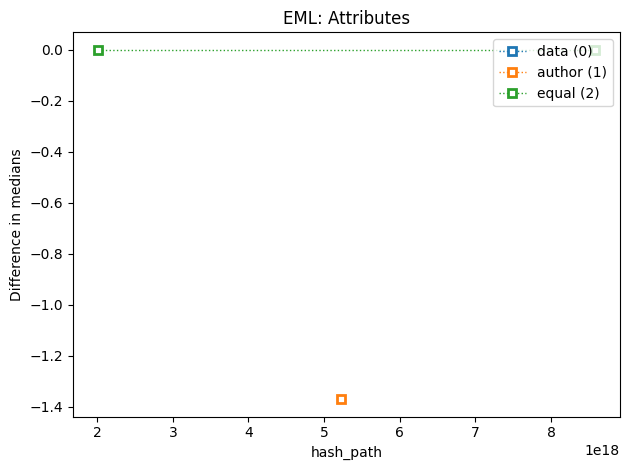


--> top10: data is better:


count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: ds_med_cont, dtype: float64

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,


,path,tag,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,,



--> top10: author is better:


...

,path,tag,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,,
5227831486160219788,.,{https://eml.ecoinformatics.org/eml-2.2.0}eml,148,148,0.767376,-0.203244,0.669076,-1.0,0.369986,-1.0,0.546553



--> top10: equal:


count    2.0
mean     0.0
std      0.0
min      0.0
25%      0.0
50%      0.0
75%      0.0
max      0.0
Name: ds_med_cont, dtype: float64

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
8583186042160731940,dataset/creator/userId,17,17,0.129199,0.952133,0.990047,0.436759,0.990047,0.967233,0.990047
2007448060941507434,dataset/project/studyAreaDescription/descriptor,11,11,0.020384,0.794280,0.800726,0.729819,0.800726,0.800726,0.800726


,path,tag,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,,
8583186042160731940,dataset/creator/userId,userId,17,17,0.129199,0.952133,0.990047,0.436759,0.990047,0.967233,0.990047
2007448060941507434,dataset/project/studyAreaDescription/descriptor,descriptor,11,11,0.027349,0.787834,0.800726,0.729819,0.800726,0.800726,0.800726


In [148]:
df1 = cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect
df2 = cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect

# plt.subplots(figsize=(4.2, 2.8), dpi=300)
plt.title("EML: Attributes")
plt.ylabel("Difference in medians")

delta_med = (df1["ds_med_cont"] - df2["ds_med_cont"])
print(f"{delta_med.shape=}")
print(f"{delta_med.count()=}")
print(f"{len(set.intersection(set(df1.index), set(df2.index)))}")


dw = (delta_med[delta_med > 0])
aw = (delta_med[delta_med < 0])
eq = (delta_med[delta_med == 0])
dw.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(0), label=f"data ({dw.count()})", legend=True)
aw.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(1), label=f"author ({aw.count()})", legend=True)
eq.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(2), label=f"equal ({eq.count()})", legend=True)

plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

print("\n--> top10: data is better:")
display(delta_med[delta_med > 0].describe())
data_bs1 = df1.loc[delta_med[delta_med > 0].index]
data_bs2 = df2.loc[delta_med[delta_med > 0].index]
display(data_bs1[data_bs1["case_count"] > 1].nlargest(10, columns=["ds_med_cont"]))
display(data_bs2[data_bs2["case_count"] > 1].nlargest(10, columns=["ds_med_cont"]))

print("\n--> top10: author is better:")
display(delta_med[delta_med < 0].describe())
author_bs1 = df1.loc[delta_med[delta_med < 0].index]
author_bs2 = df2.loc[delta_med[delta_med < 0].index]
display(author_bs1[author_bs1["case_count"] > 1].nlargest(10, columns=["ds_med_cont"]))
display(author_bs2[author_bs2["case_count"] > 1].nlargest(10, columns=["ds_med_cont"]))

print("\n--> top10: equal:")
display(delta_med[delta_med == 0].describe())
equal_bs1 = df1.loc[delta_med[delta_med == 0].index]
equal_bs2 = df2.loc[delta_med[delta_med == 0].index]
display(equal_bs1[equal_bs1["case_count"] > 1].nlargest(10, columns=["ds_med_cont"]))
display(equal_bs2[equal_bs2["case_count"] > 1].nlargest(10, columns=["ds_med_cont"]))

### Exploratory materials

> EML - Text

In [149]:
%%sql
SELECT c.path, c.case_id, c.cons_has_text, c.cons_text, c.gt_has_text, c.gt_text
FROM shared_cons_gt_eml_author_nodes AS c
WHERE (NOT cons_has_text) AND gt_has_text;

Running query in 'duckdb'

,path,case_id,cons_has_text,cons_text,gt_has_text,gt_text
0,dataset/abstract,0,False,\n,True,\n The present work provides an inv...
1,dataset/abstract,21,False,\n,True,\n Specimen data to accompany: Thér...
2,dataset/abstract,4,False,\n,True,\n This dataset contains the first ...


In [150]:
%%sql
SELECT c.path, c.case_id, c.cons_has_text, c.cons_text, c.gt_has_text, c.gt_text
FROM shared_cons_gt_eml_data_nodes AS c
WHERE (cons_has_text) AND (NOT gt_has_text);

Running query in 'duckdb'

,path,case_id,cons_has_text,cons_text,gt_has_text,gt_text
0,dataset/maintenance/description/para,0,True,Dataset status: not-derived-010,False,NaN
1,additionalMetadata/metadata,0,True,\n not-derived-012\n,False,\n
2,dataset/maintenance/description/para,10,True,Dataset status: not-derived-010,False,NaN
3,additionalMetadata/metadata,10,True,\n not-derived-012\n,False,\n
4,dataset/maintenance/description/para,100,True,Dataset status: not-derived-010,False,NaN
...,...,...,...,...,...,...
207,additionalMetadata/metadata,95,True,\n not-derived-012\n,False,\n
208,dataset/maintenance/description/para,126,True,Dataset status: not-derived-010,False,NaN
209,dataset/methods/methodStep/description/para,126,True,not-derived-004,False,NaN
210,dataset/maintenance/description/para,128,True,Dataset status: not-derived-010,False,NaN


In [151]:
%%sql
SELECT c.path, c.case_id, c.cons_has_text, c.cons_text, c.gt_has_text, c.gt_text
FROM shared_cons_gt_eml_author_nodes AS c
WHERE (cons_has_text) AND (NOT gt_has_text);

Running query in 'duckdb'

,path,case_id,cons_has_text,cons_text,gt_has_text,gt_text
0,dataset/maintenance/description/para,0,True,Dataset status: not-derived-010,False,NaN
1,additionalMetadata/metadata,0,True,"\n identificationRemarks = ""Morphospecie'...",False,\n
2,dataset/maintenance/description/para,10,True,Dataset status: not-derived-010,False,NaN
3,dataset/project/personnel/role,10,True,Principal Investigator,False,NaN
4,additionalMetadata/metadata,10,True,\n not-derived-012\n,False,\n
...,...,...,...,...,...,...
214,dataset/maintenance/description/para,128,True,Dataset status: not-derived-010,False,NaN
215,additionalMetadata/metadata,128,True,\n not-derived-012\n,False,\n
216,dataset/maintenance/description/para,98,True,Dataset status: not-derived-010,False,NaN
217,additionalMetadata/metadata,98,True,\n No additional narrative metadata beyon...,False,\n


> EML - Atributes

> False Positives

In [152]:
%%sql
SELECT c.path, c.case_id, c.cons_has_attributes, c.cons_attributes, c.gt_has_attributes, c.gt_attributes
FROM shared_cons_gt_eml_author_nodes AS c
WHERE (c.cons_has_attributes) AND (NOT c.gt_has_attributes);

Running query in 'duckdb'

,path,case_id,cons_has_attributes,cons_attributes,gt_has_attributes,gt_attributes
0,dataset,112,True,"{""id"": ""aedes_collection_dataset""}",False,{}
1,additionalMetadata,115,True,"{""id"": ""am-1""}",False,{}
2,additionalMetadata,139,True,"{""id"": ""am1""}",False,{}
3,dataset,144,True,"{""id"": ""dataset-1""}",False,{}
4,additionalMetadata,144,True,"{""id"": ""am-1""}",False,{}
5,additionalMetadata,163,True,"{""id"": ""am-001""}",False,{}
6,additionalMetadata,169,True,"{""id"": ""addl-1""}",False,{}
7,additionalMetadata,34,True,"{""id"": ""am-1""}",False,{}
8,additionalMetadata,39,True,"{""id"": ""am-1""}",False,{}
9,additionalMetadata,50,True,"{""id"": ""am-1""}",False,{}


In [153]:
%%sql
SELECT DISTINCT c.path
FROM shared_cons_gt_eml_author_nodes AS c
WHERE (c.cons_has_attributes) AND (NOT c.gt_has_attributes);

Running query in 'duckdb'

,path
0,dataset
1,additionalMetadata


In [154]:
%%sql
SELECT c.path, c.case_id, c.cons_has_attributes, c.cons_attributes, c.gt_has_attributes, c.gt_attributes
FROM shared_cons_gt_eml_data_nodes AS c
WHERE (c.cons_has_attributes) AND (NOT c.gt_has_attributes);

Running query in 'duckdb'

,path,case_id,cons_has_attributes,cons_attributes,gt_has_attributes,gt_attributes
0,additionalMetadata,100,True,"{""id"": ""am-1""}",False,{}
1,additionalMetadata,125,True,"{""id"": ""am-1""}",False,{}
2,additionalMetadata,137,True,"{""id"": ""ext-1""}",False,{}
3,additionalMetadata,151,True,"{""id"": ""am-1""}",False,{}
4,dataset,169,True,"{""id"": ""203-37e24322-a8b9-3f3f-8686-4fa43445dc...",False,{}
5,additionalMetadata,18,True,"{""id"": ""am-1""}",False,{}
6,additionalMetadata,21,True,"{""id"": ""customExtensions""}",False,{}
7,additionalMetadata,29,True,"{""id"": ""am1""}",False,{}
8,additionalMetadata,3,True,"{""id"": ""am-1""}",False,{}
9,additionalMetadata,39,True,"{""id"": ""am1""}",False,{}


In [155]:
%%sql
SELECT DISTINCT c.path
FROM shared_cons_gt_eml_author_nodes AS c
WHERE (c.cons_has_attributes) AND (NOT c.gt_has_attributes);

Running query in 'duckdb'

,path
0,dataset
1,additionalMetadata


> False Negatives

In [156]:
%%sql
SELECT c.path, c.case_id, c.cons_has_attributes, c.cons_attributes, c.gt_has_attributes, c.gt_attributes
FROM shared_cons_gt_eml_author_nodes AS c
WHERE (NOT c.cons_has_attributes) AND (c.gt_has_attributes);

Running query in 'duckdb'

,path,case_id,cons_has_attributes,cons_attributes,gt_has_attributes,gt_attributes
0,dataset/title,0,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
1,dataset/project,0,False,{},True,"{""id"": ""COASTAL ECOSYSTEMS""}"
2,dataset/title,10,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
3,dataset/project,10,False,{},True,"{""id"": ""IDIT""}"
4,dataset/title,100,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
...,...,...,...,...,...,...
192,dataset/title,128,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
193,dataset/title,129,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
194,dataset/project,98,False,{},True,"{""id"": ""LIFEWATCH-2019-09-CSIC-4, POPE 2014-20..."
195,dataset/title,99,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."


In [157]:
%%sql
SELECT DISTINCT c.path
FROM shared_cons_gt_eml_author_nodes AS c
WHERE (NOT c.cons_has_attributes) AND (c.gt_has_attributes);

Running query in 'duckdb'

,path
0,dataset/title
1,dataset/project


In [158]:
%%sql
SELECT DISTINCT gt_attributes
FROM shared_cons_gt_eml_author_nodes AS c
WHERE (NOT c.cons_has_attributes) AND (c.gt_has_attributes);

Running query in 'duckdb'

,gt_attributes
0,"{""id"": ""MOVECLIM - AZORES""}"
1,"{""id"": ""gov.noaa.nmfs.inport:70769""}"
2,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
3,"{""id"": ""https://sibmyco.org/collections/inatur..."
4,"{""id"": ""LIFEWATCH-2019-09-CSIC-4, POPE 2014-20..."
5,"{""id"": ""nlbif2021.003""}"
6,"{""id"": ""University of Bucharest""}"
7,"{""id"": ""2022.01/0013""}"
8,"{""id"": ""DB-F-44""}"
9,"{""id"": ""mosquitoalert""}"


In [159]:
%%sql
SELECT c.path, c.case_id, c.cons_has_attributes, c.cons_attributes, c.gt_has_attributes, c.gt_attributes
FROM shared_cons_gt_eml_data_nodes AS c
WHERE (NOT c.cons_has_attributes) AND (c.gt_has_attributes);

Running query in 'duckdb'

,path,case_id,cons_has_attributes,cons_attributes,gt_has_attributes,gt_attributes
0,dataset/title,0,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
1,dataset/project,0,False,{},True,"{""id"": ""COASTAL ECOSYSTEMS""}"
2,dataset/title,10,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
3,dataset/project,10,False,{},True,"{""id"": ""IDIT""}"
4,dataset/title,100,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
...,...,...,...,...,...,...
193,dataset/title,95,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
194,dataset/title,97,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
195,dataset/title,98,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
196,dataset/title,128,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."


In [160]:
%%sql
SELECT DISTINCT c.path
FROM shared_cons_gt_eml_data_nodes AS c
WHERE (NOT c.cons_has_attributes) AND (c.gt_has_attributes);

Running query in 'duckdb'

,path
0,dataset/project
1,dataset/title
2,dataset/distribution
3,dataset/distribution/online/url


In [161]:
%%sql
SELECT DISTINCT gt_attributes
FROM shared_cons_gt_eml_data_nodes AS c
WHERE (NOT c.cons_has_attributes) AND (c.gt_has_attributes);

Running query in 'duckdb'

,gt_attributes
0,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
1,"{""id"": ""https://sibmyco.org/collections/inatur..."
2,"{""id"": ""LIFEWATCH-2019-09-CSIC-4, POPE 2014-20..."
3,"{""id"": ""University of Bucharest""}"
4,"{""scope"": ""document""}"
5,"{""id"": ""PRIBES-SLAM""}"
6,"{""id"": ""MOVECLIM - AZORES""}"
7,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
8,"{""id"": ""BioBlitz Azores""}"
9,"{""id"": ""PICT 01-11749""}"


> DwC-T

In [162]:
%%sql
SELECT c.path, c.tag, c.case_id, c.cons_has_attributes, c.cons_attributes, c.gt_has_attributes, c.gt_attributes
FROM shared_cons_gt_dwc_t_author_nodes AS c
WHERE (cons_has_attributes) AND (NOT gt_has_attributes);

Running query in 'duckdb'

,path,tag,case_id,cons_has_attributes,cons_attributes,gt_has_attributes,gt_attributes
0,.,{http://rs.tdwg.org/dwc/text/}archive,111,True,"{""metadata"": ""not-derived-001""}",False,{}
1,.,{http://rs.tdwg.org/dwc/text/}archive,124,True,"{""metadata"": ""not-derived-001""}",False,{}
2,.,{http://rs.tdwg.org/dwc/text/}archive,52,True,"{""metadata"": ""not-derived-001""}",False,{}


In [163]:
%%sql
SELECT c.path, c.tag, c.case_id, c.cons_has_attributes, c.cons_attributes, c.gt_has_attributes, c.gt_attributes
FROM shared_cons_gt_dwc_t_data_nodes AS c
WHERE (cons_has_attributes) AND (NOT gt_has_attributes);

Running query in 'duckdb'

,path,tag,case_id,cons_has_attributes,cons_attributes,gt_has_attributes,gt_attributes
0,.,{http://rs.tdwg.org/dwc/text/}archive,111,True,"{""metadata"": ""meta.xml""}",False,{}
1,.,{http://rs.tdwg.org/dwc/text/}archive,124,True,"{""metadata"": ""meta.xml""}",False,{}
2,.,{http://rs.tdwg.org/dwc/text/}archive,52,True,"{""metadata"": ""meta.xml""}",False,{}


In [164]:
%%sql
SELECT c.path, c.cons_attributes, c.gt_attributes, COUNT(1)
FROM shared_cons_gt_dwc_t_data_nodes AS c
WHERE c.path = '.'
GROUP BY 1,2,3;

Running query in 'duckdb'

,path,cons_attributes,gt_attributes,count(1)
0,.,"{""metadata"": ""not-derived-001""}","{""metadata"": ""eml.xml""}",59
1,.,"{""metadata"": ""meta.xml""}","{""metadata"": ""eml.xml""}",109
2,.,"{""metadata"": ""GAP_001""}","{""metadata"": ""eml.xml""}",1
3,.,"{""metadata"": ""Ascorhynchus hippos Turpaeva, 19...","{""metadata"": ""eml.xml""}",1
4,.,"{""metadata"": ""1""}","{""metadata"": ""eml.xml""}",1
5,.,"{""metadata"": ""meta.xml""}",{},3


In [165]:
%%sql
SELECT c.path, c.cons_attributes, c.gt_attributes, AVG(cos_sim_attributes), COUNT(1)
FROM cons_gt_dwc_t_author_nodes_cos_sim_attributes AS c
WHERE c.path = '.'
GROUP BY 1,2,3;

Running query in 'duckdb'

,path,cons_attributes,gt_attributes,avg(cos_sim_attributes),count(1)
0,.,"{""metadata"": ""not-derived-001""}","{""metadata"": ""eml.xml""}",-1.000000,134
1,.,"{""metadata"": ""omit the `metadata` attribute""}","{""metadata"": ""eml.xml""}",0.635781,1
2,.,"{""metadata"": ""not-derived-001` is unavailable....","{""metadata"": ""eml.xml""}",-1.000000,1
3,.,"{""metadata"": ""omit or leave empty""}","{""metadata"": ""eml.xml""}",0.531999,1
4,.,"{""metadata"": ""meta.xml""}","{""metadata"": ""eml.xml""}",0.771236,30
5,.,"{""metadata"": ""https://doi.org/10.15468/gwr8mg""}","{""metadata"": ""eml.xml""}",0.557783,1
6,.,"{""metadata"": ""omit the metadata attribute""}","{""metadata"": ""eml.xml""}",0.635459,2
7,.,"{""metadata"": ""https://www.gbif.org/dataset/e9a...","{""metadata"": ""eml.xml""}",0.533566,1


In [166]:
compute_cos_similarity("not-derived-001", "eml.xml")

-1

In [167]:
%%sql
SELECT c.path, c.cons_attributes, c.gt_attributes, AVG(cos_sim_attributes), COUNT(1)
FROM cons_gt_dwc_t_data_nodes_cos_sim_attributes AS c
WHERE c.path = '.'
GROUP BY 1,2,3;

Running query in 'duckdb'

,path,cons_attributes,gt_attributes,avg(cos_sim_attributes),count(1)
0,.,"{""metadata"": ""not-derived-001""}","{""metadata"": ""eml.xml""}",-1.000000,59
1,.,"{""metadata"": ""meta.xml""}","{""metadata"": ""eml.xml""}",0.771236,109
2,.,"{""metadata"": ""GAP_001""}","{""metadata"": ""eml.xml""}",0.542274,1
3,.,"{""metadata"": ""1""}","{""metadata"": ""eml.xml""}",0.677672,1
4,.,"{""metadata"": ""Ascorhynchus hippos Turpaeva, 19...","{""metadata"": ""eml.xml""}",0.424147,1


In [168]:
%%sql
WITH distinct_root_gt_attributes AS (
  SELECT DISTINCT (c.gt_attributes :: JSON) AS gt_attributes_json
  FROM cons_gt_dwc_t_data_nodes_cos_sim_attributes AS c
  WHERE c.path = '.'
)
SELECT *
FROM distinct_root_gt_attributes as attr, json_each(attr.gt_attributes_json)

Running query in 'duckdb'

,gt_attributes_json,key,value,type,atom,id,parent,fullkey,path
0,"{""metadata"": ""eml.xml""}",metadata,"""eml.xml""",VARCHAR,"""eml.xml""",2,<NA>,$.metadata,$


In [169]:
%%sql
WITH distinct_root_gt_attributes AS (
  SELECT DISTINCT (c.gt_attributes :: JSON) AS gt_attributes_json
  FROM cons_gt_dwc_t_data_nodes_cos_sim_attributes AS c
)
SELECT DISTINCT key
FROM distinct_root_gt_attributes as attr, json_each(attr.gt_attributes_json)

Running query in 'duckdb'

,key
0,encoding
1,rowType
2,index
3,term
4,delimitedBy
5,ignoreHeaderLines
6,fieldsEnclosedBy
7,linesTerminatedBy
8,metadata
9,fieldsTerminatedBy


In [170]:
%%sql cons_gt_eml_author_nodes_cos_sim_text__dataset_title <<
SELECT c.path,
    c.case_id,
    cons_text, gt_text,
    cos_sim_text
FROM cons_gt_eml_author_nodes_cos_sim_text AS c
WHERE c.path = 'dataset/title'
ORDER BY cos_sim_text DESC;



Running query in 'duckdb'

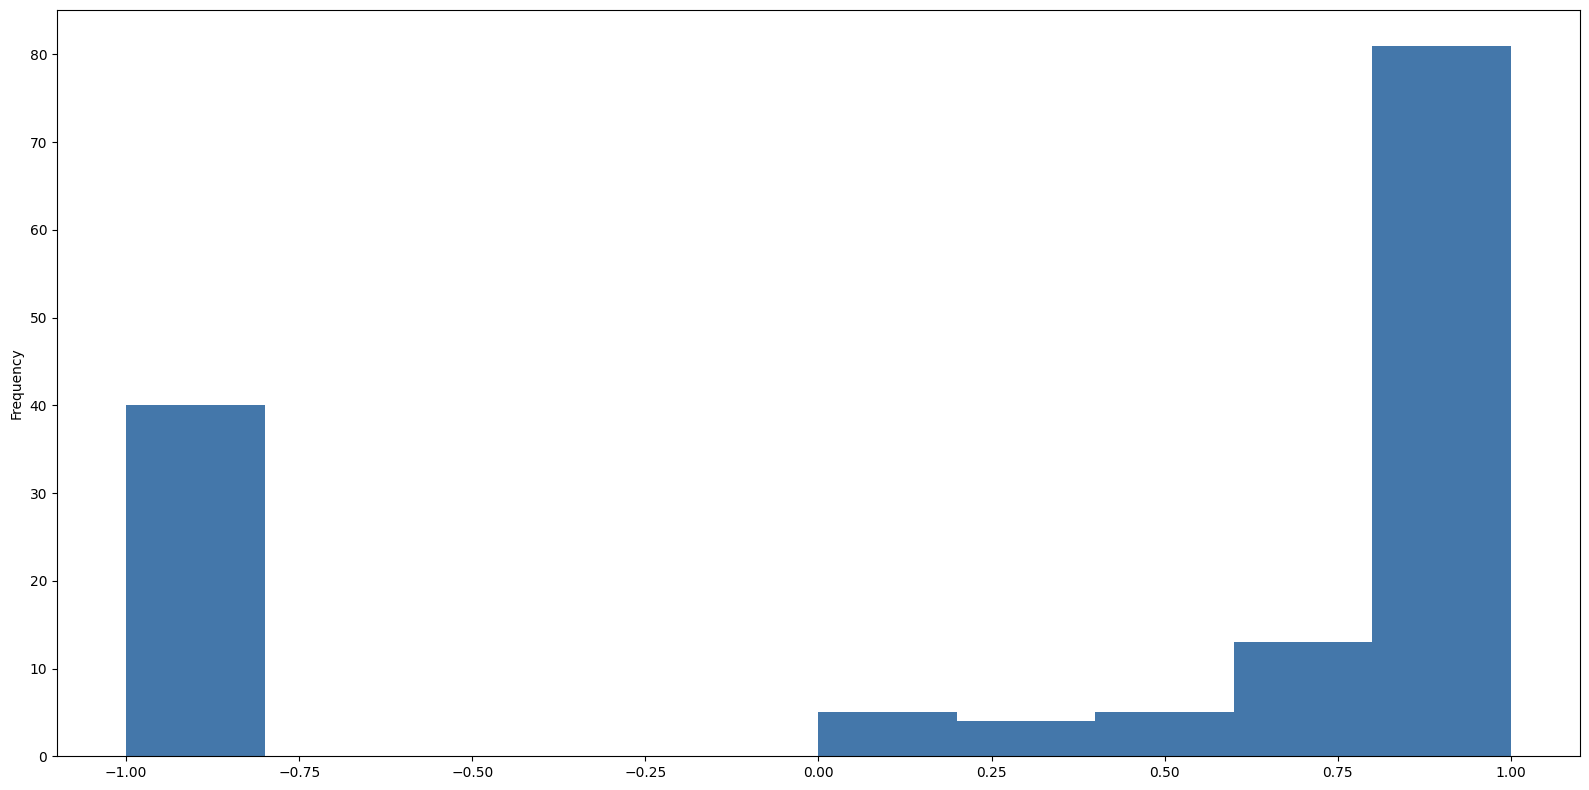

In [171]:
fig, ax = plt.subplots(figsize=(16,8))
cons_gt_eml_author_nodes_cos_sim_text__dataset_title["cos_sim_text"].plot.hist(ax=ax)
plt.tight_layout()

In [172]:
%%sql
SELECT c.path, ds_mean, ds_med_cont, ds_count
FROM cons_gt_eml_data_nodes_cos_sim_text__path_inspect AS c
ORDER BY ds_med_cont DESC;

Running query in 'duckdb'

,path,ds_mean,ds_med_cont,ds_count
0,dataset/coverage/temporalCoverage/rangeOfDates...,1.000000,1.000000,1
1,dataset/contact/individualName/givenName,1.000000,1.000000,1
2,dataset/coverage/temporalCoverage/rangeOfDates...,1.000000,1.000000,1
3,dataset/contact/individualName/surName,1.000000,1.000000,1
4,dataset/coverage/geographicCoverage/geographic...,0.665401,0.665401,1
5,dataset/abstract/para,0.326020,0.518044,11
6,dataset/project/personnel[7]/individualName/su...,0.472188,0.472188,1
7,dataset/intellectualRights/para,0.448450,0.448450,1
8,dataset/methods/methodStep[1]/description/para,0.433870,0.444099,4
9,dataset/methods/sampling/studyExtent/descripti...,0.056372,0.426475,3


In [173]:
%%sql
SELECT c.path, ds_mean, ds_med_cont, ds_count
FROM cons_gt_eml_author_nodes_cos_sim_text__path_inspect AS c
ORDER BY ds_med_cont DESC;


Running query in 'duckdb'

,path,ds_mean,ds_med_cont,ds_count
0,dataset/project/personnel[1]/individualName/gi...,1.000000,1.000000,1
1,dataset/title,0.355745,0.898597,148
2,dataset/project/personnel[2]/individualName/gi...,0.813631,0.813631,1
3,dataset/coverage/geographicCoverage/geographic...,0.569407,0.569407,2
4,dataset/abstract/para,0.135898,0.520462,7
5,dataset/methods/methodStep[1]/description/para,-0.096990,0.458055,7
6,dataset/intellectualRights/para,0.412951,0.412951,1
7,dataset/project/personnel[1]/role,0.324028,0.344871,19
8,dataset/project/personnel/role,0.360870,0.344871,22
9,dataset/methods/methodStep[2]/description/para,0.181310,0.318620,8


In [174]:
%%sql
SELECT c.path, c.cons_attributes, c.gt_attributes, AVG(cos_sim_attributes), COUNT(1)
FROM cons_gt_eml_data_nodes_cos_sim_attributes AS c
WHERE c.path = '.'
GROUP BY 1,2,3;

Running query in 'duckdb'

,path,cons_attributes,gt_attributes,avg(cos_sim_attributes),count(1)
0,.,"{""packageId"": ""urn:uuid:8e4a1f2f-7f9e-4d8f-9a7...","{""{http://www.w3.org/2001/XMLSchema-instance}s...",0.467374,1
1,.,"{""packageId"": ""urn:uuid:4d2c7d3b-5d8f-4c8a-9c9...","{""{http://www.w3.org/2001/XMLSchema-instance}s...",0.448000,1
2,.,"{""packageId"": ""urn:uuid:6d4c6f39-5b5a-4a8e-9a2...","{""{http://www.w3.org/2001/XMLSchema-instance}s...",0.559338,1
3,.,"{""packageId"": ""not-derived-000"", ""system"": ""kn...","{""{http://www.w3.org/2001/XMLSchema-instance}s...",-1.000000,1
4,.,"{""packageId"": ""not-derived-000"", ""system"": ""knb""}","{""{http://www.w3.org/2001/XMLSchema-instance}s...",-1.000000,1
...,...,...,...,...,...
145,.,"{""packageId"": ""https://doi.org/10.1016/j.actat...","{""{http://www.w3.org/2001/XMLSchema-instance}s...",0.601250,1
146,.,"{""packageId"": ""not-derived-013"", ""system"": ""kn...","{""{http://www.w3.org/2001/XMLSchema-instance}s...",-1.000000,1
147,.,"{""packageId"": ""not-derived-013"", ""system"": ""kn...","{""{http://www.w3.org/2001/XMLSchema-instance}s...",-1.000000,1
148,.,"{""packageId"": ""not-derived-000"", ""system"": ""kn...","{""{http://www.w3.org/2001/XMLSchema-instance}s...",-1.000000,1


In [175]:
%%sql
SELECT c.path, c.cons_attributes, c.gt_attributes, AVG(cos_sim_attributes), COUNT(1)
FROM cons_gt_eml_author_nodes_cos_sim_attributes AS c
WHERE c.path = 'dataset/creator/userId'
GROUP BY 1,2,3;

Running query in 'duckdb'

,path,cons_attributes,gt_attributes,avg(cos_sim_attributes),count(1)
0,dataset/creator/userId,"{""directory"": ""https://orcid.org""}","{""directory"": ""https://orcid.org/""}",0.990047,12
1,dataset/creator/userId,"{""directory"": ""https://orcid.org""}","{""directory"": ""http://scholar.google.com/citat...",0.436759,1
2,dataset/creator/userId,"{""directory"": ""https://orcid.org""}","{""directory"": ""http://orcid.org/""}",0.967233,4


In [176]:
%%sql
SELECT c.path, c.cons_attributes, c.gt_attributes, AVG(cos_sim_attributes), COUNT(1)
FROM cons_gt_eml_data_nodes_cos_sim_attributes AS c
WHERE c.path IN ('dataset/creator/userId','dataset/creator[1]/userId','dataset/creator[2]/userId')
GROUP BY 1,2,3;

Running query in 'duckdb'

,path,cons_attributes,gt_attributes,avg(cos_sim_attributes),count(1)
0,dataset/creator/userId,"{""directory"": ""https://orcid.org""}","{""directory"": ""http://orcid.org/""}",0.967233,4
1,dataset/creator/userId,"{""directory"": ""https://orcid.org""}","{""directory"": ""https://orcid.org/""}",0.990047,12
2,dataset/creator[1]/userId,"{""directory"": ""https://orcid.org""}","{""directory"": ""https://orcid.org/""}",0.990047,1
3,dataset/creator/userId,"{""directory"": ""https://orcid.org""}","{""directory"": ""http://scholar.google.com/citat...",0.436759,1
4,dataset/creator[2]/userId,"{""directory"": ""https://orcid.org""}","{""directory"": ""https://orcid.org/""}",0.990047,1


In [177]:
%%sql
SELECT c.path, c.cons_attributes, c.gt_attributes, AVG(cos_sim_attributes), COUNT(1)
FROM cons_gt_eml_author_nodes_cos_sim_attributes AS c
WHERE c.path = 'dataset/project/studyAreaDescription/descriptor'
GROUP BY 1,2,3;

Running query in 'duckdb'

,path,cons_attributes,gt_attributes,avg(cos_sim_attributes),count(1)
0,dataset/project/studyAreaDescription/descriptor,"{""name"": ""study_area"", ""citableClassificationS...","{""name"": ""generic"", ""citableClassificationSyst...",0.729819,2
1,dataset/project/studyAreaDescription/descriptor,"{""name"": ""habitat_type"", ""citableClassificatio...","{""name"": ""generic"", ""citableClassificationSyst...",0.800726,9


In [178]:
%%sql
SELECT c.path, c.cons_attributes, c.gt_attributes, AVG(cos_sim_attributes), COUNT(1)
FROM cons_gt_eml_data_nodes_cos_sim_attributes AS c
WHERE c.path = 'dataset/project/studyAreaDescription/descriptor'
GROUP BY 1,2,3;

Running query in 'duckdb'

,path,cons_attributes,gt_attributes,avg(cos_sim_attributes),count(1)
0,dataset/project/studyAreaDescription/descriptor,"{""name"": ""habitat_type"", ""citableClassificatio...","{""name"": ""generic"", ""citableClassificationSyst...",0.800726,10
1,dataset/project/studyAreaDescription/descriptor,"{""name"": ""study_area"", ""citableClassificationS...","{""name"": ""generic"", ""citableClassificationSyst...",0.729819,1


## Metrics

### DwC-T

In [179]:
%%sql dwc_t_data_sim_sem_text <<
-- DwC-T::data -> SIM_{sem}^{Text}
SELECT 
    1 - (
        SUM(acos(cos_sim_text::DECIMAL))
        / (pi() * COUNT(1))
    ) AS sim_sem_text,
    COUNT(1) AS tp_count
FROM cons_gt_dwc_t_data_nodes_cos_sim_text
GROUP BY case_id;

Running query in 'duckdb'

In [180]:
%%sql dwc_t_author_sim_sem_text <<
-- DwC-T::author -> SIM_{sem}^{Text}
SELECT 
    1 - (
        SUM(acos(cos_sim_text::DECIMAL))
        / (pi() * COUNT(1))
    ) AS sim_sem_text,
    COUNT(1) AS tp_count
FROM cons_gt_dwc_t_author_nodes_cos_sim_text
GROUP BY case_id;

Running query in 'duckdb'

In [181]:
%%sql dwc_t_data_sim_sem_attributes <<
-- DwC-T::data -> SIM_{sem}^{Attrs}
SELECT 
    1 - (
        SUM(acos(cos_sim_attributes::DECIMAL))
        / (pi() * COUNT(1))
    ) AS sim_sem_attrs,
    COUNT(1) AS tp_count
FROM cons_gt_dwc_t_data_nodes_cos_sim_attributes
GROUP BY case_id;

Running query in 'duckdb'

In [182]:
%%sql dwc_t_author_sim_sem_attributes <<
-- DwC-T::author -> SIM_{sem}^{Attrs}
SELECT 
    1 - (
        SUM(acos(cos_sim_attributes::DECIMAL))
        / (pi() * COUNT(1))
    ) AS sim_sem_attrs,
    COUNT(1) AS tp_count
FROM cons_gt_dwc_t_author_nodes_cos_sim_attributes
GROUP BY case_id;

Running query in 'duckdb'

--- dwc_t_data_sim_sem_text ---


,sim_sem_text,tp_count
count,174.000000,174.000000
mean,0.954288,1.534483
std,0.099797,0.685494
min,0.670355,1.000000
25%,1.000000,1.000000
50%,1.000000,1.000000
75%,1.000000,2.000000
max,1.000000,4.000000


--- dwc_t_author_sim_sem_text ---


,sim_sem_text,tp_count
count,174.000000,174.000000
mean,0.942086,1.551724
std,0.112711,0.692797
min,0.670355,1.000000
25%,1.000000,1.000000
50%,1.000000,1.000000
75%,1.000000,2.000000
max,1.000000,4.000000


<Axes: ylabel='Frequency'>

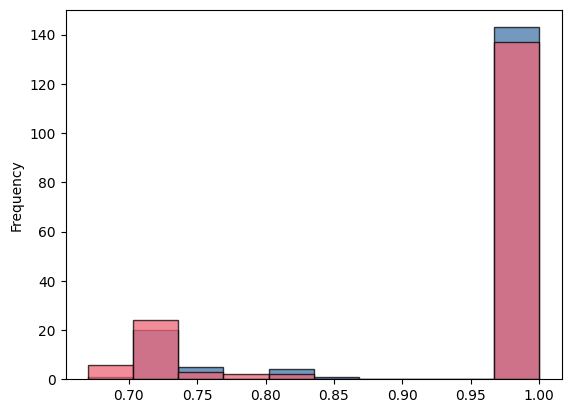

In [183]:
print("--- dwc_t_data_sim_sem_text ---")
display(dwc_t_data_sim_sem_text.describe())
print("--- dwc_t_author_sim_sem_text ---")
display(dwc_t_author_sim_sem_text.describe())

dwc_t_data_sim_sem_text["sim_sem_text"].plot.hist(alpha=0.75, edgecolor="k")
dwc_t_author_sim_sem_text["sim_sem_text"].plot.hist(alpha=0.75, edgecolor="k")

--- dwc_t_data_sim_sem_attributes ---


,sim_sem_attrs,tp_count
count,174.000000,174.000000
mean,0.932890,44.517241
std,0.071416,21.854412
min,0.662726,10.000000
25%,0.929269,31.000000
50%,0.965072,41.000000
75%,0.982573,51.750000
max,0.997074,186.000000


--- dwc_t_author_sim_sem_attributes ---


,sim_sem_attrs,tp_count
count,174.000000,174.000000
mean,0.916496,44.316092
std,0.075456,21.589659
min,0.716349,10.000000
25%,0.893152,30.250000
50%,0.950723,41.000000
75%,0.967401,51.750000
max,0.990628,184.000000


<Axes: ylabel='Frequency'>

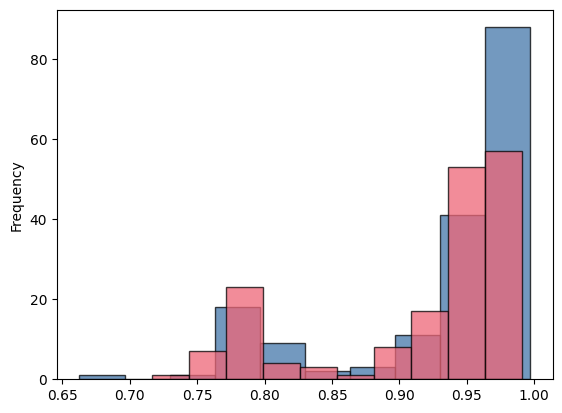

In [184]:
print("--- dwc_t_data_sim_sem_attributes ---")
display(dwc_t_data_sim_sem_attributes.describe())
print("--- dwc_t_author_sim_sem_attributes ---")
display(dwc_t_author_sim_sem_attributes.describe())

dwc_t_data_sim_sem_attributes["sim_sem_attrs"].plot.hist(alpha=0.75, edgecolor="k")
dwc_t_author_sim_sem_attributes["sim_sem_attrs"].plot.hist(alpha=0.75, edgecolor="k")

### EML

In [185]:
%%sql
SELECT MIN(cos_sim_text::DECIMAL), MAX(cos_sim_text::DECIMAL)
FROM cons_gt_eml_data_nodes_cos_sim_text

Running query in 'duckdb'

,min(CAST(cos_sim_text AS DECIMAL)),max(CAST(cos_sim_text AS DECIMAL))
0,-1.0,1.0


In [186]:
%%sql
SELECT MIN(cos_sim_text::DECIMAL), MAX(cos_sim_text::DECIMAL)
FROM cons_gt_eml_author_nodes_cos_sim_text

Running query in 'duckdb'

,min(CAST(cos_sim_text AS DECIMAL)),max(CAST(cos_sim_text AS DECIMAL))
0,-1.0,1.0


In [187]:
%%sql
SELECT cos_sim_text, cons_text, gt_text
FROM cons_gt_eml_data_nodes_cos_sim_text
WHERE cos_sim_text::DECIMAL > 1

Running query in 'duckdb'

,cos_sim_text,cons_text,gt_text


In [188]:
%%sql eml_data_sim_sem_text <<
-- EML::data -> SIM_{sem}^{Text}
SELECT 
    1 - (
        SUM(acos(cos_sim_text::DECIMAL))
        / (pi() * COUNT(1))
    ) AS sim_sem_text,
    COUNT(1) AS tp_count
FROM cons_gt_eml_data_nodes_cos_sim_text
GROUP BY case_id;

Running query in 'duckdb'

In [189]:
%%sql eml_author_sim_sem_text <<
-- EML::author -> SIM_{sem}^{Text}
SELECT 
    1 - (
        SUM(acos(cos_sim_text::DECIMAL))
        / (pi() * COUNT(1))
    ) AS sim_sem_text,
    COUNT(1) AS tp_count
FROM cons_gt_eml_author_nodes_cos_sim_text
GROUP BY case_id;

Running query in 'duckdb'

In [190]:
%%sql eml_data_sim_sem_attributes <<
-- EML::data -> SIM_{sem}^{Attrs}
SELECT 
    1 - (
        SUM(acos(cos_sim_attributes::DECIMAL))
        / (pi() * COUNT(1))
    ) AS sim_sem_attrs,
    COUNT(1) AS tp_count
FROM cons_gt_eml_data_nodes_cos_sim_attributes
GROUP BY case_id;

Running query in 'duckdb'

In [191]:
%%sql eml_author_sim_sem_attributes <<
-- EML::author -> SIM_{sem}^{Attrs}
SELECT 
    1 - (
        SUM(acos(cos_sim_attributes::DECIMAL))
        / (pi() * COUNT(1))
    ) AS sim_sem_attrs,
    COUNT(1) AS tp_count
FROM cons_gt_eml_author_nodes_cos_sim_attributes
GROUP BY case_id;

Running query in 'duckdb'

--- eml_data_sim_sem_text ---


,sim_sem_text,tp_count
count,150.000000,150.000000
mean,0.306522,5.760000
std,0.219318,3.099426
min,0.000000,1.000000
25%,0.159421,4.000000
50%,0.279768,6.000000
75%,0.420391,7.000000
max,1.000000,22.000000


--- eml_author_sim_sem_text ---


,sim_sem_text,tp_count
count,148.000000,148.000000
mean,0.430468,5.635135
std,0.206977,2.745804
min,0.000000,1.000000
25%,0.314931,3.000000
50%,0.442731,5.000000
75%,0.576317,8.000000
max,1.000000,12.000000


<Axes: ylabel='Frequency'>

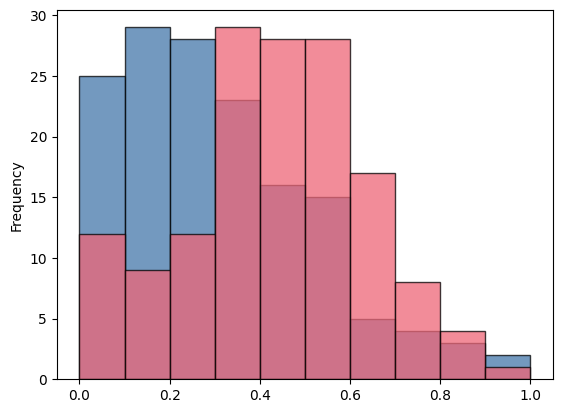

In [192]:
print("--- eml_data_sim_sem_text ---")
display(eml_data_sim_sem_text.describe())
print("--- eml_author_sim_sem_text ---")
display(eml_author_sim_sem_text.describe())

eml_data_sim_sem_text["sim_sem_text"].plot.hist(alpha=0.75, edgecolor="k")
eml_author_sim_sem_text["sim_sem_text"].plot.hist(alpha=0.75, edgecolor="k")

--- eml_data_sim_sem_attributes ---


,sim_sem_attrs,tp_count
count,150.000000,150.000000
mean,0.346931,1.200000
std,0.337972,0.433497
min,0.000000,1.000000
25%,0.000000,1.000000
50%,0.458999,1.000000
75%,0.682049,1.000000
max,0.835946,3.000000


--- eml_author_sim_sem_attributes ---


,sim_sem_attrs,tp_count
count,148.000000,148.000000
mean,0.396438,1.189189
std,0.336044,0.426205
min,0.000000,1.000000
25%,0.000000,1.000000
50%,0.621671,1.000000
75%,0.700281,1.000000
max,0.830288,3.000000


<Axes: ylabel='Frequency'>

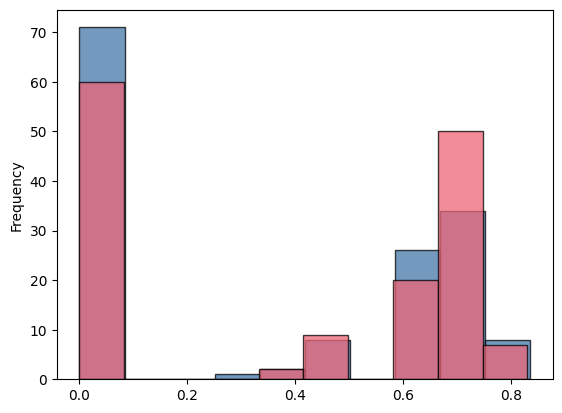

In [193]:
print("--- eml_data_sim_sem_attributes ---")
display(eml_data_sim_sem_attributes.describe())
print("--- eml_author_sim_sem_attributes ---")
display(eml_author_sim_sem_attributes.describe())

eml_data_sim_sem_attributes["sim_sem_attrs"].plot.hist(alpha=0.75, edgecolor="k")
eml_author_sim_sem_attributes["sim_sem_attrs"].plot.hist(alpha=0.75, edgecolor="k")